# EDA Customer Churn: Daftar Isi

Analisis eksploratif *Iranian Churn Dataset*. Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan.

1. **Persiapan:** import, tema grafik, konteks dataset, dan inspeksi awal
2. **Bagian 1, Persiapan Data dan Cek Kualitas:** duplikat, nama kolom, dan cek kualitas data
3. **Bagian 2, Analisis Univariat:** distribusi fitur, distribusi target, dan outlier
4. **Bagian 3, Hubungan Fitur dengan Churn:** bivariat, asosiasi, dan multikolinearitas
5. **Bagian 4, Segmentasi dan Pertanyaan Bisnis:** segmentasi, kombinasi dua fitur, pertanyaan bisnis, dan ringkasan eksekutif

# Import Paket dan Modul

In [1]:
from itertools import combinations
from math import ceil
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.gridspec import GridSpec
from scipy.stats import chi2_contingency, gaussian_kde, kruskal, pointbiserialr
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import confint_proportions_2indep
from statsmodels.tools.tools import add_constant

plt.style.use('seaborn-v0_8-darkgrid')

SEED = 180915
TARGET = 'Churn'

print("Semua Import Berhasil")

Semua Import Berhasil


# Tema Grafik

In [2]:
def apply_dark_theme():
    """Panggil sekali di cell pertama notebook — ini bagian yang benar-benar universal."""
    BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = "#0f1117", "#1a1d27", "#e8eaf0", "#2e3250"
    plt.rcParams.update({
        "figure.facecolor": BG_COLOR, "axes.facecolor": PANEL_COLOR,
        "axes.edgecolor": GRID_COLOR, "axes.labelcolor": TEXT_COLOR,
        "axes.titlecolor": TEXT_COLOR, "xtick.color": TEXT_COLOR,
        "ytick.color": TEXT_COLOR, "text.color": TEXT_COLOR,
        "grid.color": GRID_COLOR, "grid.linestyle": "--",
        "grid.alpha": 0.4, "font.family": "monospace",
        "legend.facecolor": PANEL_COLOR, "legend.edgecolor": GRID_COLOR,
        "legend.labelcolor": TEXT_COLOR,
    })
    return BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR

BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = apply_dark_theme()

# Fungsi Bersama

Label dan pembagian kuartil yang dipakai di bagian segmentasi.

In [3]:
QUARTILE_LABELS = ['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
SUBSCRIPTION_LABELS = ['Pendek', 'Sedang', 'Panjang', 'Sangat Panjang']
BIN_COLUMNS = ['Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers',
               'Customer_Value', 'Call_Failure', 'Subscription_Length']
CATEGORY_LABELS = {
    'Complains': {0: 'Tanpa Komplain', 1: 'Komplain'},
    'Status': {1: 'Aktif', 2: 'Non-aktif'},
    'Tariff_Plan': {1: 'Pay as you go', 2: 'Kontrak'},
    'Age_Group': {1: 'Usia 15', 2: 'Usia 25', 3: 'Usia 30', 4: 'Usia 45', 5: 'Usia 55'},
}


def add_quartile_bins(data):
    # Salinan data dengan kolom kuartil berakhiran _bin
    result = data.copy()
    for col in BIN_COLUMNS:
        labels = SUBSCRIPTION_LABELS if col == 'Subscription_Length' else QUARTILE_LABELS
        result[f'{col}_bin'] = pd.qcut(result[col], q=4, labels=labels, duplicates='drop')
    return result


def add_segment_columns(data):
    # Salinan data dengan kolom kuartil dan label kategori berakhiran _lbl
    result = add_quartile_bins(data)
    for col, mapping in CATEGORY_LABELS.items():
        result[f'{col}_lbl'] = result[col].map(mapping)
    return result


def clean_name(col):
    return col.replace('_lbl', '').replace('_bin', '').replace('_', ' ')


def format_p(p_value):
    # p-value sangat kecil tidak ditulis sebagai nol
    return '< 0.001' if p_value < 0.001 else f'{p_value:.4f}'

# Konteks dan Metodologi Dataset

**Sumber Data**

Dataset ini dikumpulkan secara acak dari basis data sebuah perusahaan telekomunikasi di Iran selama periode 12 bulan. Data terdiri atas 3.150 baris, dengan setiap baris merepresentasikan satu pelanggan, dan 13 kolom atribut.

**Atribut Dataset**

Atribut yang tersedia meliputi Call Failure, Frequency of SMS, Complains, Distinct Called Numbers, Subscription Length, Age Group, Charge Amount, Tariff Plan, Seconds of Use, Status, Frequency of Use, Age, dan Customer Value.

**Struktur Temporal dan Planning Gap**

Seluruh atribut prediktor (di luar target Churn) merupakan hasil agregasi dari 9 bulan pertama periode pengamatan. Label target Churn diukur pada akhir bulan ke-12, sehingga terdapat jeda waktu 3 bulan antara periode agregasi fitur dan waktu pengukuran label. Jeda ini disebut sebagai planning gap.

**Implikasi Metodologis**

Menurut dokumentasi UCI, semua fitur berasal dari 9 bulan pertama, jadi secara waktu mendahului label. Namun, cara `Status` ditentukan dan definisi churn tidak dijelaskan, jadi hubungan keduanya perlu dibaca hati-hati. Selain itu, kausalitas antar-fitur dan churn tidak dapat disimpulkan secara langsung dari struktur ini. Seluruh insight pada notebook ini bersifat asosiatif (korelasional), bukan kausal. Beberapa atribut, seperti Status, berpotensi berfungsi sebagai sinyal peringatan dini (early indicator) yang muncul sebelum churn resmi tercatat, bukan sebagai faktor penyebab independen. Interpretasi terhadap atribut semacam ini perlu dilakukan dengan kehati-hatian, dan disarankan untuk divalidasi lebih lanjut melalui data time-series bulanan atau eksperimen retensi terkontrol apabila klaim kausal diperlukan.

**Sumber Referensi**

Iranian Churn [Dataset]. (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5JW3Z

**Bacaan Terkait**

Paper berikut juga memakai dataset ini. Daftar ini hanya sebagai referensi, dan bukan dasar analisis di notebook ini.

- Damuri, A., Wulandari, N., & Mulyana, I. (2026). Prediksi Customer Churn Berbasis Nilai Pelanggan Menggunakan Explainable Machine Learning Untuk Mendukung Strategi Retensi. *ALMUISY: Journal of Al Muslim Information System*, 5(1).
- Faraji Googerdchi, K., Asadi, S., & Jafari, S. M. (2024). Customer churn modeling in telecommunication using a novel multi-objective evolutionary clustering-based ensemble learning. *PLOS ONE*, 19(6), e0303881. https://doi.org/10.1371/journal.pone.0303881
- Mlambo, F. F., Musuphi, M., & Letsela, K. (2026). A Hybrid Machine Learning and Survival Analysis Framework for Churn Prediction in the Telecom Sector. *Information*, 17, 680. https://doi.org/10.3390/info17070680
- Yuan, J., & Liu, H. (2025). Telecom Customer Churn Prediction with Explainable Machine Learning. In *2025 2nd International Conference on Modeling, Natural Language Processing and Machine Learning (CMNM 2025)*. ACM. https://doi.org/10.1145/3757110.3757152

In [4]:
# Path relatif terhadap root project
ROOT = Path.cwd().parent if Path.cwd().name == 'program' else Path.cwd()
df = pd.read_csv(ROOT / 'dataset' / 'Customer Churn.csv')

In [5]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [7]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [8]:
df.isna().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

# **Bagian 1: Persiapan Data dan Cek Kualitas**

# A. Data Duplikat

### Step 1: Kenali dulu siapa duplikatnya





In [9]:
# Analisis Duplikat Menyeluruh

print('=' * 55)
print('  ANALISIS DUPLIKAT DATA')
print('=' * 55)

total      = len(df)
n_dup      = df.duplicated().sum()
n_unique   = total - n_dup
dup_rate   = n_dup / total * 100

print(f'\nTotal baris          : {total:,}')
print(f'Baris unik           : {n_unique:,}')
print(f'Baris duplikat       : {n_dup:,}')
print(f'Persentase duplikat  : {dup_rate:.2f}%')

# Ambil baris yang duplikat
dup_df  = df[df.duplicated(keep=False)].copy()
dup_first = df[df.duplicated(keep='first')].copy()

print(f'\nContoh 10 baris duplikat:')
print(dup_df.head(10).to_string())

  ANALISIS DUPLIKAT DATA

Total baris          : 3,150
Baris unik           : 2,850
Baris duplikat       : 300
Persentase duplikat  : 9.52%

Contoh 10 baris duplikat:
   Call  Failure  Complains  Subscription  Length  Charge  Amount  Seconds of Use  Frequency of use  Frequency of SMS  Distinct Called Numbers  Age Group  Tariff Plan  Status  Age  Customer Value  Churn
0              8          0                    38               0            4370                71                 5                       17          3            1       1   30         197.640      0
1              0          0                    39               0             318                 5                 7                        4          2            1       2   25          46.035      0
2             10          0                    37               0            2453                60               359                       24          3            1       1   30        1536.520      0
3             10     

### Step 2: Cek apakah duplikat condong ke kelas tertentu (churn atau tidak)

In [10]:
# Apakah duplikat bias ke salah satu kelas?

print('\n' + '=' * 55)
print('  DISTRIBUSI DUPLIKAT VS KELAS TARGET')
print('=' * 55)

# Distribusi churn di seluruh data
dist_all = df[TARGET].value_counts(normalize=True).rename('Semua Data')

# Distribusi churn di baris duplikat saja
dist_dup = dup_df[TARGET].value_counts(normalize=True).rename('Baris Duplikat')

# Distribusi churn di baris unik saja
unique_df = df.drop_duplicates()
dist_uniq = unique_df[TARGET].value_counts(normalize=True).rename('Baris Unik')

comparison = pd.concat([dist_all, dist_dup, dist_uniq], axis=1).round(4)
print(comparison)

churn_all  = df[TARGET].mean()
churn_dup  = dup_df[TARGET].mean()
churn_uniq = unique_df[TARGET].mean()

print(f'\nChurn rate — Semua data    : {churn_all:.1%}')
print(f'Churn rate — Baris duplikat: {churn_dup:.1%}')
print(f'Churn rate — Baris unik    : {churn_uniq:.1%}')

if abs(churn_dup - churn_all) > 0.05:
    print('\n⚠  TEMUAN: Selisih churn rate duplikat lebih dari 5 poin persen.')
    print('   Menghapus duplikat AKAN mengubah keseimbangan kelas.')
else:
    print('\nℹ  Selisih churn rate duplikat vs keseluruhan tidak lebih dari 5 poin persen.')
    print('   Namun ini BELUM cukup untuk menyimpulkan "aman dihapus",')
    print('   perlu dicek juga apakah profil FITUR duplikat berbeda dari populasi umum (lihat Step 3).')


  DISTRIBUSI DUPLIKAT VS KELAS TARGET
       Semua Data  Baris Duplikat  Baris Unik
Churn                                        
0          0.8429          0.8258      0.8435
1          0.1571          0.1742      0.1565

Churn rate — Semua data    : 15.7%
Churn rate — Baris duplikat: 17.4%
Churn rate — Baris unik    : 15.6%

ℹ  Selisih churn rate duplikat vs keseluruhan tidak lebih dari 5 poin persen.
   Namun ini BELUM cukup untuk menyimpulkan "aman dihapus",
   perlu dicek juga apakah profil FITUR duplikat berbeda dari populasi umum (lihat Step 3).


### Step 3: Bandingkan profil baris yang terlibat duplikasi dengan baris yang tidak pernah duplikat

In [11]:
# Pembanding hanya berisi baris yang tidak pernah duplikat
print('\n' + '=' * 55)
print('  PROFIL BARIS TERLIBAT DUPLIKASI VS TIDAK PERNAH DUPLIKAT')
print('=' * 55)

never_dup_df = df[~df.duplicated(keep=False)]
print(f'Baris terlibat duplikasi: {len(dup_df):,} | tidak pernah duplikat: {len(never_dup_df):,}')

# Kolom biner dibaca sebagai proporsi, bukan rata-rata kode
binary_flags = {
    'Status non-aktif': lambda data: data['Status'].eq(2),
    'Ada komplain': lambda data: data['Complains'].eq(1),
    'Tariff kontrak': lambda data: data['Tariff Plan'].eq(2),
    'Churn': lambda data: data[TARGET].eq(1),
}
proportions = pd.DataFrame({
    'Terlibat duplikasi': {name: flag(dup_df).mean() for name, flag in binary_flags.items()},
    'Tidak pernah duplikat': {name: flag(never_dup_df).mean() for name, flag in binary_flags.items()},
})
proportions['Selisih (poin persen)'] = (proportions['Terlibat duplikasi'] - proportions['Tidak pernah duplikat']) * 100
print('\nKolom biner (proporsi):')
print(proportions.round(3).to_string())

numeric_columns = ['Call  Failure', 'Subscription  Length', 'Charge  Amount', 'Seconds of Use', 'Frequency of use',
                   'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Age', 'Customer Value']
numeric_comparison = pd.DataFrame({
    'Mean terlibat duplikasi': dup_df[numeric_columns].mean(),
    'Mean tidak pernah duplikat': never_dup_df[numeric_columns].mean(),
})
numeric_comparison['Selisih (%)'] = (numeric_comparison['Mean terlibat duplikasi'] / numeric_comparison['Mean tidak pernah duplikat'] - 1) * 100
print('\nKolom numerik dan ordinal:')
print(numeric_comparison.round(3).sort_values('Selisih (%)', key=abs, ascending=False).to_string())


  PROFIL BARIS TERLIBAT DUPLIKASI VS TIDAK PERNAH DUPLIKAT
Baris terlibat duplikasi: 465 | tidak pernah duplikat: 2,685

Kolom biner (proporsi):
                  Terlibat duplikasi  Tidak pernah duplikat  Selisih (poin persen)
Status non-aktif               0.331                  0.234                  9.729
Ada komplain                   0.043                  0.082                 -3.930
Tariff kontrak                 0.058                  0.081                 -2.313
Churn                          0.174                  0.154                  2.000

Kolom numerik dan ordinal:
                         Mean terlibat duplikasi  Mean tidak pernah duplikat  Selisih (%)
Charge  Amount                             0.652                       0.993      -34.399
Call  Failure                              6.131                       7.887      -22.264
Distinct Called Numbers                   20.183                      24.086      -16.205
Frequency of use                          60.166   

In [12]:
# ── Eksekusi Penghapusan Duplikat ─────────────────────────────────────────────

print('=' * 55)
print('  PROSES PENGHAPUSAN DUPLIKAT')
print('=' * 55)

print(f'Jumlah baris sebelum dihapus : {len(df):,}')

# Menghapus duplikat (menyisakan baris pertama yang muncul)
# dan mereset ulang urutan index
df = df.drop_duplicates(keep='first').reset_index(drop=True)

print(f'Jumlah baris setelah dihapus : {len(df):,}')
print('-' * 55)
print('✅ Duplikat berhasil dihapus dan index telah di-reset.')

# Cek apakah masih ada duplikat yang tersisa
sisa_duplikat = df.duplicated().sum()
print(f'Sisa baris duplikat          : {sisa_duplikat}')

  PROSES PENGHAPUSAN DUPLIKAT
Jumlah baris sebelum dihapus : 3,150
Jumlah baris setelah dihapus : 2,850
-------------------------------------------------------
✅ Duplikat berhasil dihapus dan index telah di-reset.
Sisa baris duplikat          : 0


## Analisis Duplikat Data

### Temuan Utama

**Temuan 1: Profil baris yang terlibat duplikasi sedikit berbeda, tetapi tidak semuanya pasif**

Ditemukan 300 baris duplikat dari total 3.150 baris data (9,52%), yang melibatkan 465 baris. Dibandingkan dengan 2.685 baris yang tidak pernah duplikat:
*   Status non-aktif 33,1% berbanding 23,4%.
*   Ada komplain 4,3% berbanding 8,2%.
*   Rata-rata `Seconds of Use` 3890 berbanding 4573, dan rata-rata `Customer Value` 428,9 berbanding 478,3.

Baris ini tidak bisa disebut segmen pasif: 207 dari 465 baris punya `Seconds of Use` di atas atau sama dengan median seluruh data.

---

**Temuan 2: Churn rate hampir tidak berubah**

*Churn rate* baris yang terlibat duplikasi 17,4%, dan baris yang tidak pernah duplikat 15,4%. Setelah duplikat dihapus, *churn rate* keseluruhan berubah dari 15,71% menjadi 15,65%.

---

### Keputusan Akhir: 300 Duplikat Persis Dihapus

Keputusan ini didasari dua pertimbangan:

1. **Mengurangi risiko evaluasi terlalu optimistis:** dataset tidak memiliki ID unik, sehingga baris identik bisa terpisah ke *train set* dan *test set*.
2. **Menghindari pembobotan ganda:** baris yang sama tidak dipelajari berulang oleh model.

**Keterbatasan:**
*   Penghapusan ini hanya menangani duplikat persis. Masih ada 14 grup dengan fitur identik tetapi label `Churn` berbeda.
*   Sebanyak 47 dari 300 baris yang dihapus beraktivitas nol (`Seconds of Use`, `Frequency of use`, dan `Frequency of SMS` semuanya 0), jadi sebagian mungkin pelanggan sah yang kebetulan sama-sama bernilai nol.
*   Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan.

---

### Catatan Pemrosesan Data
*Dataset akhir yang digunakan untuk tahap selanjutnya berjumlah **2.850 baris** setelah proses pembersihan duplikat.*

# B. Perapian Nama Kolom

In [13]:
df.columns = ['_'.join(col.split()) for col in df.columns]
print("Kolom sekarang:")
print(df.columns.tolist())

Kolom sekarang:
['Call_Failure', 'Complains', 'Subscription_Length', 'Charge_Amount', 'Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Age_Group', 'Tariff_Plan', 'Status', 'Age', 'Customer_Value', 'Churn']


In [14]:
df = df.rename(columns={'Age': 'Age_Binning'})

# C. Cek Kualitas Data

Bagian ini memeriksa rentang nilai dan logika antarkolom pada data setelah duplikat persis dihapus. Tidak ada baris yang diubah di bagian ini.

In [15]:
ACTIVITY_COLUMNS = ['Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS']

print('Rentang nilai:')
print(df.agg(['min', 'max']).T.to_string())

is_zero_activity = df[ACTIVITY_COLUMNS].eq(0).all(axis=1)
is_distinct_high = df['Distinct_Called_Numbers'] > df['Frequency_of_use']
is_short_subscription = df['Subscription_Length'] < 9

quality_checks = pd.DataFrame([
    {'Cek': 'Charge_Amount = 10 (dokumentasi UCI: 0-9)', 'Baris': int((df['Charge_Amount'] == 10).sum())},
    {'Cek': 'Distinct_Called_Numbers > Frequency_of_use', 'Baris': int(is_distinct_high.sum())},
    {'Cek': 'Seconds, Frequency, dan SMS semuanya 0', 'Baris': int(is_zero_activity.sum())},
    {'Cek': 'Subscription_Length < 9', 'Baris': int(is_short_subscription.sum())},
])
quality_checks['Porsi (%)'] = (quality_checks['Baris'] / len(df) * 100).round(2)
quality_checks['Churn rate (%)'] = [
    round(df.loc[mask, TARGET].mean() * 100, 1)
    for mask in (df['Charge_Amount'] == 10, is_distinct_high, is_zero_activity, is_short_subscription)
]
print('\nCek logika antarkolom:')
print(quality_checks.to_string(index=False))
print(f"\nChurn rate baris lainnya: aktivitas nol {df.loc[~is_zero_activity, TARGET].mean() * 100:.1f}%, "
      f"Distinct > Frequency {df.loc[~is_distinct_high, TARGET].mean() * 100:.1f}%")

print('\nAge_Binning x Age_Group:')
print(pd.crosstab(df['Age_Binning'], df['Age_Group']).to_string())

feature_columns = [col for col in df.columns if col != TARGET]
label_per_group = df.groupby(feature_columns)[TARGET].nunique()
print(f"\nGrup dengan fitur identik tetapi Churn berbeda: {(label_per_group > 1).sum()}")

# Hampir-duplikat: dua baris beraktivitas yang berbeda di tepat satu kolom
row_values = df.to_numpy(dtype=float)
zero_values = is_zero_activity.to_numpy()
near_duplicate = np.zeros(len(df), dtype=bool)
for i in range(len(df) - 1):
    is_near = ((row_values[i + 1:] != row_values[i]).sum(axis=1) == 1) & ~zero_values[i] & ~zero_values[i + 1:]
    if is_near.any():
        near_duplicate[i] = True
        near_duplicate[i + 1:][is_near] = True
print(f"Baris beraktivitas yang punya pasangan berbeda di satu kolom: {near_duplicate.sum()}")

Rentang nilai:
                          min       max
Call_Failure              0.0     36.00
Complains                 0.0      1.00
Subscription_Length       3.0     47.00
Charge_Amount             0.0     10.00
Seconds_of_Use            0.0  17090.00
Frequency_of_use          0.0    255.00
Frequency_of_SMS          0.0    522.00
Distinct_Called_Numbers   0.0     97.00
Age_Group                 1.0      5.00
Tariff_Plan               1.0      2.00
Status                    1.0      2.00
Age_Binning              15.0     55.00
Customer_Value            0.0   2165.28
Churn                     0.0      1.00

Cek logika antarkolom:
                                       Cek  Baris  Porsi (%)  Churn rate (%)
 Charge_Amount = 10 (dokumentasi UCI: 0-9)      7       0.25             0.0
Distinct_Called_Numbers > Frequency_of_use    111       3.89            21.6
    Seconds, Frequency, dan SMS semuanya 0     85       2.98            51.8
                   Subscription_Length < 9     54    


Grup dengan fitur identik tetapi Churn berbeda: 14


Baris beraktivitas yang punya pasangan berbeda di satu kolom: 75


### Hasil dan Keputusan

Semua baris berikut dipertahankan, karena tidak ada bukti bahwa nilainya salah.

| Cek | Baris | Keputusan | Alasan dan keterbatasan |
|---|---|---|---|
| `Charge_Amount` = 10 | 7 | Dipertahankan | Dokumentasi UCI menyebut 0–9. Polanya menyambung dari nilai di bawahnya |
| `Distinct_Called_Numbers` > `Frequency_of_use` | 111 (3,89%) | Dipertahankan | Menurut dokumentasi UCI, `Frequency_of_use` adalah total panggilan dan `Distinct_Called_Numbers` adalah *total number of distinct phone calls*. Keduanya belum tentu menghitung panggilan yang sama, jadi narasi tidak menganggap `Distinct_Called_Numbers` pasti lebih kecil |
| Semua aktivitas nol | 85 (2,98%) | Dipertahankan | Churn rate-nya 51,8%, berbanding 14,5% pada baris lainnya. Sebanyak 26 baris berstatus aktif |
| `Subscription_Length` < 9 | 54 (1,89%) | Dipertahankan | Menurut dokumentasi UCI satuannya bulan. Nilainya naik bertahap, dan tidak ada klaim tentang pelanggan baru |
| Fitur identik, `Churn` berbeda | 14 grup | Dipertahankan | Tidak ada dasar untuk memilih label. Ada sedikit noise pada label |
| Hampir-duplikat | 75 baris | Dipertahankan | Mengikuti dokumentasi UCI bahwa tiap baris adalah satu pelanggan. Baris yang sangat mirip masih bisa terpisah ke *train set* dan *test set* |

`Age_Binning` dan `Age_Group` berpasangan satu-satu, jadi `Age_Group` dipakai untuk modeling dan `Age_Binning` tidak masuk fitur model.

# **Bagian 2: Analisis Univariat**

# A. Distribusi Data

In [16]:
for col in df.columns:
    print(f'\nKolom {col} ({df[col].nunique()} nilai unik):')
    print(np.sort(df[col].unique()))


Kolom Call_Failure (37 nilai unik):
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36]

Kolom Complains (2 nilai unik):
[0 1]

Kolom Subscription_Length (45 nilai unik):
[ 3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26
 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47]

Kolom Charge_Amount (11 nilai unik):
[ 0  1  2  3  4  5  6  7  8  9 10]

Kolom Seconds_of_Use (1756 nilai unik):
[    0     8    13 ... 16785 16980 17090]

Kolom Frequency_of_use (242 nilai unik):
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 

## Distribusi Setiap Fitur

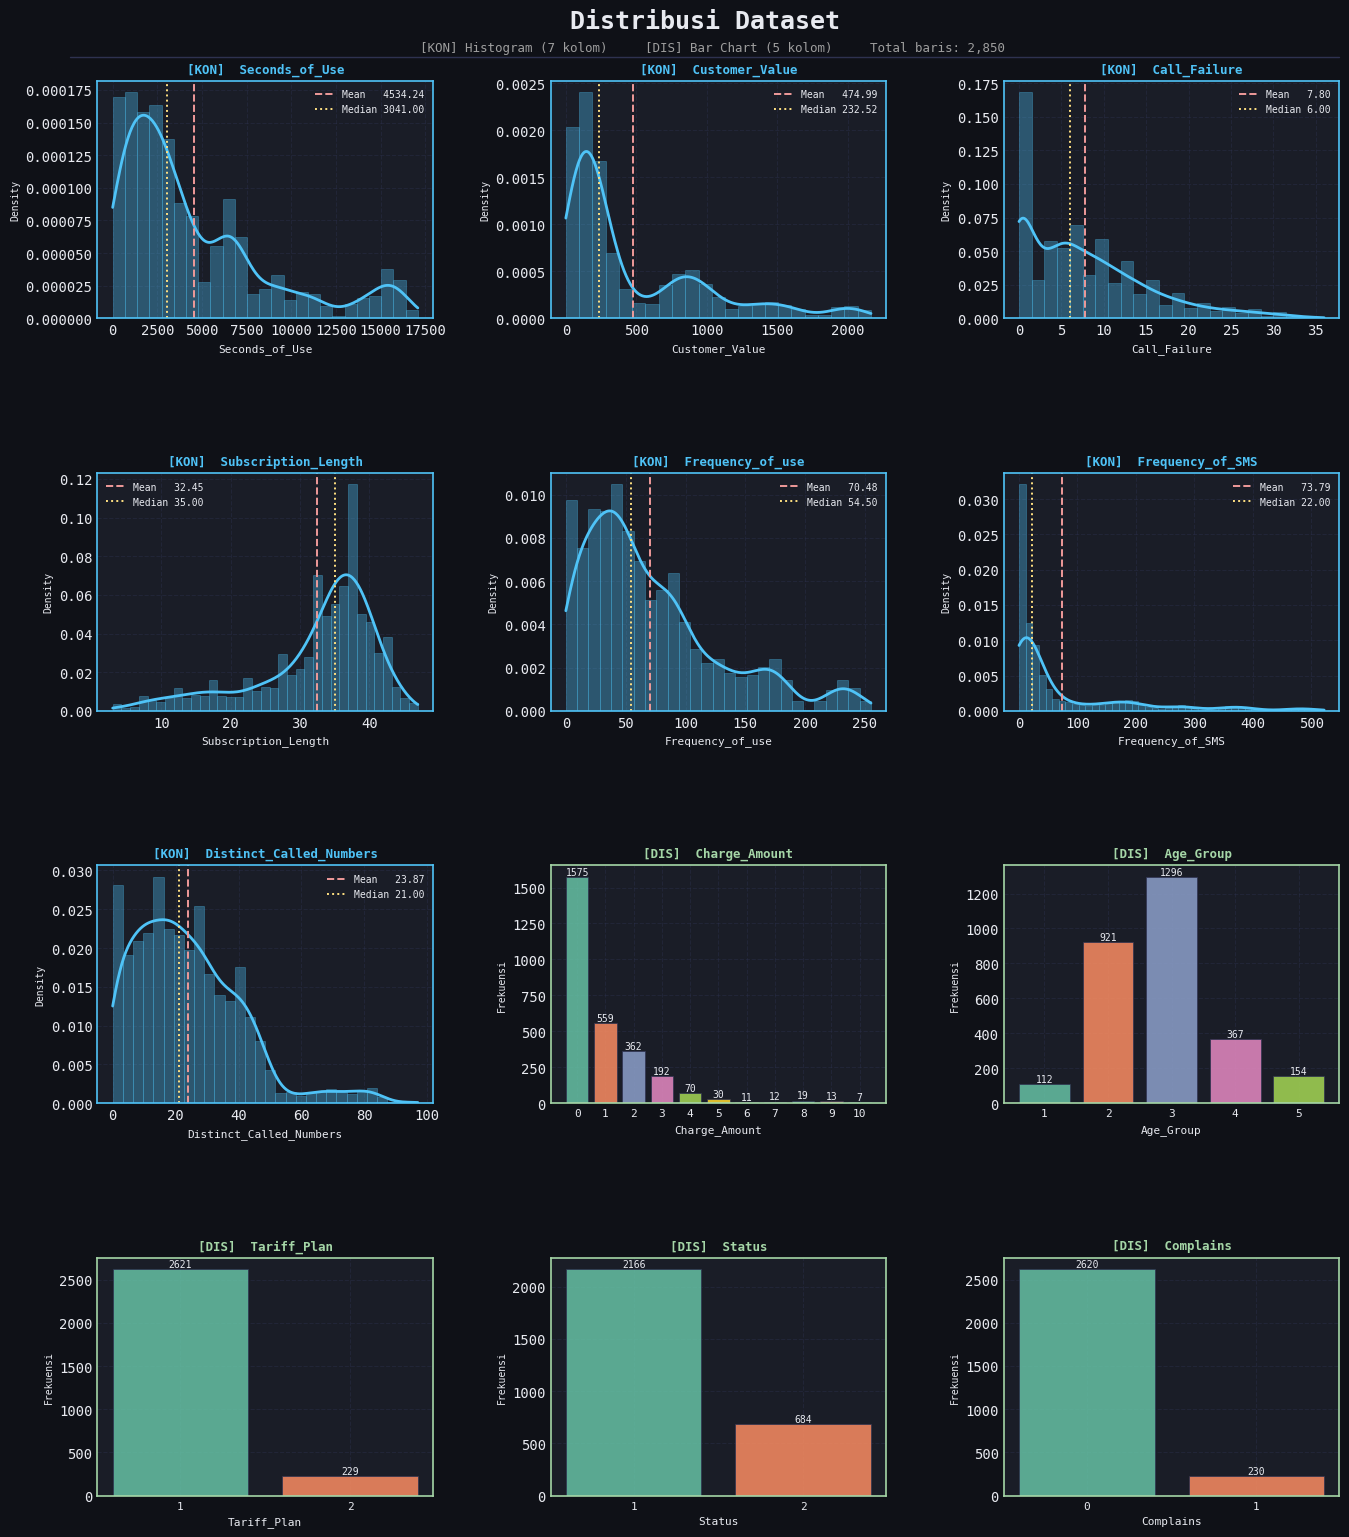

In [17]:
# ── Definisi Kolom ────────────────────────────────────────────────────────────
def deteksi_kolom(df):
    """
    Kolom dibagi menjadi dua kelompok berdasarkan cara visualisasi
    yang paling komunikatif, bukan semata-mata definisi statistik.

    Pakai histogram + KDE : fitur dengan nilai unik banyak sehingga
                            bentuk distribusinya lebih bermakna.
    Pakai bar chart       : fitur kategorikal atau ordinal dengan
                            nilai unik sedikit sehingga frekuensi
                            tiap nilai masih bisa dibaca jelas.
    """
    pakai_histogram = [
        'Seconds_of_Use',
        'Customer_Value',
        'Call_Failure',
        'Subscription_Length',
        'Frequency_of_use',
        'Frequency_of_SMS',
        'Distinct_Called_Numbers',
    ]
    pakai_bar = [
        'Charge_Amount',
        'Age_Group',
        'Age',
        'Tariff_Plan',
        'Status',
        'Complains',
    ]
    pakai_histogram = [c for c in pakai_histogram if c in df.columns]
    pakai_bar       = [c for c in pakai_bar       if c in df.columns]
    return pakai_histogram, pakai_bar


# ── Plot Histogram + KDE ──────────────────────────────────────────────────────
def plot_kontinu(ax, series: pd.Series, accent_kontinu: str):
    data = series.dropna()
    ax.hist(data, bins="auto", color=accent_kontinu, alpha=0.35,
            edgecolor=accent_kontinu, linewidth=0.6, density=True)
    try:
        kde = gaussian_kde(data)
        xs  = np.linspace(data.min(), data.max(), 300)
        ax.plot(xs, kde(xs), color=accent_kontinu, linewidth=2)
    except Exception:
        pass
    ax.axvline(data.mean(),   color="#ef9a9a", linewidth=1.4,
               linestyle="--", label=f"Mean   {data.mean():.2f}")
    ax.axvline(data.median(), color="#ffe082", linewidth=1.4,
               linestyle=":",  label=f"Median {data.median():.2f}")
    ax.legend(fontsize=7, framealpha=0.2)
    ax.set_xlabel(series.name, fontsize=8)
    ax.set_ylabel("Density", fontsize=7)
    ax.grid(True, axis="y")


# ── Plot Bar Chart ────────────────────────────────────────────────────────────
def plot_diskrit(ax, series: pd.Series, palette_diskrit: str, text_color: str):
    vc     = series.value_counts().sort_index()
    colors = sns.color_palette(palette_diskrit, len(vc))
    bars   = ax.bar(range(len(vc)), vc.values, color=colors,
                    edgecolor="#2e3250", linewidth=0.6, alpha=0.85)
    for bar, val in zip(bars, vc.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.5,
                str(val), ha="center", va="bottom",
                fontsize=7, color=text_color)
    ax.set_xticks(range(len(vc)))
    ax.set_xticklabels([str(v)[:12] for v in vc.index], fontsize=8)
    ax.set_xlabel(series.name, fontsize=8)
    ax.set_ylabel("Frekuensi", fontsize=7)
    ax.grid(True, axis="y")


# ── Fungsi Utama ──────────────────────────────────────────────────────────────
def visualisasi_distribusi(df: pd.DataFrame, cols_per_row: int = 3,
                            accent_kontinu: str = "#4fc3f7",
                            accent_diskrit: str = "#a5d6a7",
                            palette_diskrit: str = "Set2"):
    histogram_cols, bar_cols = deteksi_kolom(df)
    semua = ([("histogram", c) for c in histogram_cols] +
             [("bar",       c) for c in bar_cols])

    if not semua:
        print("Tidak ada kolom yang dapat divisualisasikan.")
        return

    n_plot = len(semua)
    n_rows = ceil(n_plot / cols_per_row)
    n_cols = min(n_plot, cols_per_row)
    fig_w  = n_cols * 4.5
    fig_h  = n_rows * 3.6 + 1.5

    fig = plt.figure(figsize=(fig_w, fig_h), facecolor=BG_COLOR)

    fig.text(0.5, 0.985, "Distribusi Dataset",
             ha="center", va="top", fontsize=18, fontweight="bold",
             color=TEXT_COLOR)
    fig.text(0.5, 0.965,
             f"  [KON] Histogram ({len(histogram_cols)} kolom)     "
             f"[DIS] Bar Chart ({len(bar_cols)} kolom)     "
             f"Total baris: {len(df):,}",
             ha="center", va="top", fontsize=9, color="#9e9e9e")
    fig.add_artist(
        plt.Line2D([0.03, 0.97], [0.955, 0.955],
                   transform=fig.transFigure,
                   color="#2e3250", linewidth=1)
    )

    gs = gridspec.GridSpec(
        n_rows, n_cols, figure=fig,
        top=0.94, bottom=0.05,
        left=0.05, right=0.97,
        hspace=0.65, wspace=0.35
    )

    for idx, (tipe, col) in enumerate(semua):
        r, c = divmod(idx, n_cols)
        ax   = fig.add_subplot(gs[r, c])

        border_clr = accent_kontinu if tipe == "histogram" else accent_diskrit
        for spine in ax.spines.values():
            spine.set_edgecolor(border_clr)
            spine.set_linewidth(1.2)

        ax.set_title(
            f"[{'KON' if tipe=='histogram' else 'DIS'}]  {col}",
            fontsize=9, fontweight="bold", pad=6,
            color=border_clr
        )

        if tipe == "histogram":
            plot_kontinu(ax, df[col], accent_kontinu)
        else:
            plot_diskrit(ax, df[col], palette_diskrit, TEXT_COLOR)

        n_miss = df[col].isna().sum()
        if n_miss:
            ax.annotate(f"! {n_miss} NaN", xy=(0.98, 0.96),
                        xycoords="axes fraction", ha="right", va="top",
                        fontsize=7, color="#ef9a9a")

    for idx in range(n_plot, n_rows * n_cols):
        r, c = divmod(idx, n_cols)
        fig.add_subplot(gs[r, c]).set_visible(False)

    plt.show()
    plt.close(fig)


# ── Jalankan ──────────────────────────────────────────────────────────────────
visualisasi_distribusi(df, cols_per_row=3)

### **Ringkasan Distribusi Dataset**

Kolom dibagi menjadi dua kelompok berdasarkan cara visualisasi yang paling komunikatif:

1. **Histogram + KDE** digunakan untuk fitur kontinu atau fitur dengan rentang nilai unik yang banyak, sehingga bentuk distribusinya (simetris, menceng, atau bimodal) lebih bermakna untuk dianalisis. Garis **merah putus-putus** menunjukkan rata-rata (*Mean*) dan garis **kuning titik-titik** menunjukkan nilai tengah (*Median*).
2. **Bar Chart** digunakan untuk fitur kategorikal atau ordinal dengan nilai unik sedikit, sehingga frekuensi tiap nilai dapat dibaca dengan jelas untuk melihat ketimpangan kelas (*class imbalance*).

---

### **1. Fitur Numerik Kontinu (Histogram & KDE)**

**`Seconds_of_Use`, `Frequency_of_use`, dan `Frequency_of_SMS`**
Ketiga metrik aktivitas penggunaan ini menunjukkan distribusi yang sangat **menceng ke kanan (*right-skewed*)**. Terdapat puncak yang sangat besar di nilai-nilai rendah (bahkan pada `Frequency_of_SMS` puncaknya nyaris berada di angka 0). Rata-rata (*Mean*) selalu tertarik jauh lebih besar daripada *Median*. Artinya, sebagian besar baris punya penggunaan rendah, dan sebagian kecil punya penggunaan jauh lebih tinggi.

**`Customer_Value`**
Distribusinya juga condong ke kanan (*right-skewed*) namun menunjukkan pola **bimodal (memiliki dua puncak)**. Puncak pertama berada di rentang nilai rendah (mendekati 0) dan puncak kedua berada di rentang nilai sekitar 500-1000. Bentuk ini belum membuktikan adanya dua segmen pelanggan, karena independensi antarbaris tidak terjamin.

**`Distinct_Called_Numbers`**
Distribusi fitur ini juga **menceng ke kanan (*right-skewed*)** dengan ekor yang memanjang mendekati angka 100, namun bentuknya sedikit lebih merata dan tidak seekstrem fitur penggunaan lainnya. Mayoritas pelanggan menghubungi sekitar 21 nomor berbeda (*Median* = 21).

**`Call_Failure`**
Bentuk distribusinya menceng ke kanan (*skewness* 1,07). Sebagian besar pelanggan memiliki tingkat kegagalan panggilan yang sangat minim (berkumpul di angka 0-10), dan hanya sedikit pelanggan yang mengalami kegagalan panggilan tinggi di atas 20 kali.

**`Subscription_Length`**
Ini adalah satu-satunya fitur numerik yang distribusinya **menceng ke kiri (*left-skewed*)**. Puncak populasinya berada di angka sekitar 30–40. Satuan kolom ini menurut dokumentasi UCI adalah bulan.

---

### **2. Fitur Kategorikal & Ordinal (Bar Chart)**

**`Complains`**
Sangat tidak seimbang (*highly imbalanced*). Hanya **230** dari 2.850 pelanggan (sekitar 8%) yang pernah mengajukan komplain. Ketimpangan ini perlu diwaspadai karena fitur dengan variansi rendah dapat berdampak pada stabilitas model prediksi.

**`Tariff_Plan`**
Didominasi secara ekstrem oleh Pay as you go (*Pay as you go*) dengan **2.621 pelanggan** (92%), dibandingkan Kontrak yang hanya diisi oleh **229 pelanggan**. Distribusi monolitik ini menunjukkan model mungkin akan kesulitan mempelajari pola perilaku pelanggan dari Kontrak.

**`Status`**
Proporsinya terbagi menjadi **2.166 pelanggan** (Aktif) dan **684 pelanggan** (Non-aktif). Terdapat ketimpangan, namun rasionya masih cukup sehat untuk dianalisis lebih lanjut terkait hubungannya dengan target *Churn*.

**`Age_Group` dan `Age`**
Didominasi oleh kelompok 3 (merepresentasikan usia ~30 tahun) dengan **1.296 pelanggan**, disusul kelompok 2 (\~25 tahun) dengan **921 pelanggan**. Karena `Age` dan `Age_Group` merepresentasikan informasi yang persis sama, besar kemungkinan salah satunya bersifat redundan.

**`Charge_Amount`**
Sangat tidak seimbang dan didominasi oleh nilai 0 dengan **1.575 pelanggan** (lebih dari 50% populasi). Kategori lainnya menyusut secara eksponensial.

---

### **Kesimpulan Utama (Key Takeaways)**

Dari eksplorasi distribusi ini, terdapat tiga poin tindakan (*action items*) utama untuk langkah pemrosesan selanjutnya:

1. **Opsi Transformasi Skala:** Hampir seluruh fitur penggunaan (*Usage Features*) memiliki distribusi yang menceng sangat kuat ke kanan (*skewness* tinggi). Transformasi seperti *Log Transform* bisa dievaluasi saat modeling jika memakai model linier, dan keputusannya belum diambil.
2. **Penanganan Fitur Berisiko (Low Variance):** Fitur seperti `Tariff_Plan`, `Complains`, dan `Charge_Amount` sangat didominasi oleh satu kelas mayoritas. Fitur-fitur ini perlu dievaluasi lebih jauh melalui analisis Bivariat untuk memastikan apakah mereka memiliki daya pembeda (*predictive power*) terhadap *Churn*, atau justru hanya menjadi *noise*.
3. **Penyaringan Redundansi:** Adanya pola yang mirip pada fitur (`Age` dengan `Age_Group`, atau `Seconds_of_Use` dengan `Frequency_of_use`) harus divalidasi pada uji Korelasi Multivariat untuk mendeteksi multikolinearitas sebelum masuk ke algoritma.

## Distribusi Target

In [18]:
churn_pct = df['Churn'].value_counts(normalize=True) * 100
print(f"Tidak Churn (0): {churn_pct[0]:.1f}%")
print(f"Churn (1):       {churn_pct[1]:.1f}%")

Tidak Churn (0): 84.4%
Churn (1):       15.6%


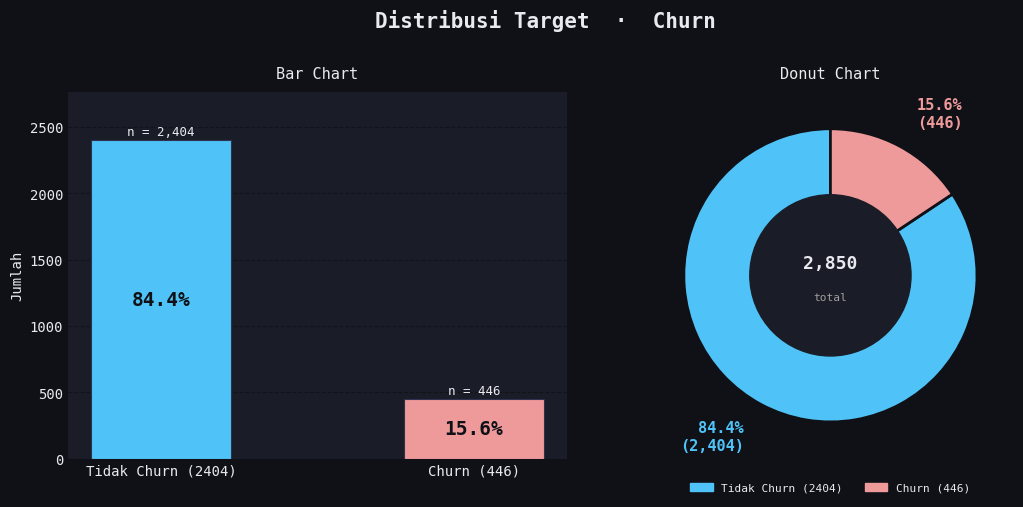

In [19]:
# ─────────────────────────────────────────────────────────────────────────────

COLOR_0 = "#4fc3f7"   # Tidak Churn
COLOR_1 = "#ef9a9a"   # Churn

def grafik_churn(df: pd.DataFrame, target_col: str = TARGET):
    counts  = df[target_col].value_counts().sort_index()
    labels  = [f"Tidak Churn ({v})" if k == 0 else f"Churn ({v})"
               for k, v in counts.items()]
    colors  = [COLOR_0 if k == 0 else COLOR_1 for k in counts.index]
    total   = counts.sum()
    pcts    = counts / total * 100

    fig, (ax_bar, ax_pie) = plt.subplots(
        1, 2, figsize=(11, 5), facecolor=BG_COLOR
    )
    fig.suptitle(f"Distribusi Target  ·  {target_col}",
                 fontsize=15, fontweight="bold", color=TEXT_COLOR, y=1.01)

    # ── Bar Chart
    bars = ax_bar.bar(labels, counts.values, color=colors,
                      edgecolor="#2e3250", linewidth=0.8, width=0.45)

    for bar, pct, cnt in zip(bars, pcts, counts.values):
        ax_bar.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() / 2,
            f"{pct:.1f}%",
            ha="center", va="center",
            fontsize=14, fontweight="bold", color=BG_COLOR
        )
        ax_bar.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + total * 0.005,
            f"n = {cnt:,}",
            ha="center", va="bottom",
            fontsize=9, color=TEXT_COLOR
        )

    ax_bar.set_ylabel("Jumlah", fontsize=10)
    ax_bar.set_title("Bar Chart", fontsize=11, pad=10)
    ax_bar.set_ylim(0, counts.max() * 1.15)
    ax_bar.grid(True, axis="y", linestyle="--", alpha=0.3, color="#000000")
    ax_bar.grid(False, axis="x")
    ax_bar.spines[["top", "right"]].set_visible(False)

    # ── Donut Chart
    wedge_props = {"linewidth": 2, "edgecolor": BG_COLOR}
    wedges, _ = ax_pie.pie(
        counts.values,
        colors=colors,
        startangle=90,
        wedgeprops=wedge_props,
        radius=1,
    )

    for wedge, pct, cnt, lbl in zip(wedges, pcts, counts.values, labels):
        angle  = (wedge.theta1 + wedge.theta2) / 2
        x      = 1.25 * np.cos(np.radians(angle))
        y      = 1.25 * np.sin(np.radians(angle))
        ha     = "left" if x > 0 else "right"
        ax_pie.text(x, y, f"{pct:.1f}%\n({cnt:,})",
                    ha=ha, va="center",
                    fontsize=11, fontweight="bold",
                    color=wedge.get_facecolor())

    hole = plt.Circle((0, 0), 0.55, color=PANEL_COLOR)
    ax_pie.add_patch(hole)
    ax_pie.text(0, 0.08, f"{total:,}", ha="center", va="center",
                fontsize=13, fontweight="bold", color=TEXT_COLOR)
    ax_pie.text(0, -0.15, "total", ha="center", va="center",
                fontsize=8, color="#9e9e9e")

    ax_pie.set_title("Donut Chart", fontsize=11, pad=10)

    legend_patches = [
        mpatches.Patch(color=c, label=l)
        for c, l in zip(colors, labels)
    ]
    ax_pie.legend(handles=legend_patches, loc="lower center",
                  bbox_to_anchor=(0.5, -0.12), ncol=2,
                  fontsize=8, framealpha=0.15)

    plt.tight_layout()
    plt.show()
    plt.close(fig)


grafik_churn(df, target_col=TARGET)

### Distribusi Target: 'Churn'

Dari total **2.850 pelanggan** (setelah 300 duplikat persis dihapus untuk mengurangi risiko baris identik terpisah ke *train set* dan *test set*), distribusi kelas target adalah sebagai berikut:

| Kelas | Jumlah | Persentase |
|---|---|---|
| Tidak Churn | 2.404 | 84,4% |
| Churn | 446 | 15,6% |

Dataset ini termasuk **imbalanced (tidak seimbang)** karena kelas *churn* hanya mewakili 15,6% dari total data. Artinya, untuk setiap 1 pelanggan yang *churn*, terdapat lebih dari 5 pelanggan yang tidak *churn* (rasio sekitar 1 : 5,4).

Kondisi ini umum ditemukan pada kasus *churn* di industri telekomunikasi dan wajib diperhatikan dalam pemodelan, karena algoritma standar cenderung akan bias (lebih condong memprediksi kelas mayoritas) jika tidak ditangani. Strategi penanganannya dibandingkan saat modeling dan belum diputuskan.

# B. Outlier dan Nilai Ekstrem

## **Analisis Outlier**

### Dasar Pengelompokan

Dalam analisis outlier, pembagian fitur tidak didasarkan pada cardinality (jumlah nilai unik) seperti pada visualisasi distribusi sebelumnya, melainkan pada **apakah nilai ekstrem pada fitur tersebut secara statistik bermakna sebagai outlier**.

Ada dua pertanyaan kunci yang menentukan apakah sebuah fitur perlu dianalisis outlier-nya:

**1. Apakah nilai fitur merepresentasikan besaran yang bisa dibandingkan secara magnitude?**

Fitur seperti `Frequency_of_use` menyimpan nilai berupa jumlah penggunaan. Selisih antara nilai 10 dan 500 memiliki makna yang nyata secara kuantitatif. Nilai 500 di sini bisa jadi jauh di luar pola umum dan layak disebut outlier.

Sebaliknya, fitur seperti `Status` menyimpan nilai 1 dan 2 yang merepresentasikan kategori, bukan besaran. Nilai 2 tidak berarti "dua kali lebih besar" dari nilai 1. Tidak ada konsep nilai ekstrem di sini karena semua nilai adalah label yang valid.

**2. Apakah metode statistik berbasis jarak (IQR, Z-score) masih relevan diterapkan?**

Metode IQR bekerja dengan mengukur seberapa jauh sebuah nilai dari kuartil tengah distribusi. Ini hanya bermakna jika nilai-nilai dalam fitur memiliki urutan dan jarak yang bisa dihitung. Fitur dengan nilai kategoris atau ordinal yang terbatas tidak memenuhi syarat ini.

___

### **Pembagian Fitur**

Berdasarkan dua pertanyaan di atas, fitur dibagi menjadi dua kelompok:

#### Kelompok 1: Perlu Analisis Outlier

Fitur-fitur berikut merepresentasikan besaran kuantitatif sehingga nilai ekstrem di ujung distribusinya bermakna secara statistik dan perlu diidentifikasi:

| Fitur | Alasan |
|---|---|
| `Seconds_of_Use` | Durasi penggunaan dalam satuan detik, nilai sangat tinggi bisa jadi anomali |
| `Customer_Value` | Nilai pelanggan dalam satuan numerik, distribusi sangat skewed dengan ekor panjang |
| `Call_Failure` | Jumlah kegagalan panggilan, nilai ekstrem tinggi bisa merepresentasikan gangguan teknis tidak normal |
| `Subscription_Length` | Lama berlangganan dalam bulan, nilai di luar rentang wajar perlu dicermati |
| `Frequency_of_use` | Jumlah penggunaan layanan, meski diskrit nilainya merepresentasikan besaran yang bisa dibandingkan |
| `Frequency_of_SMS` | Jumlah SMS yang dikirim, distribusi sangat skewed dengan potensi outlier di nilai tinggi |
| `Distinct_Called_Numbers` | Jumlah nomor unik yang dihubungi, meski diskrit tetap merepresentasikan besaran kuantitatif |

Perlu diperhatikan bahwa `Frequency_of_use`, `Frequency_of_SMS`, dan `Distinct_Called_Numbers` secara teknis adalah fitur diskrit. Namun ketiganya tetap dimasukkan ke kelompok ini karena nilainya merepresentasikan besaran yang bisa diukur jaraknya, sehingga IQR masih valid dan relevan diterapkan.

#### Kelompok 2: Tidak Perlu Analisis Outlier

Fitur-fitur berikut merepresentasikan kategori atau label, sehingga tidak ada konsep nilai ekstrem yang bermakna secara statistik:

| Fitur | Alasan |
|---|---|
| `Complains` | Hanya bernilai 0 atau 1, semua nilai adalah label valid |
| `Charge_Amount` | Kode tingkatan (0 sampai 10), bukan besaran kontinu. Dokumentasi UCI menyebut 0 sampai 9, tetapi nilai 10 (7 baris setelah deduplikasi) dipertahankan |
| `Age_Group` | Label kelompok usia (1 sampai 5), nilai 5 tidak berarti lebih ekstrem dari nilai 1 |
| `Age_Binning` | Nilai hasil pengelompokan (*binning*) usia yang bersifat diskrit (misal: 15, 25, 30), bukan besaran kontinu murni |
| `Tariff_Plan` | Hanya bernilai 1 atau 2, merepresentasikan jenis paket |
| `Status` | Hanya bernilai 1 atau 2, merepresentasikan status akun |

___

### **Metode yang Digunakan**

Analisis outlier menggunakan kombinasi tiga lapis pendekatan yang saling melengkapi.

**Lapisan 1: Deteksi dengan IQR**

Outlier diidentifikasi menggunakan metode **IQR (Interquartile Range)**:

```
Batas Bawah  =  Q1  -  1.5 * IQR
Batas Atas   =  Q3  +  1.5 * IQR
```

Data yang berada di luar batas tersebut dikategorikan sebagai outlier. Batas ini berlaku sama untuk seluruh data tanpa memisahkan kelas, sehingga memungkinkan kita untuk langsung membaca **pada rentang nilai berapa** pelanggan churn dan tidak churn berada.

**Lapisan 2: Validasi dengan Chi-Square dan Odds Ratio**

Setelah outlier terdeteksi, dua metrik digunakan untuk memvalidasi apakah temuan tersebut benar-benar bermakna:

**Chi-Square + p-value** menguji apakah hubungan antara status outlier dan churn terjadi secara nyata atau hanya kebetulan. Jika p-value di bawah 0,05 maka hubungannya signifikan secara statistik.

**Odds Ratio (OR)** mengukur seberapa besar kemungkinan pelanggan yang masuk kategori outlier untuk churn dibandingkan pelanggan non-outlier. OR di atas 1 berarti outlier lebih berisiko, OR di bawah 1 berarti outlier justru lebih aman.

```
OR = (outlier & churn  x  normal & tidak churn) / (outlier & tidak churn  x  normal & churn)
```

**Lapisan 3: Kekuatan Hubungan dengan Point-Biserial Correlation**

**Point-Biserial Correlation (PBR)** mengukur seberapa kuat hubungan antara nilai numerik fitur secara keseluruhan dengan status churn.

| Nilai PBR | Kekuatan Hubungan |
|---|---|
| 0,00 sampai 0,10 | Sangat Lemah |
| 0,10 sampai 0,30 | Lemah |
| 0,30 sampai 0,50 | Sedang |
| Di atas 0,50 | Kuat |

Ketiga lapisan ini bekerja bersama: IQR menemukan outlier, Chi-Square dan OR memvalidasi apakah outlier tersebut berhubungan dengan churn, dan PBR mengukur seberapa dalam hubungan nilai fitur itu sendiri terhadap churn secara keseluruhan.

In [20]:
cat = [
    'Complains',
    'Tariff_Plan',
    'Status',
    'Age_Group',
    'Age_Binning',
    'Charge_Amount'
]

for col in cat:
    if col in df.columns:
        df[col] = df[col].astype('category')

---
## Eksplorasi Outlier dengan Batas IQR yang Sama

### Apa yang dilakukan?

Kode ini mendeteksi outlier menggunakan **IQR (Interquartile Range)** yang dihitung dari **seluruh data** tanpa memisahkan kelas. Artinya batas outlier berlaku sama untuk semua pelanggan, baik yang churn maupun tidak.

Pendekatan ini dipilih sebagai langkah pertama karena memungkinkan kita untuk melihat **pada rentang nilai berapa** pelanggan churn dan tidak churn berada, menggunakan batas yang sama sebagai acuan. Ini membuat perbandingannya langsung dan konkret secara bisnis.





## **Pemeriksaan Outlier**

### Apa yang dilakukan kode ini?
Kode ini melakukan pemindaian otomatis pada seluruh fitur kuantitatif untuk mendeteksi *outlier* menggunakan metode **IQR Global** (dihitung dari keseluruhan populasi data tanpa pemisahan kelas target). Setelah *outlier* terdeteksi, program langsung melakukan serangkaian uji hipotesis statistik untuk mengukur hubungan *outlier* tersebut dengan status *Churn*.

### Mengapa ini diperlukan?
Mendeteksi *outlier* secara visual (menggunakan *Boxplot*) saja tidak cukup untuk mengambil keputusan perlakuan data. Kode ini dirancang untuk menjawab pertanyaan kritis: *"Apakah pelanggan yang perilakunya sangat ekstrem (outlier) memiliki kecenderungan churn yang berbeda secara signifikan dibandingkan pelanggan normal?"*

### Apa yang dihasilkan?
Untuk setiap fitur, program akan menghasilkan:
1. **Visualisasi Dasbor 3 Panel:** Terdiri dari *Strip Plot* (sebaran titik data individual), *KDE Plot* (kepadatan kurva), dan *Bar Chart* (perbandingan *Churn Rate* secara langsung).
2. **Validasi Statistik:** Mencetak metrik *p-value* (via *Chi-Square*), *Odds Ratio* (OR), dan *Point-Biserial Correlation* (PBR) beserta interpretasi kekuatannya.
3. **Label Deskriptif:** Memberi label berdasarkan p-value dan arah selisih *churn rate*, misalnya `Churn rate outlier lebih rendah` atau `Tidak ada bukti perbedaan`.
4. **Tabel Ringkasan Akhir:** Rekapitulasi seluruh metrik dari semua fitur untuk memudahkan penentuan strategi *Feature Engineering* selanjutnya.

In [21]:
# ─────────────────────────────────────────────────────────────────────────────

ACCENT_0    = "#4fc3f7"   # Tidak Churn
ACCENT_1    = "#ef9a9a"   # Churn
ACCENT_OUT  = "#ffd54f"   # Outlier

num_cols   = [c for c in df.columns
              if pd.api.types.is_numeric_dtype(df[c]) and c != TARGET]
label_map  = {v: lbl for v, lbl in
              zip(sorted(df[TARGET].unique()), ["Tidak Churn", "Churn"])}
baseline   = df[TARGET].mean() * 100

def get_outlier_mask(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR    = Q3 - Q1
    return (series < Q1 - 1.5*IQR) | (series > Q3 + 1.5*IQR), Q1, Q3, IQR

def hitung_odds_ratio(tabel):
    """Hitung Odds Ratio dari tabel kontingensi 2x2."""
    a = tabel.iloc[1, 1]   # outlier & churn
    b = tabel.iloc[1, 0]   # outlier & tidak churn
    c = tabel.iloc[0, 1]   # normal  & churn
    d = tabel.iloc[0, 0]   # normal  & tidak churn
    if b == 0 or c == 0:
        return np.nan
    return (a * d) / (b * c)

def interpretasi_pbr(r):
    """Interpretasi kekuatan Point-Biserial Correlation."""
    r = abs(r)
    if r >= 0.5:
        return "Kuat"
    elif r >= 0.3:
        return "Sedang"
    elif r >= 0.1:
        return "Lemah"
    return "Sangat Lemah"

# ─────────────────────────────────────────────────────────────────────────────


 OUTLIER ANALYSIS: Call_Failure
  Batas bawah        : -15.50  |  Batas atas : 28.50
  Jumlah outlier     : 44 (1.5% dari data)
  Churn rate outlier : 20.5%
  Churn rate normal  : 15.6%
  Selisih            : +4.9%
  p-value            : 0.499611  (tidak signifikan)
  Odds Ratio         : 1.394
  Point-Biserial r   : 0.0033  (Sangat Lemah)
  Insight            : Tidak ada bukti perbedaan
------------------------------------------------------------


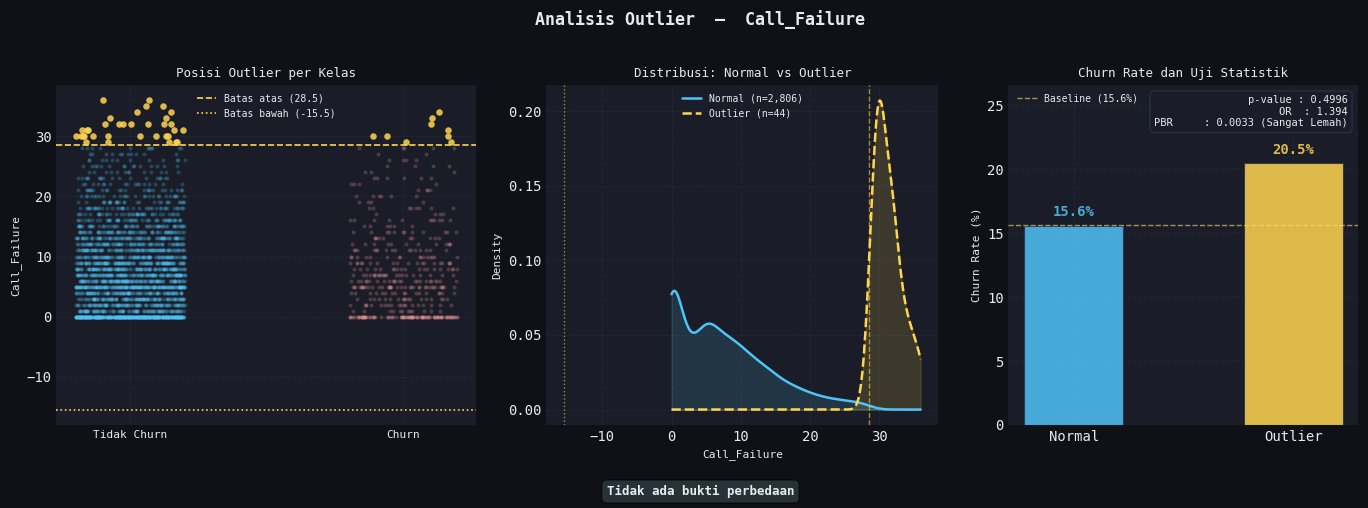


 OUTLIER ANALYSIS: Subscription_Length
  Batas bawah        : 15.50  |  Batas atas : 51.50
  Jumlah outlier     : 208 (7.3% dari data)
  Churn rate outlier : 28.4%
  Churn rate normal  : 14.6%
  Selisih            : +13.7%
  p-value            : < 0.001  (signifikan)
  Odds Ratio         : 2.307
  Point-Biserial r   : -0.0380  (Sangat Lemah)
  Insight            : Churn rate outlier lebih tinggi
------------------------------------------------------------


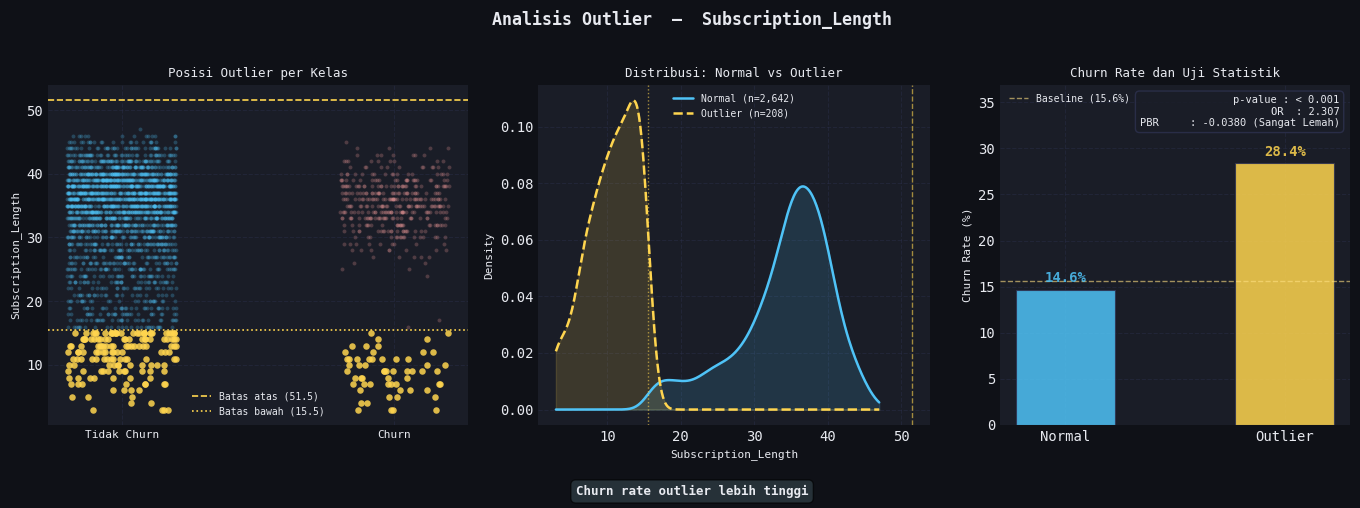


 OUTLIER ANALYSIS: Seconds_of_Use
  Batas bawah        : -6103.12  |  Batas atas : 14061.88
  Jumlah outlier     : 189 (6.6% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.8%
  Selisih            : -16.8%
  p-value            : < 0.001  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2960  (Lemah)
  Insight            : Churn rate outlier lebih rendah
------------------------------------------------------------


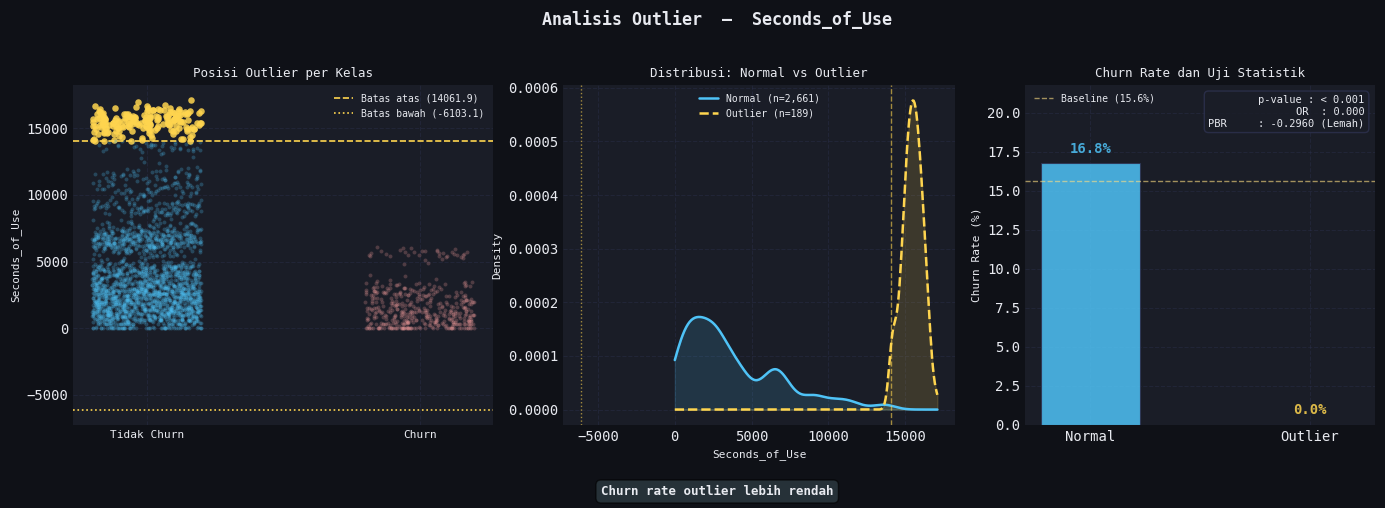


 OUTLIER ANALYSIS: Frequency_of_use
  Batas bawah        : -74.00  |  Batas atas : 198.00
  Jumlah outlier     : 118 (4.1% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.3%
  Selisih            : -16.3%
  p-value            : < 0.001  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2986  (Lemah)
  Insight            : Churn rate outlier lebih rendah
------------------------------------------------------------


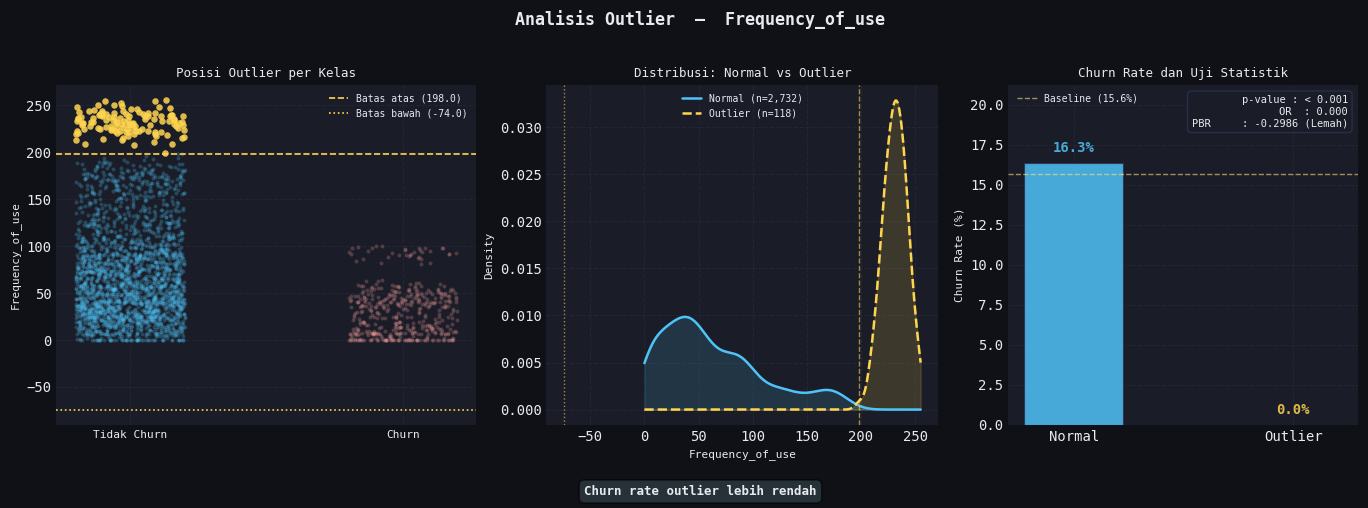


 OUTLIER ANALYSIS: Frequency_of_SMS
  Batas bawah        : -114.50  |  Batas atas : 209.50
  Jumlah outlier     : 333 (11.7% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 17.7%
  Selisih            : -17.7%
  p-value            : < 0.001  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2189  (Lemah)
  Insight            : Churn rate outlier lebih rendah
------------------------------------------------------------


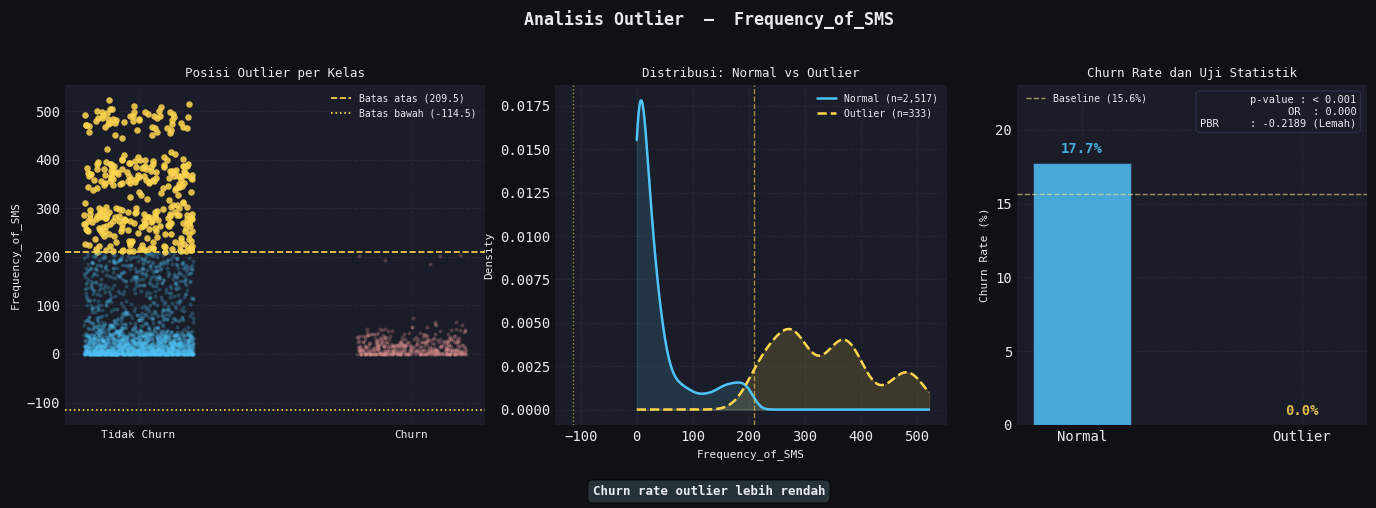


 OUTLIER ANALYSIS: Distinct_Called_Numbers
  Batas bawah        : -23.50  |  Batas atas : 68.50
  Jumlah outlier     : 82 (2.9% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.1%
  Selisih            : -16.1%
  p-value            : < 0.001  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2703  (Lemah)
  Insight            : Churn rate outlier lebih rendah
------------------------------------------------------------


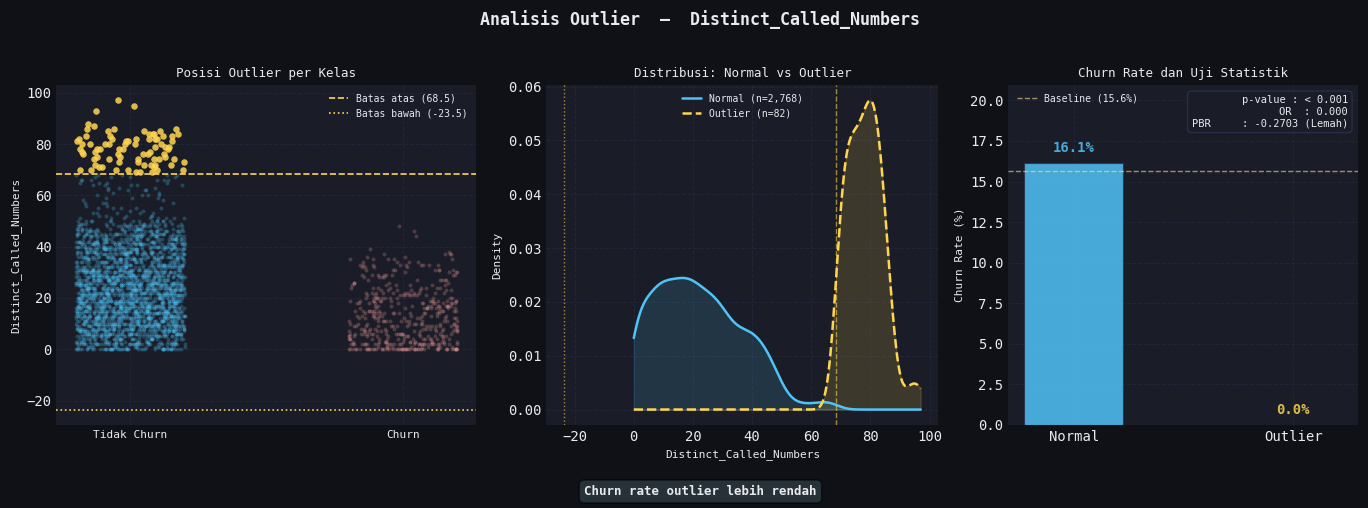


 OUTLIER ANALYSIS: Customer_Value
  Batas bawah        : -891.30  |  Batas atas : 1798.91
  Jumlah outlier     : 104 (3.6% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.2%
  Selisih            : -16.2%
  p-value            : < 0.001  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2871  (Lemah)
  Insight            : Churn rate outlier lebih rendah
------------------------------------------------------------


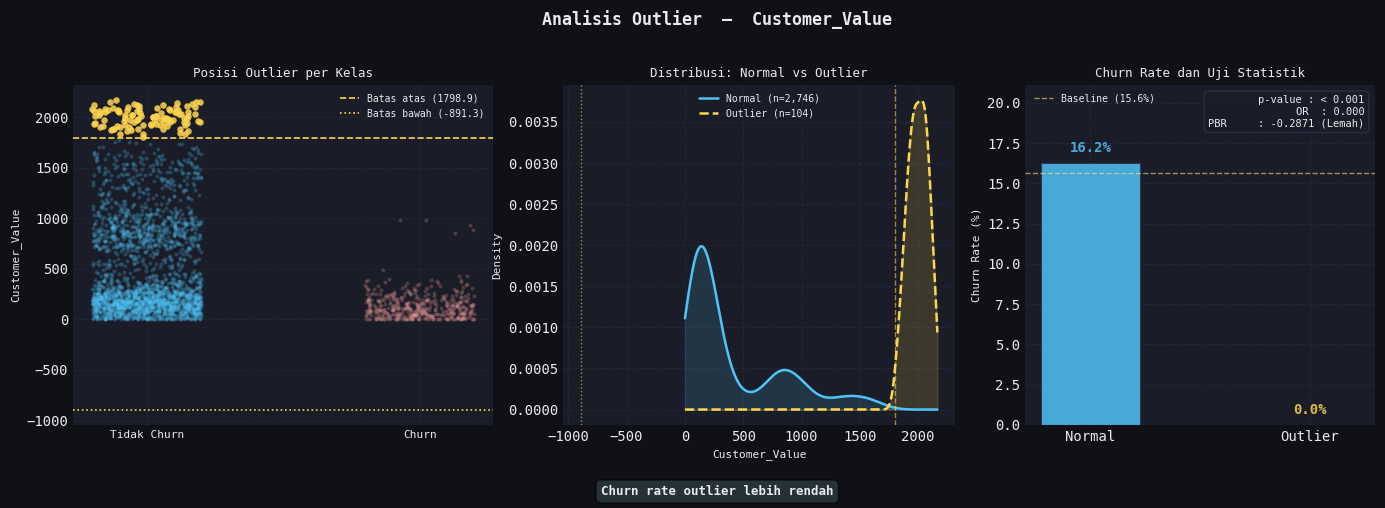

In [22]:
summary_rows = []

for name in num_cols:
    mask, Q1, Q3, IQR = get_outlier_mask(df[name])
    lower, upper      = Q1 - 1.5*IQR, Q3 + 1.5*IQR

    n_out   = mask.sum()
    n_total = len(df)

    if n_out == 0:
        print(f"[{name}] Tidak ada outlier.\n")
        continue

    df_out    = df[mask]
    df_nonout = df[~mask]
    cr_out    = df_out[TARGET].mean() * 100
    cr_nonout = df_nonout[TARGET].mean() * 100
    delta     = cr_out - cr_nonout

    tabel            = pd.crosstab(mask, df[TARGET])
    chi2, pval, _, _ = chi2_contingency(tabel)
    or_val = hitung_odds_ratio(tabel)

    valid_idx    = df[name].dropna().index
    pbr_corr, pbr_pval = pointbiserialr(
        df.loc[valid_idx, name],
        df.loc[valid_idx, TARGET]
    )
    pbr_strength = interpretasi_pbr(pbr_corr)

    if pval >= 0.05:
        insight = 'Tidak ada bukti perbedaan'
    elif delta > 0:
        insight = 'Churn rate outlier lebih tinggi'
    else:
        insight = 'Churn rate outlier lebih rendah'

    summary_rows.append({
        'Fitur'                  : name,
        'N Outlier'              : n_out,
        '% dari Data'            : round(n_out / n_total * 100, 2),
        'Batas Bawah'            : round(lower, 2),
        'Batas Atas'             : round(upper, 2),
        'Churn Rate Outlier (%)' : round(cr_out, 2),
        'Churn Rate Normal (%)'  : round(cr_nonout, 2),
        'Selisih (%)'            : round(delta, 2),
        'p-value'                : round(pval, 6),
        'Odds Ratio'             : round(or_val, 3) if not np.isnan(or_val) else 'N/A',
        'PBR'                    : round(pbr_corr, 4),
        'Kekuatan PBR'           : pbr_strength,
        'Insight'                : insight,
    })

    print(f"\n{'='*60}")
    print(f" OUTLIER ANALYSIS: {name}")
    print(f"{'='*60}")
    print(f"  Batas bawah        : {lower:.2f}  |  Batas atas : {upper:.2f}")
    print(f"  Jumlah outlier     : {n_out} ({n_out/n_total*100:.1f}% dari data)")
    print(f"  Churn rate outlier : {cr_out:.1f}%")
    print(f"  Churn rate normal  : {cr_nonout:.1f}%")
    print(f"  Selisih            : {delta:+.1f}%")
    print(f"  p-value            : {'< 0.001' if pval < 0.001 else f'{pval:.6f}'}  {'(signifikan)' if pval < 0.05 else '(tidak signifikan)'}")
    print(f"  Odds Ratio         : {or_val:.3f}" if not np.isnan(or_val) else "  Odds Ratio  : N/A")
    print(f"  Point-Biserial r   : {pbr_corr:.4f}  ({pbr_strength})")
    print(f"  Insight            : {insight}")
    print(f"{'-'*60}")

    fig = plt.figure(figsize=(14, 5), facecolor=BG_COLOR)
    fig.suptitle(f"Analisis Outlier  —  {name}",
                 fontsize=12, fontweight="bold", color=TEXT_COLOR)

    ax1 = fig.add_axes([0.04, 0.15, 0.30, 0.68])
    ax2 = fig.add_axes([0.39, 0.15, 0.28, 0.68])
    ax3 = fig.add_axes([0.72, 0.15, 0.25, 0.68])

    for ax in [ax1, ax2, ax3]:
        ax.set_facecolor(PANEL_COLOR)
        for sp in ax.spines.values():
            sp.set_edgecolor(GRID_COLOR)

    jitter = np.random.uniform(-0.2, 0.2, len(df))
    colors = np.where(mask, ACCENT_OUT,
             np.where(df[TARGET] == 1, ACCENT_1, ACCENT_0))
    sizes  = np.where(mask, 22, 8)
    alphas = np.where(mask, 0.85, 0.25)

    for i, (churn, x_j, col, sz, al) in enumerate(
            zip(df[TARGET], jitter, colors, sizes, alphas)):
        ax1.scatter(churn + x_j, df[name].iloc[i],
                    c=col, s=sz, alpha=float(al), linewidths=0)

    ax1.axhline(upper, color=ACCENT_OUT, linewidth=1.2, linestyle='--',
                label=f'Batas atas ({upper:.1f})')
    ax1.axhline(lower, color=ACCENT_OUT, linewidth=1.2, linestyle=':',
                label=f'Batas bawah ({lower:.1f})')
    ax1.set_xticks(list(label_map.keys()))
    ax1.set_xticklabels(list(label_map.values()), fontsize=8)
    ax1.set_ylabel(name, fontsize=8)
    ax1.set_title("Posisi Outlier per Kelas", fontsize=9, pad=6)
    ax1.legend(fontsize=7, framealpha=0.2)
    ax1.grid(True, axis='y')

    for subset, lbl, color, ls in [
        (df_nonout[name], f"Normal (n={len(df_nonout):,})", ACCENT_0, '-'),
        (df_out[name],    f"Outlier (n={n_out:,})",         ACCENT_OUT, '--'),
    ]:
        subset = subset.dropna()
        if len(subset) > 1:
            try:
                kde = gaussian_kde(subset)
                xs  = np.linspace(df[name].min(), df[name].max(), 300)
                ax2.fill_between(xs, kde(xs), alpha=0.15, color=color)
                ax2.plot(xs, kde(xs), color=color, linewidth=1.8,
                         linestyle=ls, label=lbl)
            except Exception:
                pass

    ax2.axvline(upper, color=ACCENT_OUT, linewidth=1, linestyle='--', alpha=0.6)
    ax2.axvline(lower, color=ACCENT_OUT, linewidth=1, linestyle=':', alpha=0.6)
    ax2.set_xlabel(name, fontsize=8)
    ax2.set_ylabel("Density", fontsize=8)
    ax2.set_title("Distribusi: Normal vs Outlier", fontsize=9, pad=6)
    ax2.legend(fontsize=7, framealpha=0.2)
    ax2.grid(True, axis='y')

    bar_vals   = [cr_nonout, cr_out]
    bar_colors = [ACCENT_0, ACCENT_OUT]
    bars = ax3.bar(["Normal", "Outlier"], bar_vals, color=bar_colors,
                   edgecolor=GRID_COLOR, linewidth=0.8, width=0.45, alpha=0.85)

    for bar, val in zip(bars, bar_vals):
        ax3.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f"{val:.1f}%", ha='center', va='bottom',
                 fontsize=10, fontweight='bold', color=bar.get_facecolor())

    or_text  = f"OR  : {or_val:.3f}" if not np.isnan(or_val) else "OR  : N/A"
    ax3.text(0.97, 0.97,
             f"p-value : {'< 0.001' if pval < 0.001 else f'{pval:.4f}'}\n{or_text}\nPBR     : {pbr_corr:.4f} ({pbr_strength})",
             transform=ax3.transAxes, ha='right', va='top',
             fontsize=7.5, color=TEXT_COLOR,
             bbox=dict(boxstyle='round,pad=0.4', facecolor=PANEL_COLOR,
                       edgecolor=GRID_COLOR, alpha=0.8))

    ax3.axhline(baseline, color="#ffe082", linewidth=1,
                linestyle='--', alpha=0.6, label=f'Baseline ({baseline:.1f}%)')
    ax3.set_ylabel("Churn Rate (%)", fontsize=8)
    ax3.set_title("Churn Rate dan Uji Statistik", fontsize=9, pad=6)
    ax3.set_ylim(0, max(max(bar_vals) * 1.3, 5))
    ax3.legend(fontsize=7, framealpha=0.2)
    ax3.grid(True, axis='y')

    badge_color = "#37474f"   # warna netral, supaya label tidak dibaca sebagai vonis
    fig.text(0.5, 0.01, insight,
             ha='center', fontsize=9, fontweight='bold',
             color=TEXT_COLOR,
             bbox=dict(boxstyle='round,pad=0.4', facecolor=badge_color, alpha=0.6))

    plt.show()
    plt.close(fig)

In [23]:
# ── Tabel Ringkasan ───────────────────────────────────────────────────────────
if summary_rows:
    print("\n" + "="*60)
    print(" RINGKASAN OUTLIER SELURUH FITUR")
    print("="*60)
    summary_df = pd.DataFrame(summary_rows).set_index('Fitur')
    print(summary_df.assign(**{'p-value': summary_df['p-value'].map(format_p)}).to_string())


 RINGKASAN OUTLIER SELURUH FITUR
                         N Outlier  % dari Data  Batas Bawah  Batas Atas  Churn Rate Outlier (%)  Churn Rate Normal (%)  Selisih (%)  p-value  Odds Ratio     PBR  Kekuatan PBR                          Insight
Fitur                                                                                                                                                                                                           
Call_Failure                    44         1.54       -15.50       28.50                   20.45                  15.57         4.88   0.4996       1.394  0.0033  Sangat Lemah        Tidak ada bukti perbedaan
Subscription_Length            208         7.30        15.50       51.50                   28.37                  14.65        13.72  < 0.001       2.307 -0.0380  Sangat Lemah  Churn rate outlier lebih tinggi
Seconds_of_Use                 189         6.63     -6103.12    14061.88                    0.00                  16.76       -16.

## Hasil Pemeriksaan Outlier

| Fitur | Batas Bawah | Batas Atas | Churn Rate Outlier | Churn Rate Normal | Selisih | p-value | Odds Ratio | PBR |
|---|---|---|---|---|---|---|---|---|
| `Call_Failure` | -15,50 | 28,50 | 20,5% | 15,6% | +4,9% | 0,4996 | 1,394 | 0,0033 |
| `Subscription_Length` | 15,50 | 51,50 | 28,4% | 14,6% | +13,7% | < 0,001 | 2,307 | -0,0380 |
| `Seconds_of_Use` | -6.103,12 | 14.061,88 | 0,0% | 16,8% | -16,8% | < 0,001 | 0,000 | -0,2960 |
| `Frequency_of_use` | -74,00 | 198,00 | 0,0% | 16,3% | -16,3% | < 0,001 | 0,000 | -0,2986 |
| `Frequency_of_SMS` | -114,50 | 209,50 | 0,0% | 17,7% | -17,7% | < 0,001 | 0,000 | -0,2189 |
| `Distinct_Called_Numbers` | -23,50 | 68,50 | 0,0% | 16,1% | -16,1% | < 0,001 | 0,000 | -0,2703 |
| `Customer_Value` | -891,30 | 1.798,91 | 0,0% | 16,2% | -16,2% | < 0,001 | 0,000 | -0,2871 |

> \* OR = 0,000 pada fitur usage merupakan estimasi batas akibat nol kejadian churn pada grup outlier; interpretasinya tetap valid secara arah (outlier lebih aman), namun magnitude persisnya tidak presisi tanpa koreksi kontinuitas.

> \* Batas Bawah bernilai negatif (`Call_Failure`, `Seconds_of_Use`, `Frequency_of_use`, `Frequency_of_SMS`, `Distinct_Called_Numbers`, `Customer_Value`) tidak bermakna praktis karena keenam fitur ini secara alami tidak bisa bernilai negatif sehingga secara efektif tidak ada outlier bawah pada fitur-fitur tersebut. Satu-satunya batas bawah yang menghasilkan outlier nyata adalah `Subscription_Length` (15,50 bulan).

___

### Yang Terbaca dari Hasil

**Pada nilai sangat tinggi, tidak ada baris churn.** Outlier `Seconds_of_Use`, `Frequency_of_use`, `Frequency_of_SMS`, `Distinct_Called_Numbers`, dan `Customer_Value` semuanya punya *churn rate* 0%. Ini fakta deskriptif pada data ini. Batas IQR-nya tidak boleh langsung dipakai sebagai aturan bisnis.

**Nilai `Subscription_Length` di bawah 15,5 punya *churn rate* lebih tinggi.** Angkanya 28,4%, berbanding 14,6% pada baris lainnya. Ini hubungan asosiatif dari satu periode data, jadi tidak dipakai sebagai klaim tentang pelanggan baru, walaupun menurut dokumentasi UCI satuannya bulan.

___

### Catatan dari Metrik Validasi

**`Call_Failure`:** selisih *churn rate* +4,9% dengan p-value 0,4996, jadi tidak ada bukti cukup untuk menyimpulkan adanya perbedaan. Ini tidak berarti perbedaannya pasti tidak ada.

**`Subscription_Length`:** OR 2,307 dengan p-value di bawah 0,001, tetapi PBR-nya -0,038 (Sangat Lemah). Hubungan ini tidak dipakai sebagai klaim tentang pelanggan baru.

**Fitur penggunaan** (`Seconds_of_Use`, `Frequency_of_use`, `Frequency_of_SMS`, `Distinct_Called_Numbers`, `Customer_Value`) punya PBR negatif di kisaran -0,22 sampai -0,30 (Lemah). Tanda negatif berarti nilai yang lebih tinggi berasosiasi dengan *churn* yang lebih rendah. Hubungan ini asosiatif, bukan kausal.

___

### Keterbatasan

*   Uji ini mengasumsikan tiap baris independen, mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan.
*   OR = 0 berarti tidak ada baris churn pada grup outlier, jadi besarnya tidak bisa ditafsirkan secara presisi.
*   Batas IQR dihitung dari seluruh data, jadi hasil ini hanya untuk eksplorasi, bukan aturan untuk model.


# C. Penanganan Outlier


## **Interpretasi Hasil Outlier per Fitur**

Setiap fitur dibaca dengan tiga metrik: **OR** (perbandingan peluang churn grup outlier dengan baris lain), **p-value** (uji chi-square), dan **PBR** (hubungan linier seluruh rentang nilai dengan churn). P-value mengasumsikan tiap baris independen, mengikuti dokumentasi UCI.

| Fitur | OR | p-value | PBR | Pembacaan |
|---|---|---|---|---|
| `Call_Failure` | 1,394 | 0,4996 | 0,0033 | Tidak ada bukti cukup untuk menyimpulkan adanya perbedaan |
| `Subscription_Length` | 2,307 | < 0,001 | -0,0380 | *Churn rate* grup outlier lebih tinggi, tetapi tidak dipakai sebagai klaim tentang pelanggan baru |
| `Seconds_of_Use` | 0,000 | < 0,001 | -0,2960 | Tidak ada baris churn pada grup outlier |
| `Frequency_of_use` | 0,000 | < 0,001 | -0,2986 | Tidak ada baris churn pada grup outlier |
| `Frequency_of_SMS` | 0,000 | < 0,001 | -0,2189 | Tidak ada baris churn pada grup outlier |
| `Distinct_Called_Numbers` | 0,000 | < 0,001 | -0,2703 | Tidak ada baris churn pada grup outlier |
| `Customer_Value` | 0,000 | < 0,001 | -0,2871 | Tidak ada baris churn pada grup outlier |

Semua hubungan ini asosiatif, bukan kausal. Churn 0% tidak membuktikan bahwa pelanggan tersebut loyal. Untuk `Distinct_Called_Numbers`, dokumentasi UCI menulis *total number of distinct phone calls*, jadi apa yang dihitung belum sepenuhnya jelas.

## Deteksi Overlap Antar Data Outlier

In [24]:
# 1. Tentukan kondisi outlier dari perhitungan IQR
outlier_sec  = get_outlier_mask(df['Seconds_of_Use'])[0]
outlier_freq = get_outlier_mask(df['Frequency_of_use'])[0]
outlier_sms  = get_outlier_mask(df['Frequency_of_SMS'])[0]
outlier_dcn  = get_outlier_mask(df['Distinct_Called_Numbers'])[0]
outlier_cv   = get_outlier_mask(df['Customer_Value'])[0]

# 2. Fitur yang dibandingkan dengan Seconds_of_Use
kandidat_fitur_overlap = {
    'Frequency_of_use': outlier_freq,
    'Frequency_of_SMS': outlier_sms,
    'Distinct_Called_Numbers': outlier_dcn,
    'Customer_Value': outlier_cv
}

print("============================================================")
print("  BUKTI IRISAN (OVERLAP) OUTLIER KLASTER PEMAKAIAN")
print("  Representasi Utama: Seconds_of_Use")
print("============================================================\n")

# 3. Looping untuk menghitung overlap masing-masing fitur
for nama_fitur, kondisi_outlier in kandidat_fitur_overlap.items():
    total_outlier_fitur_ini = df[kondisi_outlier].shape[0]

    # Hitung berapa orang yang menjadi outlier di fitur ini DAN JUGA di Seconds_of_Use
    irisan = df[outlier_sec & kondisi_outlier].shape[0]

    # Hitung persentase
    persentase_overlap = (irisan / total_outlier_fitur_ini) * 100 if total_outlier_fitur_ini > 0 else 0

    print(f"Fitur: {nama_fitur}")
    print(f" - Total Outlier        : {total_outlier_fitur_ini} orang")
    print(f" - Yang JUGA outlier di Seconds_of_Use : {irisan} orang")
    print(f" - Tingkat Overlap      : {persentase_overlap:.1f}%\n")

  BUKTI IRISAN (OVERLAP) OUTLIER KLASTER PEMAKAIAN
  Representasi Utama: Seconds_of_Use

Fitur: Frequency_of_use
 - Total Outlier        : 118 orang
 - Yang JUGA outlier di Seconds_of_Use : 118 orang
 - Tingkat Overlap      : 100.0%

Fitur: Frequency_of_SMS
 - Total Outlier        : 333 orang
 - Yang JUGA outlier di Seconds_of_Use : 0 orang
 - Tingkat Overlap      : 0.0%

Fitur: Distinct_Called_Numbers
 - Total Outlier        : 82 orang
 - Yang JUGA outlier di Seconds_of_Use : 56 orang
 - Tingkat Overlap      : 68.3%

Fitur: Customer_Value
 - Total Outlier        : 104 orang
 - Yang JUGA outlier di Seconds_of_Use : 0 orang
 - Tingkat Overlap      : 0.0%



In [25]:
# 1. Tentukan kondisi outlier dari perhitungan IQR
outlier_sms = get_outlier_mask(df['Frequency_of_SMS'])[0]
outlier_cv  = get_outlier_mask(df['Customer_Value'])[0]

# 2. Hitung total outlier masing-masing
total_sms = df[outlier_sms].shape[0]
total_cv  = df[outlier_cv].shape[0]

# 3. Hitung irisan (orang yang merupakan outlier di KEDUANYA)
irisan_sms_cv = df[outlier_sms & outlier_cv].shape[0]

# 4. Hitung persentase overlap terhadap masing-masing populasi
persentase_dari_sms = (irisan_sms_cv / total_sms) * 100 if total_sms > 0 else 0
persentase_dari_cv  = (irisan_sms_cv / total_cv) * 100 if total_cv > 0 else 0

print("============================================================")
print("  BUKTI IRISAN: Frequency_of_SMS vs Customer_Value")
print("============================================================\n")

print(f"Total Outlier Frequency_of_SMS : {total_sms} orang")
print(f"Total Outlier Customer_Value   : {total_cv} orang\n")

print(f"Jumlah orang yang beririsan (Outlier di keduanya): {irisan_sms_cv} orang\n")

print(f"Artinya:")
print(f" - {persentase_dari_cv:.1f}% outlier Customer_Value adalah outlier SMS.")
print(f" - {persentase_dari_sms:.1f}% outlier SMS adalah outlier Customer_Value.")
print("\n============================================================")

  BUKTI IRISAN: Frequency_of_SMS vs Customer_Value

Total Outlier Frequency_of_SMS : 333 orang
Total Outlier Customer_Value   : 104 orang

Jumlah orang yang beririsan (Outlier di keduanya): 104 orang

Artinya:
 - 100.0% outlier Customer_Value adalah outlier SMS.
 - 31.2% outlier SMS adalah outlier Customer_Value.



### Kesimpulan Penanganan Outlier

**Keputusan: semua outlier dipertahankan.** Tidak ada baris yang dihapus dan tidak ada nilai yang dipotong, karena tidak ada bukti bahwa nilainya salah. Menghapusnya berarti membuang baris yang sah.

**Rencana *flag* dibatalkan untuk sekarang.** Batasnya sebelumnya dipilih setelah melihat churn pada seluruh data, sehingga berisiko membuat skor terlalu optimistis. *Flag* bisa dibahas lagi saat *feature engineering*, dengan batas yang dihitung di dalam fold.

**Irisan outlier bersifat deskriptif:** sel di atas menunjukkan bahwa semua outlier `Frequency_of_use` juga outlier `Seconds_of_Use`, dan semua outlier `Customer_Value` juga outlier `Frequency_of_SMS`. Keputusan fitur belum diambil dari sini.

Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan.

# **Bagian 3: Hubungan Fitur dengan Churn**

# A. Analisis Bivariat: Hubungan Setiap Fitur dengan Churn


 FEATURE: Call_Failure 
                 Count   Mean  Median    Std  Min  Max
Churn                                                 
0 — Tidak Churn   2404  7.792     6.0  7.223    0   36
1 — Churn          446  7.859     6.0  7.869    0   34
--------------------------------------------------


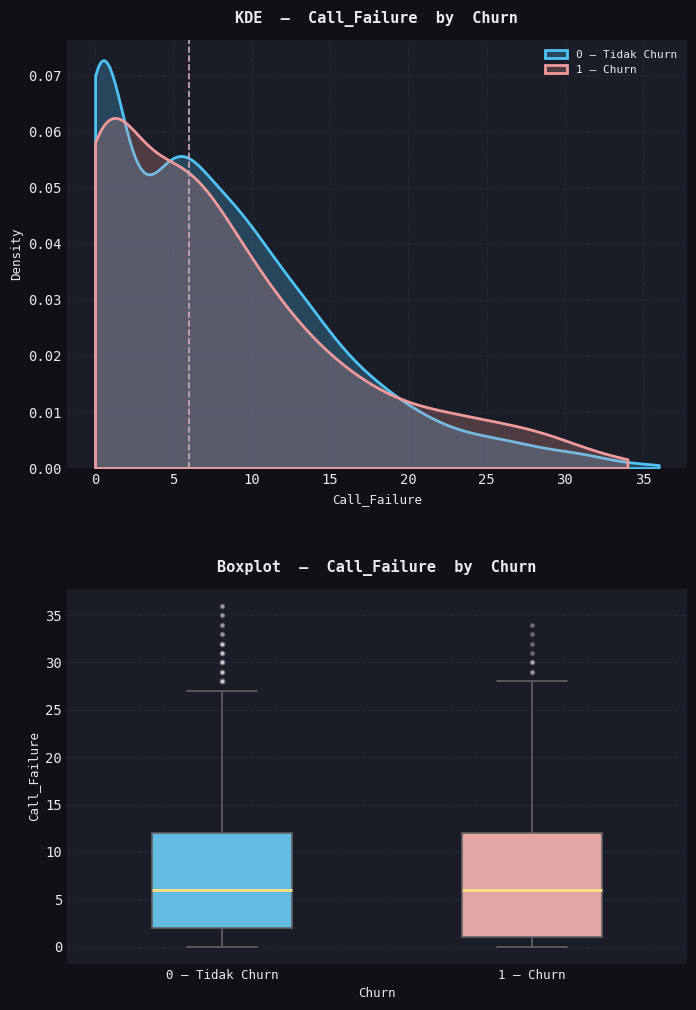


 FEATURE: Complains 
           count  Churn_Count  Churn_Rate (%)  Contribution_to_Total_Churn (%)
Complains                                                                     
0           2620          256        9.770992                        57.399103
1            230          190       82.608696                        42.600897
--------------------------------------------------


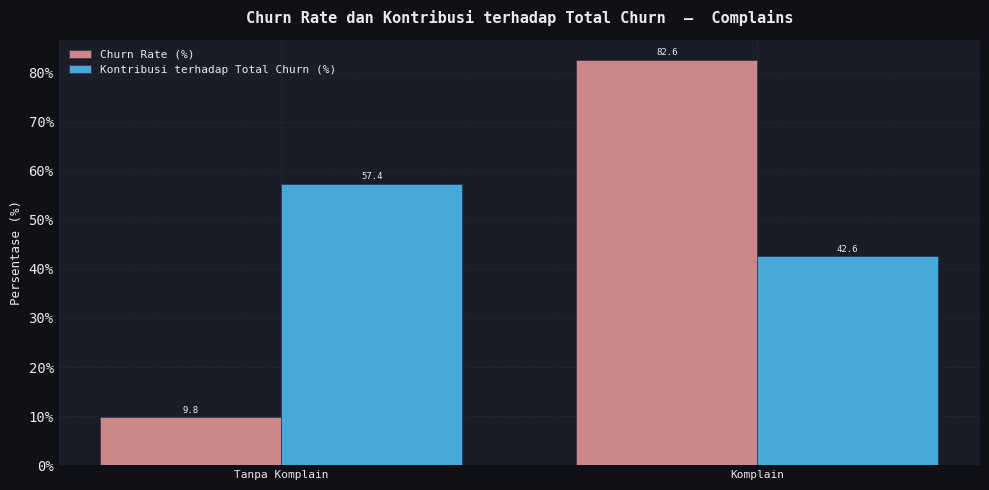


 FEATURE: Subscription_Length 
                 Count    Mean  Median    Std  Min  Max
Churn                                                  
0 — Tidak Churn   2404  32.596    35.0  8.508    3   47
1 — Churn          446  31.684    35.0  9.776    3   45
--------------------------------------------------


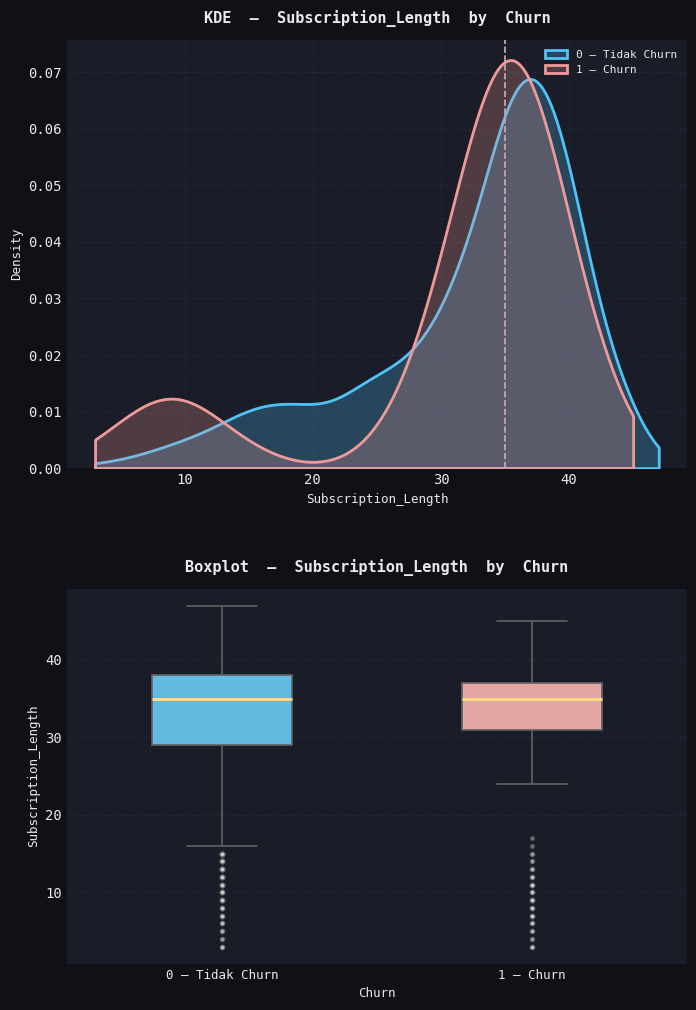


 FEATURE: Charge_Amount 
               count  Churn_Count  Churn_Rate (%)  \
Charge_Amount                                       
0               1575          374       23.746032   
1                559           42        7.513417   
2                362           22        6.077348   
3                192            7        3.645833   
4                 70            1        1.428571   
5                 30            0        0.000000   
6                 11            0        0.000000   
7                 12            0        0.000000   
8                 19            0        0.000000   
9                 13            0        0.000000   
10                 7            0        0.000000   

               Contribution_to_Total_Churn (%)  
Charge_Amount                                   
0                                    83.856502  
1                                     9.417040  
2                                     4.932735  
3                                     1

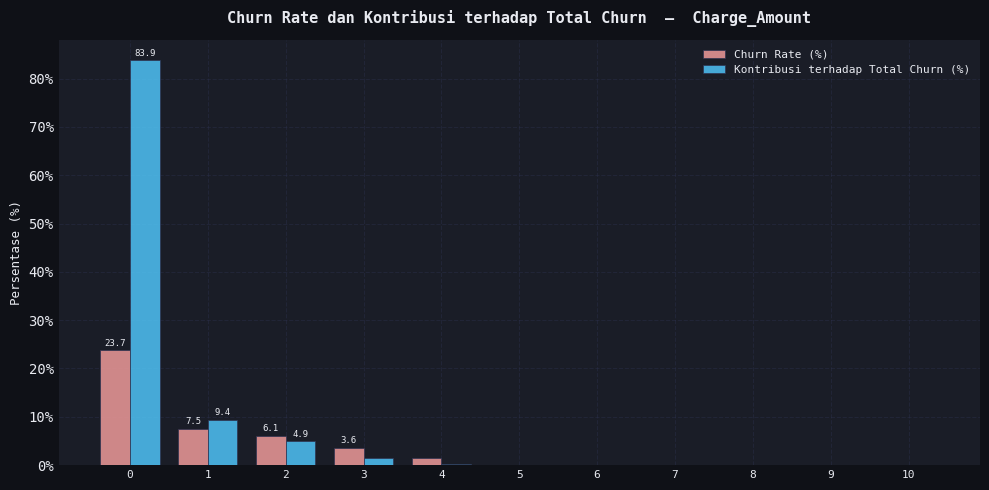


 FEATURE: Seconds_of_Use 
                 Count      Mean  Median       Std  Min    Max
Churn                                                         
0 — Tidak Churn   2404  5069.588  3596.5  4317.853    0  17090
1 — Churn          446  1648.661  1256.5  1532.911    0   6123
--------------------------------------------------


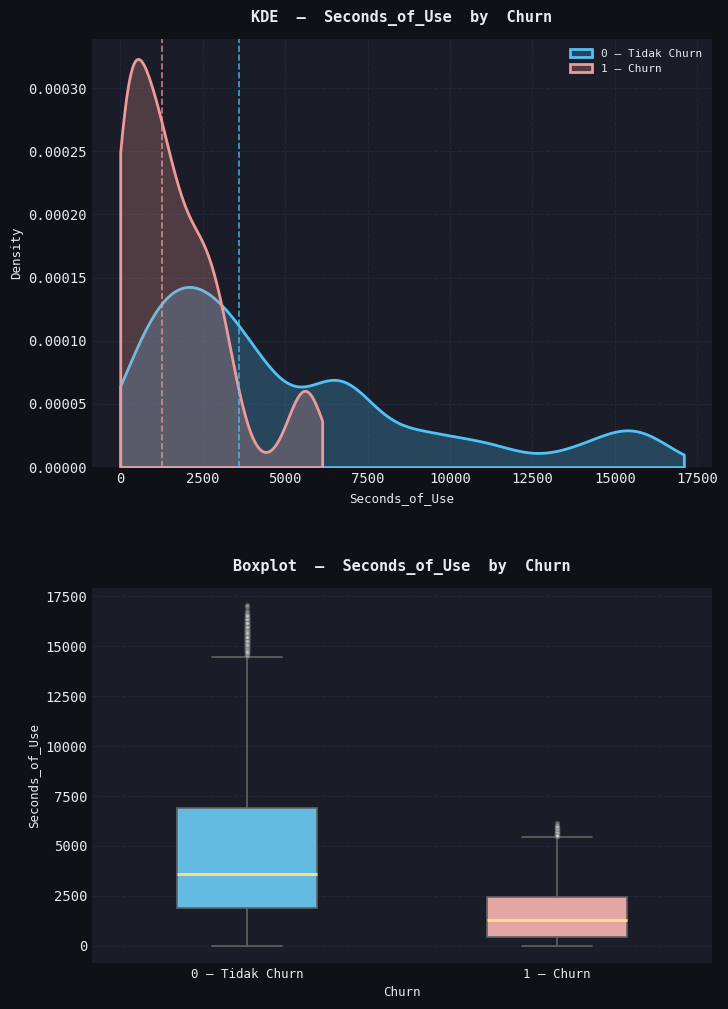


 FEATURE: Frequency_of_use 
                 Count    Mean  Median     Std  Min  Max
Churn                                                   
0 — Tidak Churn   2404  77.866    64.0  58.584    0  255
1 — Churn          446  30.697    29.0  26.091    0  100
--------------------------------------------------


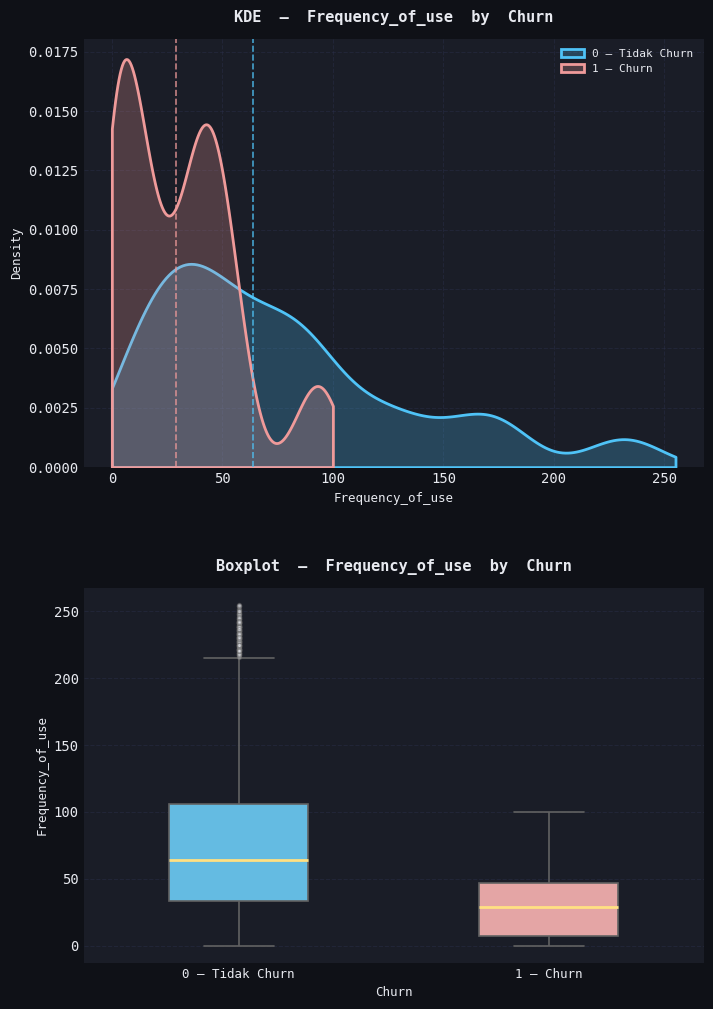


 FEATURE: Frequency_of_SMS 
                 Count    Mean  Median      Std  Min  Max
Churn                                                    
0 — Tidak Churn   2404  84.354    26.0  118.599    0  522
1 — Churn          446  16.850    11.0   24.331    0  204
--------------------------------------------------


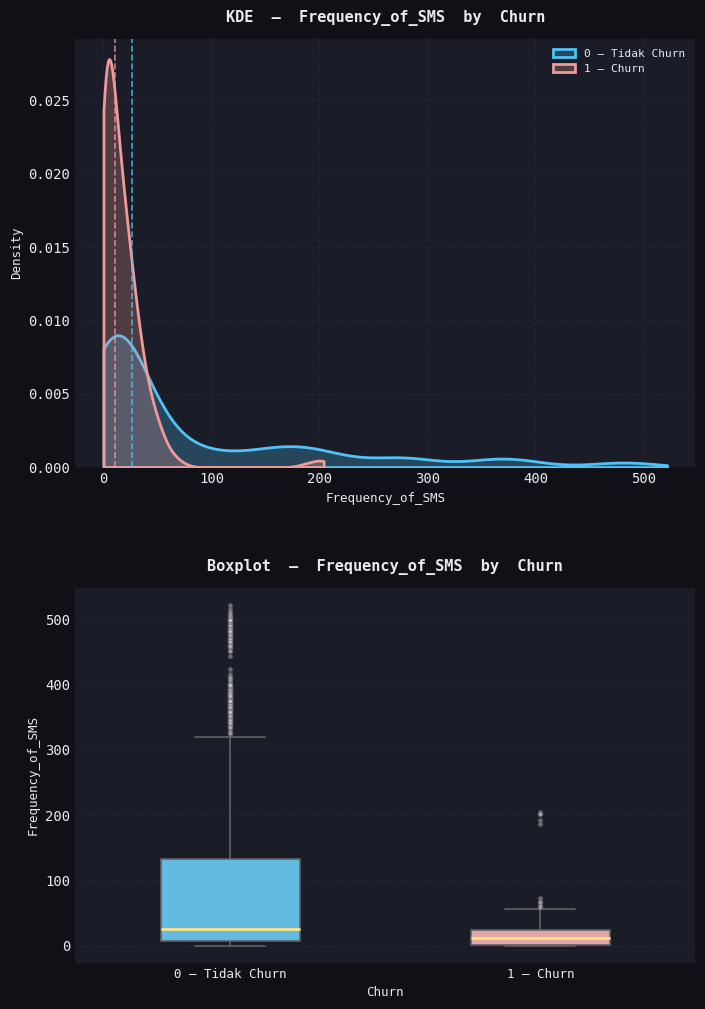


 FEATURE: Distinct_Called_Numbers 
                 Count    Mean  Median     Std  Min  Max
Churn                                                   
0 — Tidak Churn   2404  25.872    24.0  17.415    0   97
1 — Churn          446  13.081    11.0  10.800    0   48
--------------------------------------------------


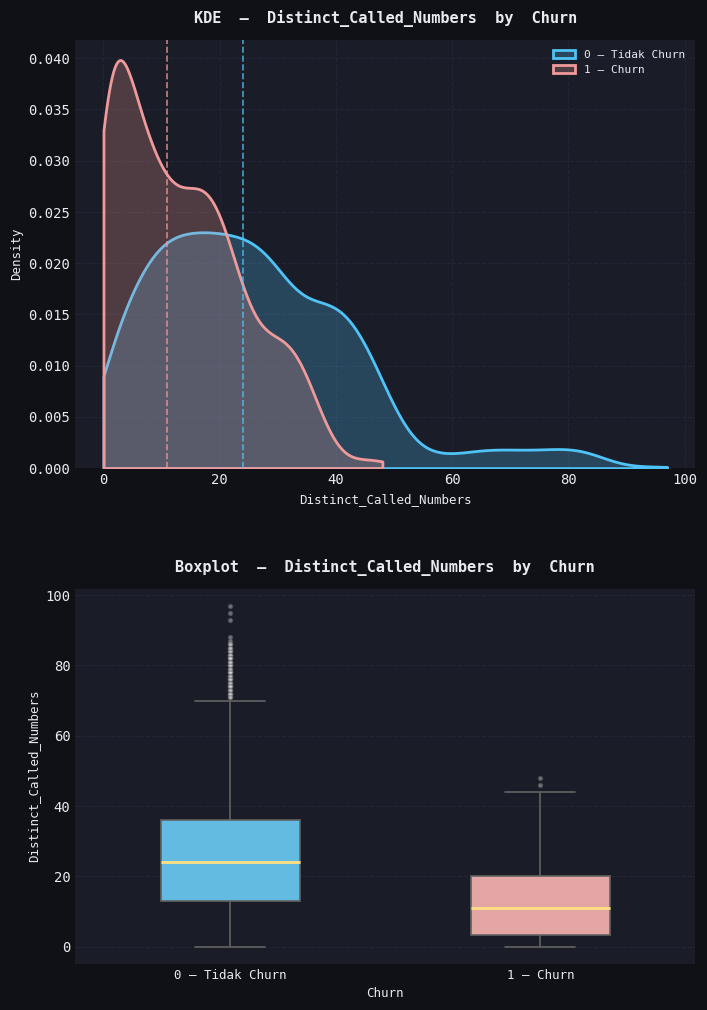


 FEATURE: Age_Group 
           count  Churn_Count  Churn_Rate (%)  Contribution_to_Total_Churn (%)
Age_Group                                                                     
3           1296          213       16.435185                        47.757848
2            921          157       17.046688                        35.201794
4            367           74       20.163488                        16.591928
5            154            2        1.298701                         0.448430
1            112            0        0.000000                         0.000000
--------------------------------------------------


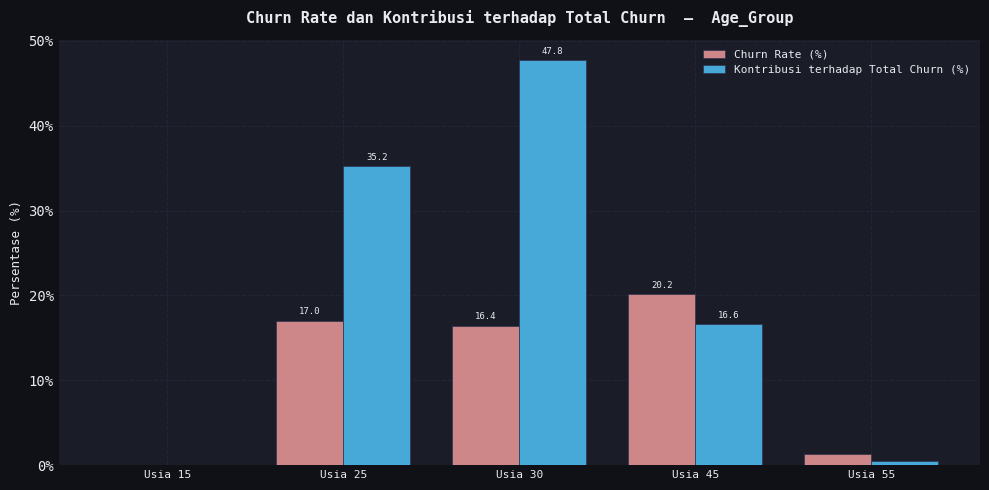


 FEATURE: Tariff_Plan 
             count  Churn_Count  Churn_Rate (%)  \
Tariff_Plan                                       
1             2621          440       16.787486   
2              229            6        2.620087   

             Contribution_to_Total_Churn (%)  
Tariff_Plan                                   
1                                  98.654709  
2                                   1.345291  
--------------------------------------------------


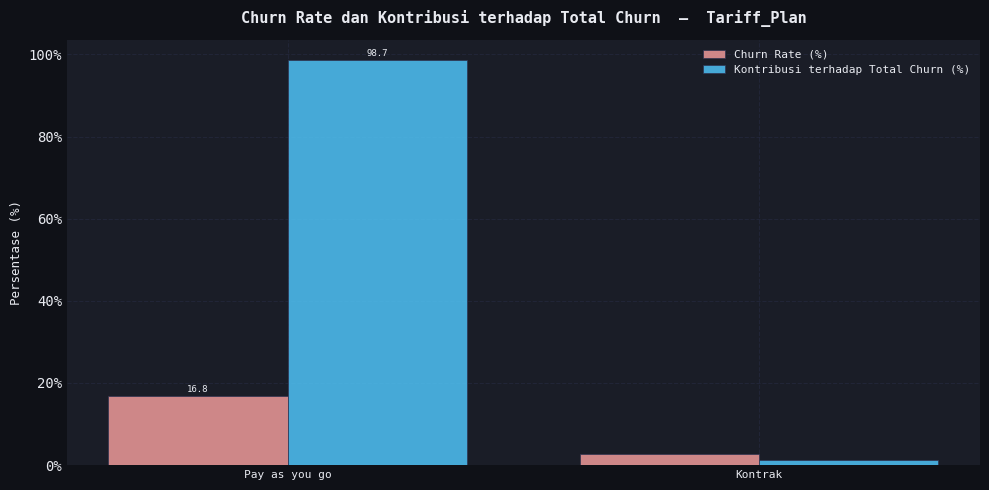


 FEATURE: Status 
        count  Churn_Count  Churn_Rate (%)  Contribution_to_Total_Churn (%)
Status                                                                     
2         684          325       47.514620                        72.869955
1        2166          121        5.586334                        27.130045
--------------------------------------------------


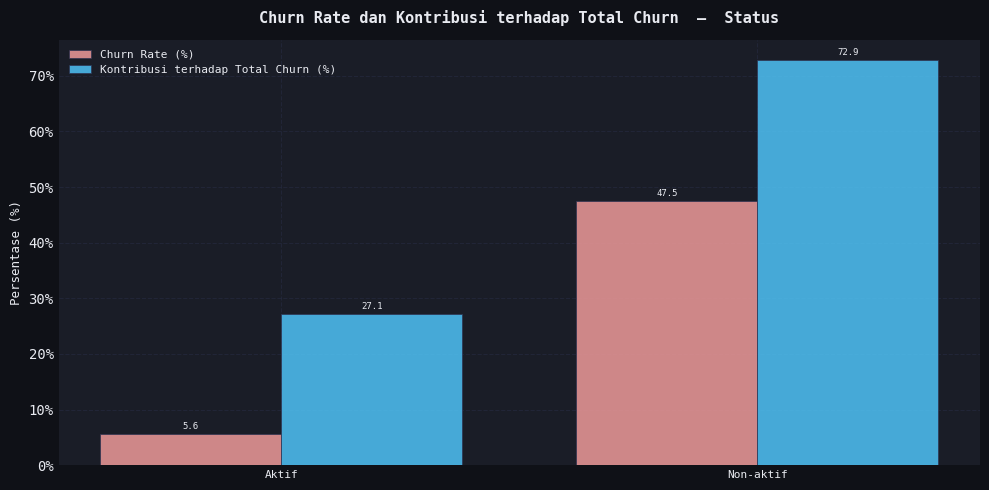


 FEATURE: Age_Binning 
             count  Churn_Count  Churn_Rate (%)  \
Age_Binning                                       
30            1296          213       16.435185   
25             921          157       17.046688   
45             367           74       20.163488   
55             154            2        1.298701   
15             112            0        0.000000   

             Contribution_to_Total_Churn (%)  
Age_Binning                                   
30                                 47.757848  
25                                 35.201794  
45                                 16.591928  
55                                  0.448430  
15                                  0.000000  
--------------------------------------------------


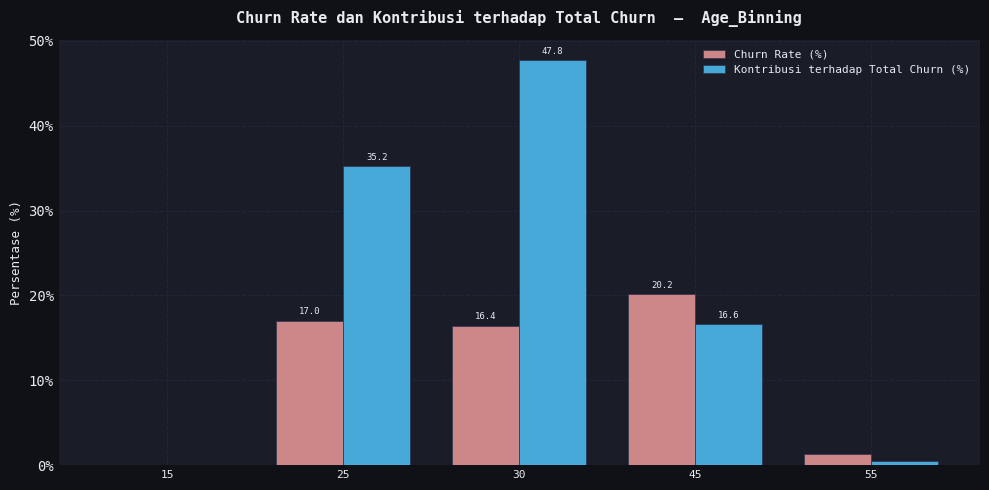


 FEATURE: Customer_Value 
                 Count     Mean   Median      Std  Min       Max
Churn                                                           
0 — Tidak Churn   2404  538.591  271.540  533.607  0.0  2165.280
1 — Churn          446  132.176  102.565  130.934  0.0   987.255
--------------------------------------------------


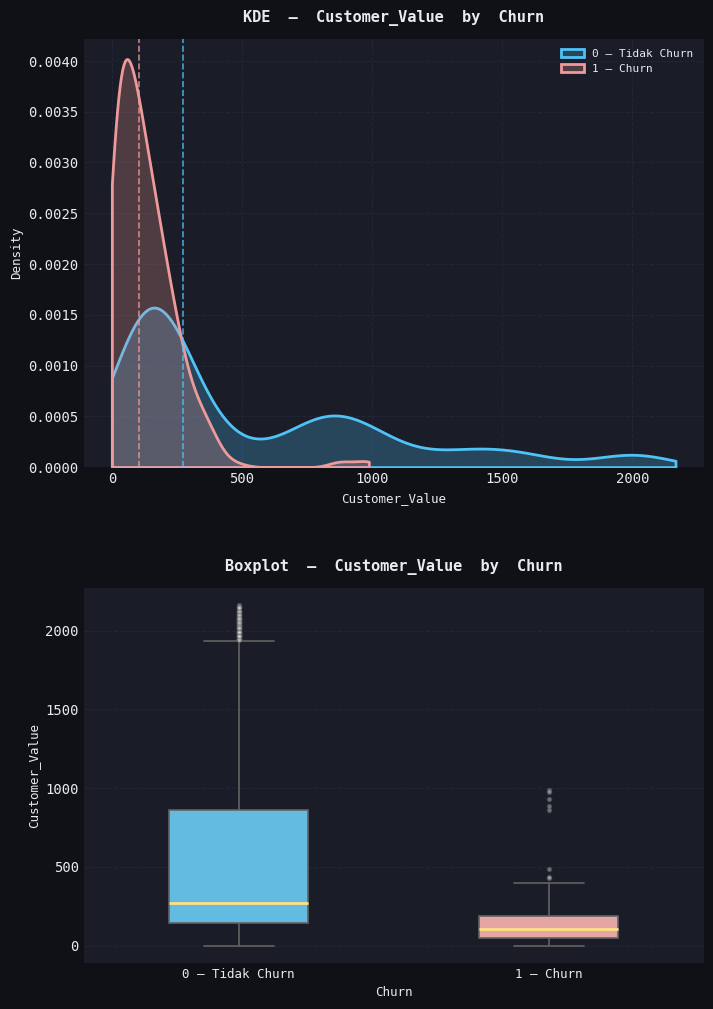

In [26]:
# ─────────────────────────────────────────────────────────────────────────────

ACCENT_0   = "#4fc3f7"   # Tidak Churn
ACCENT_1   = "#ef9a9a"   # Churn
GRID_COLOR = "#2e3250"

total_all_churn = df[TARGET].sum()

for name in df.columns:
    if name in [TARGET, 'id']:
        continue

    print(f"\n{'='*50}")
    print(f" FEATURE: {name} ")
    print('='*50)

    # =========================================================================
    # NUMERIK KONTINU
    # =========================================================================
    if pd.api.types.is_numeric_dtype(df[name]):

        # ── Statistik deskriptif per kelas ───────────────────────────────────
        desc_stats = (
            df.groupby(TARGET)[name]
            .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
            .rename(index={0: '0 — Tidak Churn', 1: '1 — Churn'})
        )
        desc_stats.columns = ['Count', 'Mean', 'Median', 'Std', 'Min', 'Max']
        print(desc_stats.round(3))
        print("-" * 50)

        # ── Visualisasi: KDE (atas) + Boxplot (bawah) — subplot terpisah ───────
        fig, (ax_kde, ax_box) = plt.subplots(
            2, 1,
            figsize=(8, 12),
            facecolor=BG_COLOR,
            gridspec_kw={'height_ratios': [1.6, 1.4], 'hspace': 0.3}
        )

        class_labels = {0: '0 — Tidak Churn', 1: '1 — Churn'}
        palette_map  = {0: ACCENT_0, 1: ACCENT_1}

        # — KDE plot —
        for cls, color in palette_map.items():
            subset = df[df[TARGET] == cls][name].dropna()
            sns.kdeplot(
                subset, ax=ax_kde, cut=0,
                color=color, fill=True, alpha=0.25,
                linewidth=2, label=class_labels[cls]
            )
            ax_kde.axvline(
                subset.median(), color=color,
                linestyle='--', linewidth=1.2, alpha=0.8
            )

        ax_kde.set_title(
            f"KDE  —  {name}  by  {TARGET}",
            fontsize=11, fontweight="bold", pad=12
        )
        ax_kde.set_xlabel(name, fontsize=9)
        ax_kde.set_ylabel("Density", fontsize=9)
        ax_kde.grid(True, axis="y")
        ax_kde.legend(fontsize=8, framealpha=0.2)
        ax_kde.set_facecolor(PANEL_COLOR)
        for spine in ax_kde.spines.values():
            spine.set_edgecolor(GRID_COLOR)

        # — Boxplot —
        sns.boxplot(
            data=df, x=TARGET, y=name, ax=ax_box,
            hue=TARGET,
            palette=palette_map,
            orient='v',
            width=0.45,
            linewidth=1.2,
            legend=False,
            flierprops=dict(marker='o', markerfacecolor=TEXT_COLOR,
                            markersize=3, alpha=0.4, linestyle='none'),
            medianprops=dict(color="#ffe082", linewidth=2),
        )

        ax_box.set_title(
            f"Boxplot  —  {name}  by  {TARGET}",
            fontsize=11, fontweight="bold", pad=12
        )
        ax_box.set_xlabel(TARGET, fontsize=9)
        ax_box.set_ylabel(name, fontsize=9)
        ax_box.set_xticks([0, 1])
        ax_box.set_xticklabels(["0 — Tidak Churn", "1 — Churn"], fontsize=9)
        ax_box.grid(True, axis="y")
        ax_box.set_facecolor(PANEL_COLOR)
        for spine in ax_box.spines.values():
            spine.set_edgecolor(GRID_COLOR)

        plt.show()
        plt.close(fig)

    # =========================================================================
    # KATEGORIKAL  (tidak diubah sama sekali)
    # =========================================================================
    else:
        count_stats = (
            df.groupby(name, observed=True)[TARGET]
            .agg(['count', 'sum'])
            .rename(columns={'sum': 'Churn_Count'})
        )
        count_stats['Churn_Rate (%)']                  = (count_stats['Churn_Count'] / count_stats['count']) * 100
        count_stats['Contribution_to_Total_Churn (%)'] = (count_stats['Churn_Count'] / total_all_churn) * 100

        print(count_stats.sort_values(by='Churn_Count', ascending=False))
        print("-" * 50)

        stats_plot = (
            count_stats[['Churn_Rate (%)', 'Contribution_to_Total_Churn (%)']]
        )

        x      = range(len(stats_plot))
        width  = 0.38
        labels = [CATEGORY_LABELS.get(name, {}).get(v, str(v)) for v in stats_plot.index]

        fig, ax = plt.subplots(figsize=(10, 5), facecolor=BG_COLOR)
        ax.set_facecolor(PANEL_COLOR)

        bars1 = ax.bar([i - width/2 for i in x], stats_plot['Churn_Rate (%)'],
                       width=width, color=ACCENT_1, alpha=0.85,
                       label='Churn Rate (%)', edgecolor=GRID_COLOR, linewidth=0.6)
        bars2 = ax.bar([i + width/2 for i in x], stats_plot['Contribution_to_Total_Churn (%)'],
                       width=width, color=ACCENT_0, alpha=0.85,
                       label='Kontribusi terhadap Total Churn (%)', edgecolor=GRID_COLOR, linewidth=0.6)

        for bar in list(bars1) + list(bars2):
            h = bar.get_height()
            if h >= 3:
                ax.text(bar.get_x() + bar.get_width() / 2, h + 0.5,
                        f"{h:.1f}", ha='center', va='bottom',
                        fontsize=6.5, color=TEXT_COLOR)

        ax.set_title(f"Churn Rate dan Kontribusi terhadap Total Churn  —  {name}",
                     fontsize=11, fontweight="bold", pad=12)
        ax.set_ylabel("Persentase (%)", fontsize=9)
        ax.set_xticks(list(x))
        ax.set_xticklabels(labels, fontsize=8)
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
        ax.grid(True, axis='y')
        ax.legend(fontsize=8, framealpha=0.2)

        for spine in ax.spines.values():
            spine.set_edgecolor(GRID_COLOR)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

## Laporan Analisis Bivariat

---

## 1. **Gambaran Umum Dataset**

Dataset terdiri dari **2.850 pelanggan** dengan **1 variabel target** (`Churn`) dan sejumlah fitur prediktor yang mencakup perilaku penggunaan, demografi, serta atribut kontrak pelanggan.

Distribusi target:
*   **Tidak Churn (0):** 2.404 pelanggan (84,4%)
*   **Churn (1):** 446 pelanggan (15,6%)

Dataset menunjukkan **ketidakseimbangan kelas (class imbalance)** yang cukup signifikan, sehingga perlu diperhatikan saat memilih metrik evaluasi model prediksi. *Accuracy* sebaiknya tidak menjadi metrik utama, dan metrik evaluasi diputuskan saat modeling.

---

## 2. **Analisis Fitur Kategorikal**

### 2,1 `Complains` : Asosiasi Terkuat

| Nilai | Count | Churn Count | Churn Rate | Kontribusi ke Total Churn |
|---|---|---|---|---|
| 0 (No complaint) | 2.620 | 256 | 9,77% | 57,40% |
| 1 (Complaint) | 230 | 190 | **82,61%** | 42,60% |

**Temuan:**
Baris dengan komplain punya *churn rate* **82,6%**, berbanding 9,8% pada baris tanpa komplain. Baris ini hanya 8,1% dari total, tetapi menyumbang **42,6%** kejadian *churn*. Hubungan ini asosiatif, dan belum menunjukkan bahwa penanganan komplain akan menurunkan *churn*.

---

### 2,2 `Status` : Indikator Keaktifan Akun

| Nilai | Count | Churn Count | Churn Rate | Kontribusi ke Total Churn |
|---|---|---|---|---|
| 2 (non-active) | 684 | 325 | **47,51%** | 72,87% |
| 1 (active) | 2.166 | 121 | 5,59% | 27,13% |

**Temuan:**
Baris non-aktif punya *churn rate* **47,5%**, berbanding 5,6% pada baris aktif, dan menyumbang **72,9%** kejadian *churn*. Dokumentasi UCI tidak menjelaskan cara `Status` ditentukan, jadi asosiasi ini perlu dibaca hati-hati.

---

### 2,3 `Tariff_Plan` : Ketimpangan Antar Paket

| Nilai | Count | Churn Count | Churn Rate | Kontribusi ke Total Churn |
|---|---|---|---|---|
| 1 (Pay as you go) | 2.621 | 440 | 16,79% | **98,65%** |
| 2 (Kontrak) | 229 | 6 | 2,62% | 1,35% |

**Temuan:**
Hampir semua *churn* berada di Pay as you go, tetapi Pay as you go juga mencakup 92% baris. *Churn rate* Pay as you go 16,8%, berbanding 2,6% pada Kontrak. Jumlah baris Kontrak hanya 229, dan penyebab perbedaannya belum bisa disimpulkan dari data ini.

---

### 2,4 `Age_Group` dan `Age_Binning` : Redundansi Fitur

| Age_Group | Age_Binning | Count | Churn Rate | Kontribusi |
|---|---|---|---|---|
| 1 | 15 | 112 | 0,00% | 0,00% |
| 2 | 25 | 921 | 17,05% | 35,20% |
| 3 | 30 | 1.296 | 16,44% | 47,76% |
| 4 | 45 | 367 | 20,16% | 16,59% |
| 5 | 55 | 154 | 1,30% | 0,45% |

**Temuan:**
Kedua kolom berpasangan satu-satu, jadi `Age_Group` dipakai untuk modeling dan `Age_Binning` tidak masuk fitur model. *Churn rate* relatif serupa di kelompok 2 sampai 4 (16% sampai 20%), sedangkan kelompok 1 dan 5 hampir tanpa *churn*, dengan jumlah baris yang lebih sedikit. Pola ini tidak searah, jadi korelasi yang kecil tidak berarti usia tidak berhubungan dengan *churn*.

---

### 2,5 `Charge_Amount` : Tingkat Tagihan

| Nilai | Churn Rate | Kontribusi |
|---|---|---|
| 0 | 23,75% | 83,86% |
| 1 | 7,51% | 9,42% |
| 2 | 6,08% | 4,93% |
| ≥ 3 | ≤ 3,65% | < 2% |

**Temuan:**
Tingkat `Charge_Amount` yang lebih tinggi berasosiasi dengan *churn rate* yang lebih rendah, dan nilai 0 menyumbang 83,9% kejadian *churn*. Kolom ini juga berhubungan dengan penggunaan, jadi hubungan ini belum bisa dibaca sebagai hubungan langsung.

---

## 3. **Analisis Fitur Numerik**

### 3,1 `Seconds_of_Use` : Durasi Penggunaan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 5.069 | 3.596 | 4.317 |
| Churn | **1.648** | **1.256** | 1.532 |

**Temuan:**
Median baris *churn* sekitar sepertiga dari baris tidak *churn* (1.256 berbanding 3.596). Satuan dan arti kolom mengikuti dokumentasi UCI, yaitu total detik panggilan.

---

### 3,2 `Frequency_of_use` : Frekuensi Penggunaan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 77,87 | 64 | 58,58 |
| Churn | **30,70** | **29** | 26,09 |

**Temuan:**
Median baris *churn* kurang dari separuh baris tidak *churn* (29 berbanding 64). Pola ini searah dengan `Seconds_of_Use`.

---

### 3,3 `Distinct_Called_Numbers` : Jumlah Nomor Unik yang Dihubungi

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 25,87 | 24 | 17,41 |
| Churn | **13,08** | **11** | 10,80 |

**Temuan:**
Median baris *churn* lebih rendah (11 berbanding 24). Dokumentasi UCI menulis *total number of distinct phone calls*, jadi apa yang dihitung belum sepenuhnya jelas, dan hubungannya hanya dibaca sebagai asosiasi.

---

### 3,4 `Frequency_of_SMS` : Frekuensi SMS

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 84,35 | 26 | 118,60 |
| Churn | **16,85** | **11** | 24,33 |

**Temuan:**
Median baris *churn* lebih rendah (11 berbanding 26). Simpangan baku kelas tidak *churn* besar (118,60), jadi sebarannya menceng dan nilainya sangat beragam.

---

### 3,5 `Customer_Value` : Nilai Pelanggan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 538,59 | 271,54 | 533,61 |
| Churn | **132,18** | **102,57** | 130,93 |

**Temuan:**
Median baris *churn* sekitar 38% dari baris tidak *churn* (102,57 berbanding 271,54). Rumus kolom ini tidak dijelaskan dokumentasi UCI, dan hubungannya dengan fitur lain diperiksa di bagian multikolinearitas.

---

### 3,6 `Call_Failure` : Jumlah Kegagalan Panggilan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 7,79 | 6 | 7,22 |
| Churn | 7,86 | 6 | 7,87 |

**Temuan:**
Rata-rata, median, dan simpangan baku kedua kelas hampir sama, jadi perbandingan ini tidak menunjukkan perbedaan yang berarti.

---

### 3,7 `Subscription_Length` : Lama Berlangganan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 32,60 | 35 | 8,51 |
| Churn | 31,68 | 35 | 9,78 |

**Temuan:**
Median kedua kelas sama (35), dan rata-ratanya hampir sama (31,68 berbanding 32,60). Satuan kolom ini menurut dokumentasi UCI adalah bulan. Selisih ini tidak dipakai sebagai klaim tentang pelanggan baru.

---

## 4. **Ringkasan Asosiasi Bivariat**

Tabel ini hanya merangkum perbandingan dua variabel, dan bukan keputusan fitur.

| Kekuatan perbedaan | Fitur | Yang terlihat |
|---|---|---|
| Besar | `Complains`, `Status` | *Churn rate* antarkategori sangat berbeda |
| Sedang | `Seconds_of_Use`, `Frequency_of_use`, `Distinct_Called_Numbers`, `Customer_Value`, `Frequency_of_SMS`, `Charge_Amount` | Nilai baris *churn* cenderung lebih rendah |
| Kecil atau tidak searah | `Tariff_Plan`, `Age_Group` | Perbedaan ada, tetapi jumlah baris antarkategori timpang atau polanya tidak searah |
| Hampir tidak ada | `Subscription_Length`, `Call_Failure` | Ringkasan kedua kelas hampir sama |

---

## 5. **Ciri yang Berasosiasi dengan Churn**

Pada data ini, *churn rate* cenderung lebih tinggi pada baris dengan ciri berikut. Daftar ini asosiatif, dan belum diuji sebagai aturan prediksi:

*   Ada komplain (`Complains` = 1).
*   Berstatus non-aktif (`Status` = 2).
*   Memakai Pay as you go (`Tariff_Plan` = 1).
*   `Seconds_of_Use`, `Frequency_of_use`, dan `Distinct_Called_Numbers` rendah.
*   `Charge_Amount` bernilai 0.
*   `Customer_Value` rendah.

In [27]:
cat = [
    'Complains',
    'Tariff_Plan',
    'Status',
    'Age_Group',
    'Age_Binning',
    'Charge_Amount'
]

for col in cat:
    if col in df.columns:
        df[col] = df[col].astype('int64')

# B. Uji Korelasi & Asosiasi

## **Metode: Spearman**

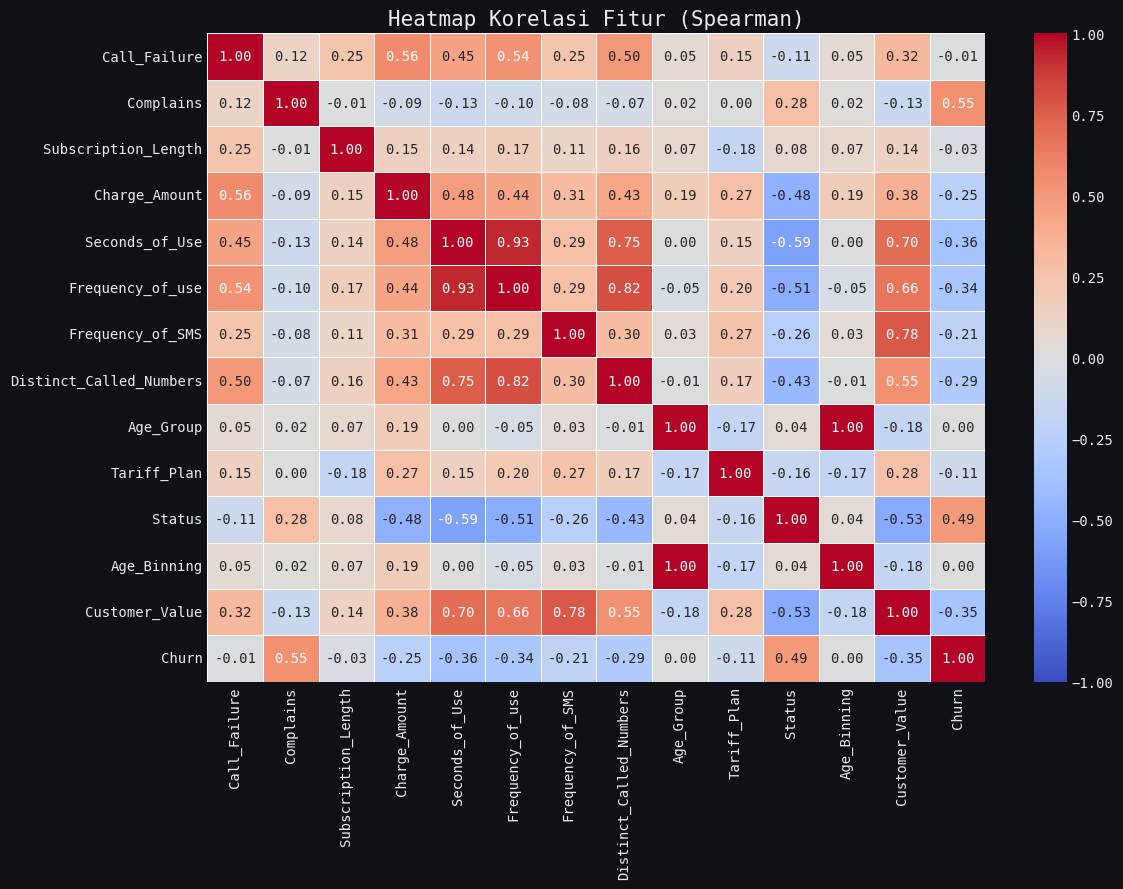

In [28]:
plt.figure(figsize=(12, 9))
corr = df.corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Fitur (Spearman)', fontsize=15)
plt.tight_layout()
plt.show()

## **Metode: Pearson dan Point-Biserial Correlation**

In [29]:
# ══════════════════════════════════════════════════
# BAGIAN A: Point-Biserial Correlation vs Churn
# ══════════════════════════════════════════════════

print('=' * 60)
print('  POINT-BISERIAL CORRELATION — SETIAP FITUR VS CHURN')
print('=' * 60)

fitur_semua = [c for c in df.columns if c != TARGET]
pb_results  = []

for col in fitur_semua:
    try:
        corr, pval = pointbiserialr(df[TARGET], df[col])
        pb_results.append({
            'Fitur':       col,
            'Korelasi':    round(corr, 4),
            'Abs Korelasi':round(abs(corr), 4),
            'P-Value':     round(pval, 4),
            'Signifikan':  'Ya' if pval < 0.05 else 'Tidak',
        })
    except Exception as e:
        print(f'  Gagal: {col} — {e}')

pb_df = pd.DataFrame(pb_results).sort_values('Abs Korelasi', ascending=False)
print(pb_df.assign(**{'P-Value': pb_df['P-Value'].map(format_p)}).to_string(index=False))

print('\nInterpretasi arah korelasi:')
print('  Positif (+) : nilai fitur tinggi cenderung CHURN')
print('  Negatif (-) : nilai fitur tinggi cenderung TIDAK CHURN')

  POINT-BISERIAL CORRELATION — SETIAP FITUR VS CHURN
                  Fitur  Korelasi  Abs Korelasi P-Value Signifikan
              Complains    0.5461        0.5461 < 0.001         Ya
                 Status    0.4929        0.4929 < 0.001         Ya
       Frequency_of_use   -0.2986        0.2986 < 0.001         Ya
         Seconds_of_Use   -0.2960        0.2960 < 0.001         Ya
         Customer_Value   -0.2871        0.2871 < 0.001         Ya
Distinct_Called_Numbers   -0.2703        0.2703 < 0.001         Ya
       Frequency_of_SMS   -0.2189        0.2189 < 0.001         Ya
          Charge_Amount   -0.2017        0.2017 < 0.001         Ya
            Tariff_Plan   -0.1060        0.1060 < 0.001         Ya
    Subscription_Length   -0.0380        0.0380  0.0426         Ya
            Age_Binning   -0.0115        0.0115  0.5397      Tidak
              Age_Group   -0.0059        0.0059  0.7533      Tidak
           Call_Failure    0.0033        0.0033  0.8598      Tidak

Interpre

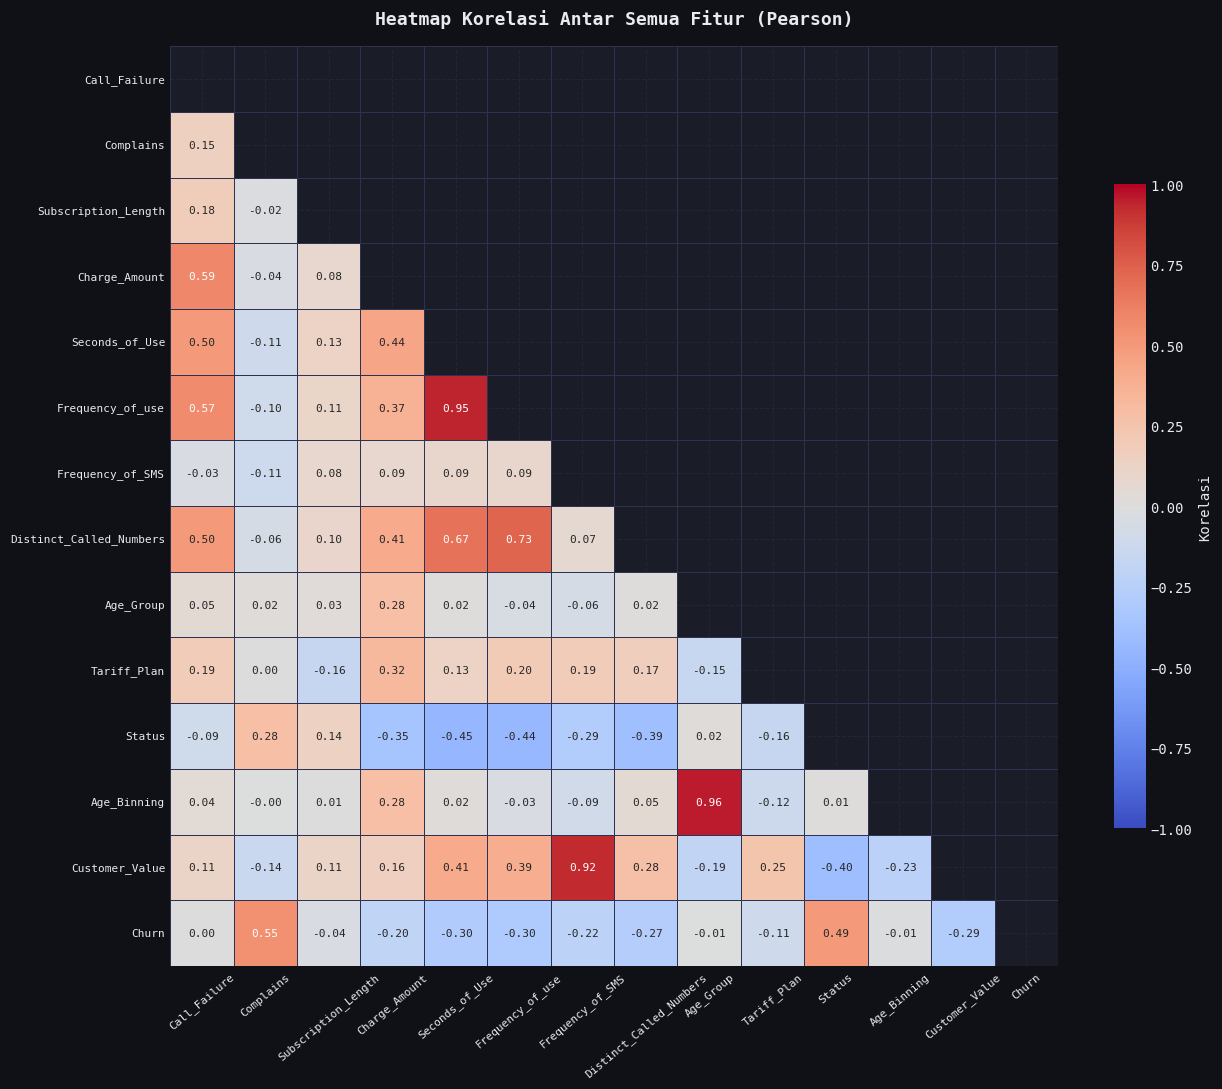

In [30]:
# ══════════════════════════════════════════════════
# BAGIAN B: Heatmap Korelasi Antar Semua Fitur
# ══════════════════════════════════════════════════

corr_matrix = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13, 11), facecolor=BG_COLOR)
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True  # sembunyikan segitiga atas (duplikat)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    ax=ax,
    linewidths=0.4,
    linecolor='#2e3250',
    annot_kws={'size': 8},
    cbar_kws={'shrink': 0.7, 'label': 'Korelasi'},
)

ax.set_title('Heatmap Korelasi Antar Semua Fitur (Pearson)',
             fontsize=13, fontweight='bold', pad=16)
ax.tick_params(axis='x', rotation=40, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.show()

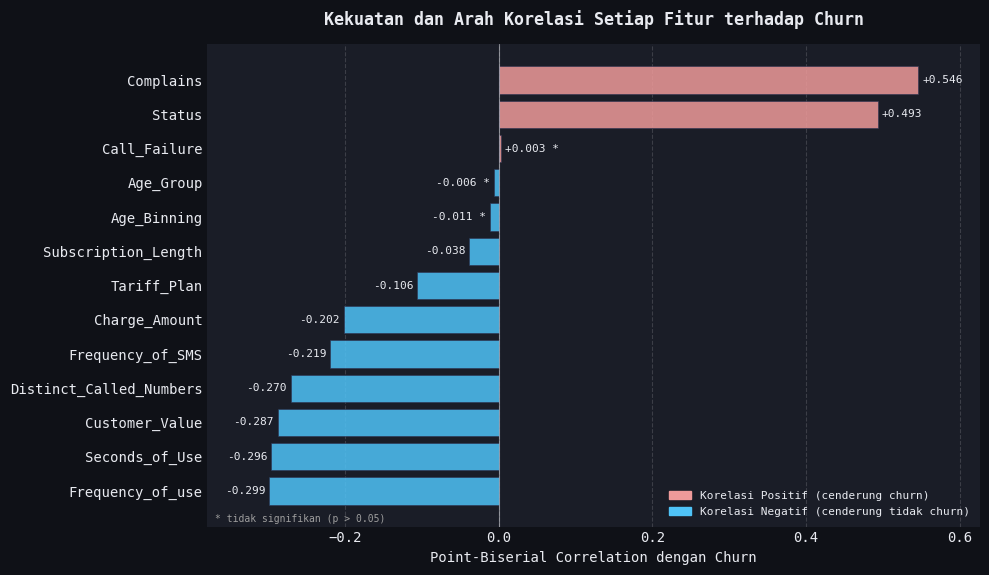

In [31]:
# ══════════════════════════════════════════════════
# BAGIAN C: Bar Chart Korelasi Fitur vs Churn
# ══════════════════════════════════════════════════

pb_plot = pb_df[pb_df['Fitur'] != TARGET].sort_values('Korelasi')
colors  = ['#ef9a9a' if v > 0 else '#4fc3f7' for v in pb_plot['Korelasi']]

fig, ax = plt.subplots(figsize=(10, max(5, len(pb_plot) * 0.45)),
                        facecolor=BG_COLOR)

bars = ax.barh(pb_plot['Fitur'], pb_plot['Korelasi'],
               color=colors, edgecolor='#2e3250', linewidth=0.5, alpha=0.85)

for bar, val, sig in zip(bars, pb_plot['Korelasi'], pb_plot['Signifikan']):
    x_pos = bar.get_width() + (0.005 if val >= 0 else -0.005)
    ha    = 'left' if val >= 0 else 'right'
    label = f'{val:+.3f}' + ('' if sig == 'Ya' else ' *')
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2,
            label, va='center', ha=ha, fontsize=8, color=TEXT_COLOR)

ax.axvline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.5)
ax.set_xlim(pb_plot['Korelasi'].min() - 0.08, pb_plot['Korelasi'].max() + 0.08)
ax.set_xlabel('Point-Biserial Correlation dengan Churn', fontsize=10)
ax.set_title('Kekuatan dan Arah Korelasi Setiap Fitur terhadap Churn',
             fontsize=12, fontweight='bold', pad=14)
ax.grid(True, axis='x', linestyle='--', alpha=0.15, color='#ffffff')
ax.grid(False, axis='y')

leg = [mpatches.Patch(color='#ef9a9a', label='Korelasi Positif (cenderung churn)'),
       mpatches.Patch(color='#4fc3f7', label='Korelasi Negatif (cenderung tidak churn)'),]
ax.legend(handles=leg, fontsize=8, framealpha=0.15, loc='lower right')
ax.annotate('* tidak signifikan (p > 0.05)', xy=(0.01, 0.01),
            xycoords='axes fraction', fontsize=7, color='#9e9e9e')

plt.tight_layout()
plt.show()

In [32]:
# ══════════════════════════════════════════════════
# BAGIAN D: Ringkasan Fitur Terkuat dan Terlemah
# ══════════════════════════════════════════════════

print('\n' + '=' * 60)
print('  RINGKASAN KORELASI FITUR VS CHURN')
print('=' * 60)

top5    = pb_df[pb_df['Signifikan'] == 'Ya'].head(5)
bottom5 = pb_df[pb_df['Signifikan'] == 'Ya'].tail(5)
tidak_sig = pb_df[pb_df['Signifikan'] == 'Tidak']

print('\nTop 5 Fitur Paling Berkorelasi dengan Churn:')
for _, r in top5.iterrows():
    arah = 'CHURN' if r['Korelasi'] > 0 else 'TIDAK CHURN'
    print(f'  {r["Fitur"]:<30} r = {r["Korelasi"]:+.4f}  → cenderung {arah}')

print('\nFitur dengan Korelasi Menengah (peringkat 6-10):')
for _, r in bottom5.iterrows():
    print(f'  {r["Fitur"]:<30} r = {r["Korelasi"]:+.4f}')

if len(tidak_sig) > 0:
    print(f'\nFitur Tidak Signifikan (p > 0.05):')
    for _, r in tidak_sig.iterrows():
        print(f'  {r["Fitur"]:<30} r = {r["Korelasi"]:+.4f}  p = {r["P-Value"]:.4f}')
else:
    print('\nSemua fitur signifikan secara statistik (p < 0.05)')


  RINGKASAN KORELASI FITUR VS CHURN

Top 5 Fitur Paling Berkorelasi dengan Churn:
  Complains                      r = +0.5461  → cenderung CHURN
  Status                         r = +0.4929  → cenderung CHURN
  Frequency_of_use               r = -0.2986  → cenderung TIDAK CHURN
  Seconds_of_Use                 r = -0.2960  → cenderung TIDAK CHURN
  Customer_Value                 r = -0.2871  → cenderung TIDAK CHURN

Fitur dengan Korelasi Menengah (peringkat 6-10):
  Distinct_Called_Numbers        r = -0.2703
  Frequency_of_SMS               r = -0.2189
  Charge_Amount                  r = -0.2017
  Tariff_Plan                    r = -0.1060
  Subscription_Length            r = -0.0380

Fitur Tidak Signifikan (p > 0.05):
  Age_Binning                    r = -0.0115  p = 0.5397
  Age_Group                      r = -0.0059  p = 0.7533
  Call_Failure                   r = +0.0033  p = 0.8598


In [33]:
# Analisis: Uji Non-Linear Fitur Lemah — Kruskal-Wallis


FITUR_LEMAH  = ['Call_Failure', 'Age_Group', 'Age_Binning', 'Subscription_Length']


# ── Hitung PB (atau ambil dari pb_df jika sudah ada)
if 'pb_df' in dir():
    pb_dict = pb_df.set_index('Fitur')[['Korelasi','P-Value']].to_dict('index')
else:
    pb_dict = {}
    for col in FITUR_LEMAH:
        corr, pval = pointbiserialr(df[TARGET], df[col])
        pb_dict[col] = {'Korelasi': round(corr,4), 'P-Value': round(pval,4)}


# ══════════════════════════════════════════════════════
# BAGIAN A: Tabel Perbandingan PB vs Kruskal-Wallis
# ══════════════════════════════════════════════════════

print('=' * 72)
print('  UJI NON-LINEAR — Point-Biserial vs Kruskal-Wallis')
print('=' * 72)
print()
print('  Point-Biserial : mengukur hubungan LINEAR saja')
print('  Kruskal-Wallis : membandingkan peringkat nilai antarkelas, jadi bisa melewatkan pola tidak searah')
print()
print('  Interpretasi:')
print('  PB tidak sig + KW tidak sig → tidak terdeteksi oleh kedua uji')
print('  PB tidak sig + KW signifikan → ada hubungan NON-LINEAR')
print('  PB signifikan + KW signifikan → hubungan linear + non-linear')
print()
print(f'  {"Fitur":<25} {"PB r":>7} {"PB p":>8} {"KW stat":>9} '
      f'{"KW p":>8}  {"Kesimpulan"}')
print('  ' + '-' * 78)

kw_results = {}
for col in FITUR_LEMAH:
    if col not in df.columns:
        continue

    grp0      = df[df[TARGET] == 0][col].dropna()
    grp1      = df[df[TARGET] == 1][col].dropna()
    kw_stat, kw_p = kruskal(grp0, grp1)
    kw_results[col] = {'stat': kw_stat, 'p': kw_p}

    pb_r   = pb_dict.get(col, {}).get('Korelasi', 0)
    pb_p   = pb_dict.get(col, {}).get('P-Value',  1)
    pb_sig = pb_p  < 0.05
    kw_sig = kw_p  < 0.05

    if   not pb_sig and not kw_sig: kesimpulan = 'Tidak terdeteksi'
    elif not pb_sig and kw_sig:     kesimpulan = 'Non-linear ← perlu binning'
    elif pb_sig     and kw_sig:     kesimpulan = 'Linear + non-linear'
    else:                           kesimpulan = 'Lemah linear saja'

    print(f'  {col:<25} {pb_r:>+7.4f} {pb_p:>8.4f} {kw_stat:>9.3f} '
          f'{kw_p:>8.4f}  {kesimpulan}')

  UJI NON-LINEAR — Point-Biserial vs Kruskal-Wallis

  Point-Biserial : mengukur hubungan LINEAR saja
  Kruskal-Wallis : membandingkan peringkat nilai antarkelas, jadi bisa melewatkan pola tidak searah

  Interpretasi:
  PB tidak sig + KW tidak sig → tidak terdeteksi oleh kedua uji
  PB tidak sig + KW signifikan → ada hubungan NON-LINEAR
  PB signifikan + KW signifikan → hubungan linear + non-linear

  Fitur                        PB r     PB p   KW stat     KW p  Kesimpulan
  ------------------------------------------------------------------------------
  Call_Failure              +0.0033   0.8598     0.614   0.4331  Tidak terdeteksi
  Age_Group                 -0.0059   0.7533     0.067   0.7956  Tidak terdeteksi
  Age_Binning               -0.0115   0.5397     0.067   0.7956  Tidak terdeteksi
  Subscription_Length       -0.0380   0.0426     3.112   0.0777  Lemah linear saja


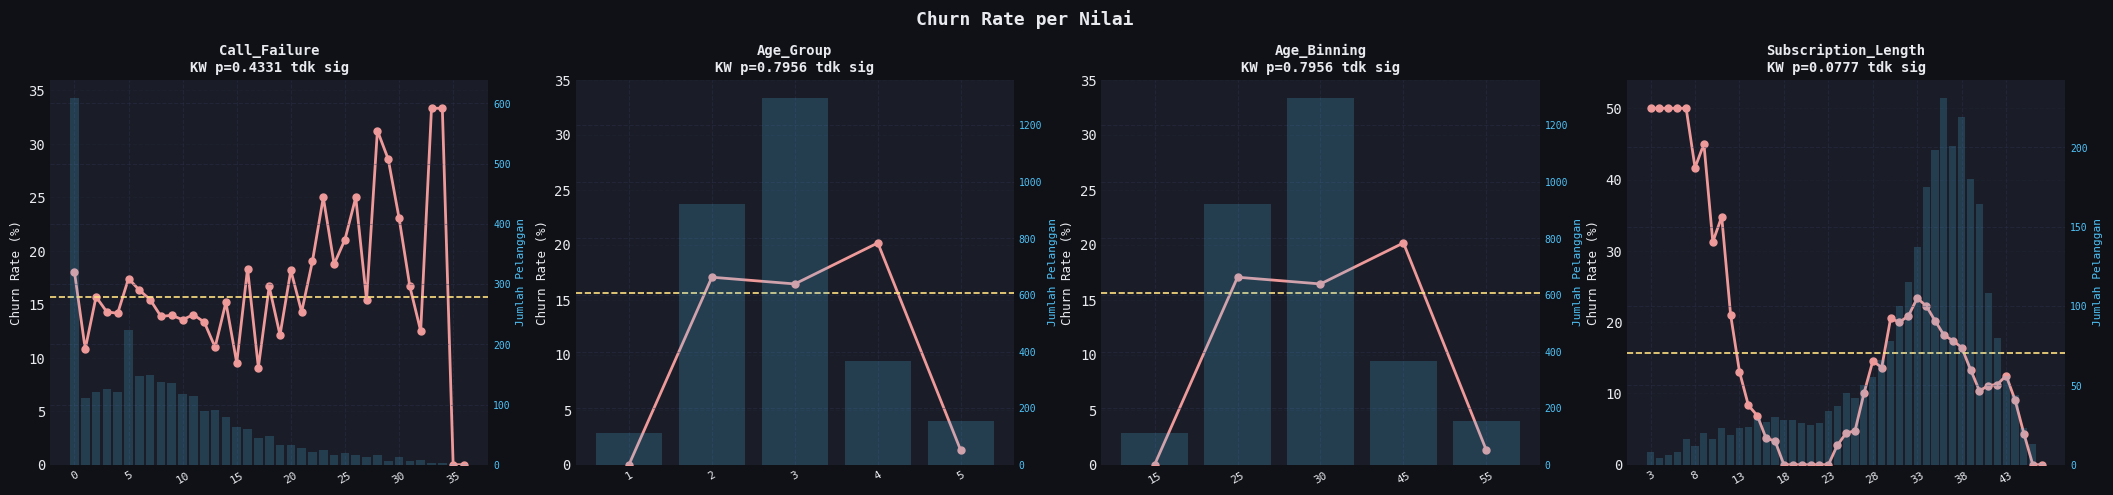

In [34]:
# ══════════════════════════════════════════════════════
# BAGIAN B: Visualisasi Churn Rate per Nilai
# Untuk melihat secara visual pola non-linear yang mungkin ada
# ══════════════════════════════════════════════════════

fig, axes = plt.subplots(1, len(FITUR_LEMAH),
                          figsize=(6.5 * len(FITUR_LEMAH), 5),
                          facecolor=BG_COLOR)
fig.suptitle('Churn Rate per Nilai',
             fontsize=13, fontweight='bold', y=1.02)

for ax, col in zip(axes, FITUR_LEMAH):
    if col not in df.columns:
        continue

    churn_rate = (df.groupby(col)[TARGET]
                  .mean().reset_index().sort_values(col))
    counts     = df[col].value_counts().sort_index()

    # Bar: frekuensi pelanggan (axis kanan)
    ax2 = ax.twinx()
    ax2.bar(range(len(counts)), counts.values,
            color='#4fc3f7', alpha=0.20)
    ax2.set_ylabel('Jumlah Pelanggan', color='#4fc3f7', fontsize=8)
    ax2.tick_params(axis='y', colors='#4fc3f7', labelsize=7)

    # Line: churn rate (axis kiri)
    x_pos = [list(counts.index).index(v)
              for v in churn_rate[col] if v in list(counts.index)]
    ax.plot(x_pos, churn_rate[TARGET].values * 100,
            color='#ef9a9a', linewidth=2, marker='o', markersize=5)
    ax.axhline(df[TARGET].mean() * 100,
               color='#ffe082', linestyle='--', linewidth=1.2,
               label=f'Avg ({df[TARGET].mean()*100:.1f}%)')

    # Anotasi KW result
    kw_p   = kw_results[col]['p']
    kw_lbl = f'KW p={kw_p:.4f} {"sig" if kw_p < 0.05 else "tdk sig"}'

    tick_step = 5 if len(counts) > 15 else 1
    tick_positions = list(range(0, len(counts), tick_step))
    ax.set_xticks(tick_positions)
    ax.set_xticklabels([str(counts.index[i]) for i in tick_positions],
                        fontsize=8, rotation=30)
    ax.set_ylabel('Churn Rate (%)', fontsize=9)
    ax.set_title(f'{col}\n{kw_lbl}', fontsize=10, fontweight='bold')
    ax.set_ylim(0, max(35, churn_rate[TARGET].max() * 100 * 1.08))
    ax.grid(True, axis='y', linestyle='--', alpha=0.15, color=GRID_COLOR)

In [35]:
# ══════════════════════════════════════════════════════
# BAGIAN C: Kesimpulan
# ══════════════════════════════════════════════════════

print('\n' + '=' * 72)
print('  KESIMPULAN UJI NON-LINEAR')
print('=' * 72)

for col in FITUR_LEMAH:
    pb_p   = pb_dict.get(col, {}).get('P-Value', 1)
    kw_p   = kw_results[col]['p']
    pb_sig = pb_p < 0.05
    kw_sig = kw_p < 0.05

    if not pb_sig and not kw_sig:
        verdict = '❌ Tidak terdeteksi oleh kedua uji'
    elif not pb_sig and kw_sig:
        verdict = '⚠  Terdeteksi Kruskal-Wallis saja'
    else:
        verdict = '✅ Terdeteksi minimal oleh satu uji'

    print(f'\n  {col}')
    print(f'  PB : p={pb_p:.4f} → {"signifikan" if pb_sig else "tidak signifikan"}')
    print(f'  KW : p={kw_p:.4f} → {"signifikan" if kw_sig else "tidak signifikan"}')
    print(f'  → {verdict}')


  KESIMPULAN UJI NON-LINEAR

  Call_Failure
  PB : p=0.8598 → tidak signifikan
  KW : p=0.4331 → tidak signifikan
  → ❌ Tidak terdeteksi oleh kedua uji

  Age_Group
  PB : p=0.7533 → tidak signifikan
  KW : p=0.7956 → tidak signifikan
  → ❌ Tidak terdeteksi oleh kedua uji

  Age_Binning
  PB : p=0.5397 → tidak signifikan
  KW : p=0.7956 → tidak signifikan
  → ❌ Tidak terdeteksi oleh kedua uji

  Subscription_Length
  PB : p=0.0426 → signifikan
  KW : p=0.0777 → tidak signifikan
  → ✅ Terdeteksi minimal oleh satu uji


## **Metode: Cramér's V**

In [36]:
# Analisis (Lanjutan): Cramér's V Asosiasi Fitur Kategorik



FITUR_KAT = ['Complains', 'Status', 'Tariff_Plan', 'Charge_Amount',
            'Age_Group', 'Age_Binning']



# ══════════════════════════════════════════════════════
# FUNGSI: Hitung Cramér's V (dengan koreksi bias Bergsma-Wicher)
# ══════════════════════════════════════════════════════

def cramers_v(x, y):
    """
    Menghitung Cramér's V (bias-corrected, Bergsma & Wicher 2013)
    antara dua variabel kategorik.
    Nilai: 0 = tidak ada asosiasi, 1 = asosiasi sempurna
    Interpretasi umum:
      < 0.10 : lemah
      0.10 - 0.30 : sedang
      > 0.30 : kuat

    Mengembalikan juga flag 'reliabel' = False jika ada sel dengan
    expected count < 5 (melanggar asumsi minimum chi-square).
    """
    ct = pd.crosstab(x, y)
    chi2, p, dof, expected = chi2_contingency(ct)
    n = ct.sum().sum()

    # Cek asumsi minimum expected count chi-square
    reliabel = (expected >= 5).all()

    # Cramér's V mentah
    r, k = ct.shape
    phi2 = chi2 / n

    # Koreksi bias Bergsma-Wicher
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr    = r - ((r - 1) ** 2) / (n - 1)
    k_corr    = k - ((k - 1) ** 2) / (n - 1)
    min_dim_corr = min(r_corr - 1, k_corr - 1)

    v = np.sqrt(phi2_corr / min_dim_corr) if min_dim_corr > 0 else 0

    return round(v, 4), round(p, 6), reliabel

In [37]:
# ══════════════════════════════════════════════════════
# BAGIAN A: Cramér's V setiap fitur kategorik vs Churn
# ══════════════════════════════════════════════════════

print('=' * 75)
print("  CRAMÉR'S V (BIAS-CORRECTED): ASOSIASI FITUR KATEGORIK VS CHURN")
print('=' * 75)
print()
print('  Interpretasi Cramér V:')
print('  < 0.10        : Lemah')
print('  0.10 - 0.30   : Sedang')
print('  > 0.30        : Kuat')
print()
print(f'  {"Fitur":<25} {"Cramér V":>9} {"P-Value":>10} '
      f'{"Signifikan":>12} {"Kekuatan":>10}  {"Reliabel*"}')
print('  ' + '-' * 78)

cv_results = []
for col in FITUR_KAT:
    if col not in df.columns:
        continue
    v, p, reliabel = cramers_v(df[col], df[TARGET])

    if   v < 0.10: kekuatan = 'Lemah'
    elif v < 0.30: kekuatan = 'Sedang'
    else:          kekuatan = 'Kuat'

    sig = 'Ya' if p < 0.05 else 'Tidak'
    rel_note = 'Ya' if reliabel else 'TIDAK'

    cv_results.append({
        'Fitur':     col,
        'Cramér V':  v,
        'P-Value':   p,
        'Signifikan': sig,
        'Kekuatan':  kekuatan,
        'Reliabel':  reliabel,
    })
    print(f'  {col:<25} {v:>9.4f} {format_p(p):>10} {sig:>12}  {kekuatan:>10}  {rel_note}')

print('\n  * Reliabel = TIDAK berarti ada sel tabel kontingensi dengan expected')
print('    count < 5, melanggar asumsi minimum chi-square. Hasil V dan p-value')
print('    untuk baris ini perlu diinterpretasikan dengan hati-hati.')

cv_df = pd.DataFrame(cv_results).sort_values('Cramér V', ascending=False)

  CRAMÉR'S V (BIAS-CORRECTED): ASOSIASI FITUR KATEGORIK VS CHURN

  Interpretasi Cramér V:
  < 0.10        : Lemah
  0.10 - 0.30   : Sedang
  > 0.30        : Kuat

  Fitur                      Cramér V    P-Value   Signifikan   Kekuatan  Reliabel*
  ------------------------------------------------------------------------------
  Complains                    0.5441    < 0.001           Ya        Kuat  Ya
  Status                       0.4915    < 0.001           Ya        Kuat  Ya
  Tariff_Plan                  0.1025    < 0.001           Ya      Sedang  Ya
  Charge_Amount                0.2444    < 0.001           Ya      Sedang  TIDAK
  Age_Group                    0.1304    < 0.001           Ya      Sedang  Ya
  Age_Binning                  0.1304    < 0.001           Ya      Sedang  Ya

  * Reliabel = TIDAK berarti ada sel tabel kontingensi dengan expected
    count < 5, melanggar asumsi minimum chi-square. Hasil V dan p-value
    untuk baris ini perlu diinterpretasikan dengan hati-

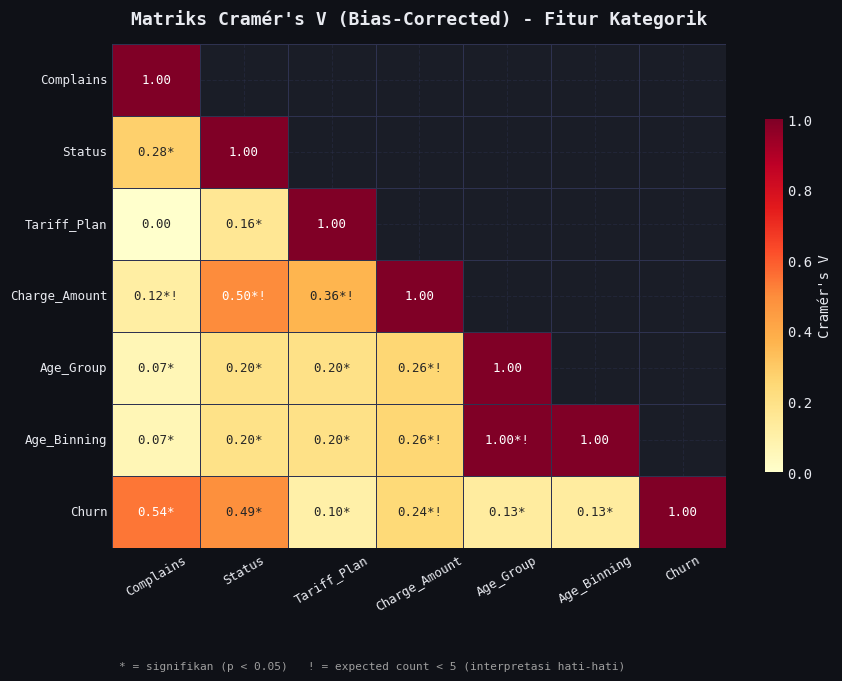

In [38]:
# ══════════════════════════════════════════════════════
# BAGIAN B: Matriks Cramér's V antar semua fitur kategorik
# ══════════════════════════════════════════════════════

ALL_KAT = FITUR_KAT + [TARGET]
ALL_KAT = [c for c in ALL_KAT if c in df.columns]

n = len(ALL_KAT)
matrix_v = pd.DataFrame(np.zeros((n, n)), index=ALL_KAT, columns=ALL_KAT)
matrix_p = pd.DataFrame(np.ones((n, n)),  index=ALL_KAT, columns=ALL_KAT)
matrix_reliabel = pd.DataFrame(np.ones((n, n), dtype=bool), index=ALL_KAT, columns=ALL_KAT)

for i, col_a in enumerate(ALL_KAT):
    for j, col_b in enumerate(ALL_KAT):
        if i == j:
            matrix_v.iloc[i, j] = 1.0
            matrix_p.iloc[i, j] = 0.0
        elif i < j:
            v, p, reliabel = cramers_v(df[col_a], df[col_b])
            matrix_v.iloc[i, j] = v
            matrix_v.iloc[j, i] = v
            matrix_p.iloc[i, j] = p
            matrix_p.iloc[j, i] = p
            matrix_reliabel.iloc[i, j] = reliabel
            matrix_reliabel.iloc[j, i] = reliabel

# Heatmap Cramér's V
fig, ax = plt.subplots(figsize=(9, 7), facecolor=BG_COLOR)
mask = np.triu(np.ones_like(matrix_v, dtype=bool), k=1)

# Anotasi: nilai V + * jika signifikan + ! jika expected count < 5
annot = pd.DataFrame(index=ALL_KAT, columns=ALL_KAT, dtype=str)
for i in range(n):
    for j in range(n):
        v_val = matrix_v.iloc[i, j]
        p_val = matrix_p.iloc[i, j]
        rel   = matrix_reliabel.iloc[i, j]
        star  = '*' if p_val < 0.05 and i != j else ''
        warn  = '!' if not rel and i != j else ''
        annot.iloc[i, j] = f'{v_val:.2f}{star}{warn}'

sns.heatmap(
    matrix_v, mask=mask, annot=annot, fmt='', cmap='YlOrRd', ax=ax,
    vmin=0, vmax=1, linewidths=0.4, linecolor='#2e3250',
    annot_kws={'size': 9}, cbar_kws={'shrink': 0.7, 'label': "Cramér's V"},
)
ax.set_title("Matriks Cramér's V (Bias-Corrected) - Fitur Kategorik",
             fontsize=13, fontweight='bold', pad=14)
ax.tick_params(axis='x', rotation=30, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)
ax.annotate('* = signifikan (p < 0.05)   ! = expected count < 5 (interpretasi hati-hati)',
            xy=(0.01, -0.24), xycoords='axes fraction', fontsize=8, color='#9e9e9e')
plt.tight_layout()
plt.show()

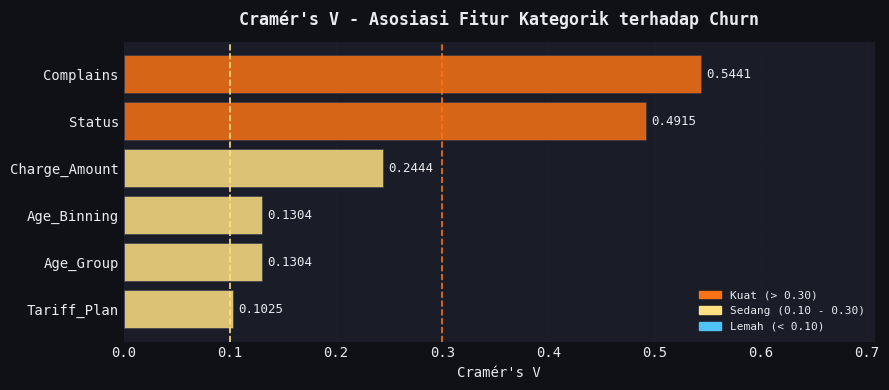

In [39]:
# ══════════════════════════════════════════════════════
# BAGIAN C: Bar Chart Cramér's V vs Churn
# (tidak berubah, tetap sama seperti sebelumnya)
# ══════════════════════════════════════════════════════

df_plot = cv_df.sort_values('Cramér V', ascending=True)
colors  = ['#f97316' if v >= 0.30 else
           '#ffe082' if v >= 0.10 else
           '#4fc3f7' for v in df_plot['Cramér V']]

fig, ax = plt.subplots(figsize=(9, max(4, len(df_plot) * 0.6)), facecolor=BG_COLOR)
bars = ax.barh(df_plot['Fitur'], df_plot['Cramér V'],
               color=colors, edgecolor='#2e3250', linewidth=0.5, alpha=0.85)

for bar, val, sig in zip(bars, df_plot['Cramér V'], df_plot['Signifikan']):
    label = f'{val:.4f}' + ('' if sig == 'Ya' else ' (tdk sig)')
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            label, va='center', ha='left', fontsize=9, color=TEXT_COLOR)

ax.axvline(0.10, color='#ffe082', linestyle='--', linewidth=1.2, label='Threshold Sedang (0.10)')
ax.axvline(0.30, color='#f97316', linestyle='--', linewidth=1.2, label='Threshold Kuat (0.30)')
ax.set_xlabel("Cramér's V", fontsize=10)
ax.set_title("Cramér's V - Asosiasi Fitur Kategorik terhadap Churn",
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlim(0, max(df_plot['Cramér V'].max() * 1.3, 0.5))
ax.grid(True, axis='x', linestyle='--', alpha=0.15, color=GRID_COLOR)
ax.grid(False, axis='y')

legend_patches = [
    mpatches.Patch(color='#f97316', label='Kuat (> 0.30)'),
    mpatches.Patch(color='#ffe082', label='Sedang (0.10 - 0.30)'),
    mpatches.Patch(color='#4fc3f7', label='Lemah (< 0.10)'),
]
ax.legend(handles=legend_patches, fontsize=8, framealpha=0.15, loc='lower right')
plt.tight_layout()
plt.show()

In [40]:
# ══════════════════════════════════════════════════════
# BAGIAN D: Ringkasan dan Rekomendasi (dengan cek signifikansi konsisten)
# ══════════════════════════════════════════════════════

print('\n' + '=' * 65)
print("  RINGKASAN CRAMÉR'S V")
print('=' * 65)

kuat   = cv_df[cv_df['Cramér V'] >= 0.30]
sedang = cv_df[(cv_df['Cramér V'] >= 0.10) & (cv_df['Cramér V'] < 0.30)]
lemah  = cv_df[cv_df['Cramér V'] < 0.10]

def print_grup(nama, subset, label_arah):
    if len(subset) > 0:
        print(f'\n  Asosiasi {nama} - {label_arah}:')
        for _, r in subset.iterrows():
            sig_note = '' if r['Signifikan'] == 'Ya' else ' (TIDAK SIGNIFIKAN - jangan jadikan dasar keputusan)'
            rel_note = '' if r['Reliabel'] else ' [!! expected count < 5, interpretasi tidak reliabel]'
            print(f'    {r["Fitur"]:<25} V = {r["Cramér V"]:.4f}{sig_note}{rel_note}')

print_grup('KUAT (V >= 0.30)', kuat, 'Keputusan fitur saat modeling')
print_grup('SEDANG (0.10 <= V < 0.30)', sedang, 'Keputusan fitur saat modeling')
print_grup('LEMAH (V < 0.10)', lemah, 'Kandidat DROP')

# Cek redundansi antar fitur kategorik
print('\n  Pasangan Fitur Kategorik Redundan (V >= 0.50):')
found = False
for i, col_a in enumerate(ALL_KAT[:-1]):
    for col_b in ALL_KAT[i+1:]:
        if col_b == TARGET:
            continue
        v_val = matrix_v.loc[col_a, col_b]
        rel   = matrix_reliabel.loc[col_a, col_b]
        if v_val >= 0.50:
            rel_note = '' if rel else '  [!! expected count < 5]'
            print(f'    {col_a} x {col_b} -> V = {v_val:.4f}  REDUNDAN{rel_note}')
            found = True
if not found:
    print('    Tidak ada pasangan dengan V >= 0.50')


  RINGKASAN CRAMÉR'S V

  Asosiasi KUAT (V >= 0.30) - Keputusan fitur saat modeling:
    Complains                 V = 0.5441
    Status                    V = 0.4915

  Asosiasi SEDANG (0.10 <= V < 0.30) - Keputusan fitur saat modeling:
    Charge_Amount             V = 0.2444 [!! expected count < 5, interpretasi tidak reliabel]
    Age_Group                 V = 0.1304
    Age_Binning               V = 0.1304
    Tariff_Plan               V = 0.1025

  Pasangan Fitur Kategorik Redundan (V >= 0.50):
    Status x Charge_Amount -> V = 0.5022  REDUNDAN  [!! expected count < 5]
    Age_Group x Age_Binning -> V = 1.0000  REDUNDAN  [!! expected count < 5]


## **Metode: Mutual Information (MI)**

In [41]:
# Pisahkan fitur dan target
X = df.drop(columns=['Churn'])
y = df['Churn']

# Tandai kolom mana yang diskrit/kategorikal (bukan besaran kontinu)
# Konsisten dengan klasifikasi fitur yang sudah dipakai di seluruh notebook ini
FITUR_KATEGORIKAL = [
    'Complains',
    'Tariff_Plan',
    'Status',
    'Age_Group',
    'Age_Binning',
    'Charge_Amount',
]

# Buat mask boolean sesuai urutan kolom di X
discrete_mask = [col in FITUR_KATEGORIKAL for col in X.columns]

# Hitung MI dengan discrete_features eksplisit pada 10 seed, karena estimatornya memakai noise acak
MI_SEEDS = [SEED + i for i in range(10)]
mi_runs = pd.DataFrame([
    mutual_info_classif(X, y, discrete_features=discrete_mask, random_state=seed)
    for seed in MI_SEEDS
], columns=X.columns)

# Buat dataframe hasil
mi_df = pd.DataFrame({
    'Fitur': X.columns,
    'MI_Score': mi_runs.mean().to_numpy(),
    'MI_Min': mi_runs.min().to_numpy(),
    'MI_Max': mi_runs.max().to_numpy(),
}).sort_values('MI_Score', ascending=False).reset_index(drop=True)

print("Mutual Information per Fitur (rata-rata, minimum, maksimum dari 10 seed):")
print(mi_df.round(4).to_string(index=False))

Mutual Information per Fitur (rata-rata, minimum, maksimum dari 10 seed):
                  Fitur  MI_Score  MI_Min  MI_Max
         Seconds_of_Use    0.1156  0.1103  0.1192
                 Status    0.1040  0.1040  0.1040
              Complains    0.1023  0.1023  0.1023
       Frequency_of_use    0.0894  0.0822  0.0949
         Customer_Value    0.0868  0.0829  0.0892
       Frequency_of_SMS    0.0523  0.0432  0.0687
Distinct_Called_Numbers    0.0497  0.0414  0.0601
          Charge_Amount    0.0371  0.0371  0.0371
    Subscription_Length    0.0224  0.0150  0.0306
            Age_Binning    0.0146  0.0146  0.0146
              Age_Group    0.0146  0.0146  0.0146
            Tariff_Plan    0.0079  0.0079  0.0079
           Call_Failure    0.0015  0.0000  0.0084


> \* Mutual Information (MI) dihitung dengan `discrete_features` eksplisit untuk fitur kategorikal dan ordinal, lalu dirata-ratakan dari 10 seed. Fitur dengan rentang yang tumpang tindih tidak boleh dibaca urutannya.

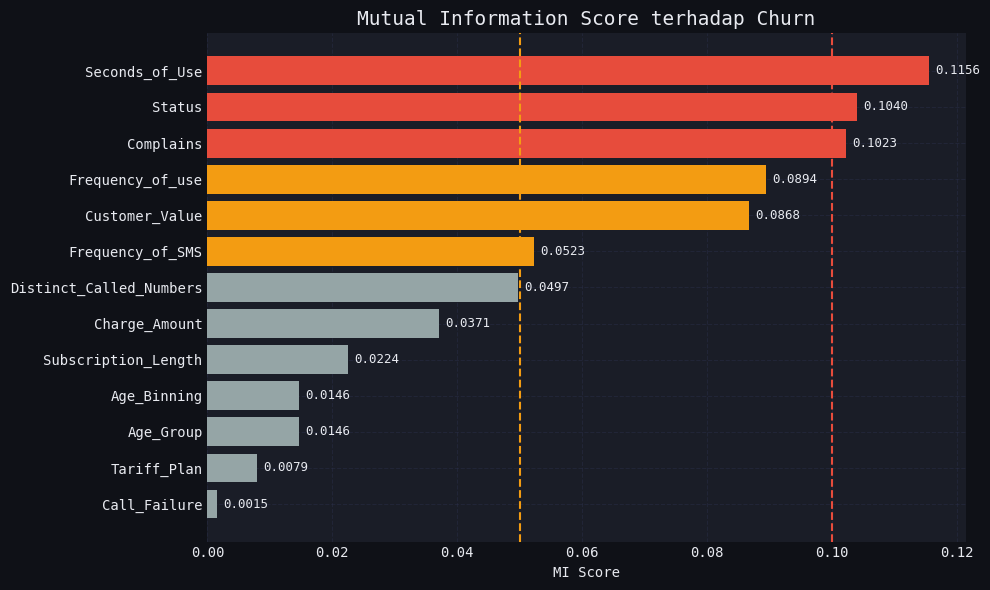

In [42]:
colors = ['#e74c3c' if v >= 0.1 else '#f39c12' if v >= 0.05 else '#95a5a6'
          for v in mi_df['MI_Score']]

plt.figure(figsize=(10, 6))
bars = plt.barh(mi_df['Fitur'], mi_df['MI_Score'], color=colors)

# Garis batas
plt.axvline(x=0.05, color='#f39c12', linestyle='--', linewidth=1.5, label='Batas Sedang (0.05)')
plt.axvline(x=0.10, color='#e74c3c', linestyle='--', linewidth=1.5, label='Batas Tinggi (0.10)')

# Nilai di ujung bar
for bar, val in zip(bars, mi_df['MI_Score']):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)

plt.xlabel('MI Score')
plt.title('Mutual Information Score terhadap Churn', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [43]:
# Gabungkan MI dengan korelasi terhadap Churn
corr_churn = df.corr(method='spearman')['Churn'].drop('Churn').abs().reset_index()
corr_churn.columns = ['Fitur', 'Korelasi_Churn']

comparison = mi_df[['Fitur', 'MI_Score']].merge(corr_churn, on='Fitur')
comparison = comparison.sort_values('MI_Score', ascending=False)

print("Perbandingan MI Score vs Korelasi terhadap Churn:")
print(comparison.to_string(index=False))

Perbandingan MI Score vs Korelasi terhadap Churn:
                  Fitur  MI_Score  Korelasi_Churn
         Seconds_of_Use  0.115627        0.360390
                 Status  0.104020        0.492867
              Complains  0.102323        0.546055
       Frequency_of_use  0.089384        0.335867
         Customer_Value  0.086773        0.353766
       Frequency_of_SMS  0.052308        0.214806
Distinct_Called_Numbers  0.049702        0.290830
          Charge_Amount  0.037092        0.247834
    Subscription_Length  0.022443        0.033052
            Age_Binning  0.014585        0.004854
              Age_Group  0.014585        0.004854
            Tariff_Plan  0.007919        0.106000
           Call_Failure  0.001486        0.014686


# C. Validasi Multikolinearitas Lanjutan

In [44]:
def cek_korelasi_tinggi(df, threshold=0.80):
    corr = df.drop(columns=['Churn']).corr(method= 'spearman').abs()
    pasangan = []
    cols = corr.columns.tolist()

    for i in range(len(cols)):
        for j in range(i+1, len(cols)):
            if corr.iloc[i, j] >= threshold:
                pasangan.append({
                    'Fitur A': cols[i],
                    'Fitur B': cols[j],
                    'Korelasi': round(corr.iloc[i, j], 3)
                })

    return pd.DataFrame(pasangan).sort_values('Korelasi', ascending=False)

pasangan_tinggi = cek_korelasi_tinggi(df, threshold=0.50)
print("Pasangan fitur dengan korelasi > 0.50:")
display(pasangan_tinggi)

Pasangan fitur dengan korelasi > 0.50:


,Fitur A,Fitur B,Korelasi
12,Age_Group,Age_Binning,1.000
3,Seconds_of_Use,Frequency_of_use,0.934
7,Frequency_of_use,Distinct_Called_Numbers,0.816
10,Frequency_of_SMS,Customer_Value,0.776
4,Seconds_of_Use,Distinct_Called_Numbers,0.752
6,Seconds_of_Use,Customer_Value,0.702
9,Frequency_of_use,Customer_Value,0.660
5,Seconds_of_Use,Status,0.585
0,Call_Failure,Charge_Amount,0.565
11,Distinct_Called_Numbers,Customer_Value,0.545


## VIF (Variance Inflation Factor)

In [45]:
# Pisahkan fitur (tanpa target Churn)
X = df.drop(columns=['Churn'])

# Pastikan semua kolom numerik
X = X.select_dtypes(include='number')

In [46]:
# 1. Tambahkan konstanta ke dalam dataframe X
X_vif = add_constant(X)

vif_data = pd.DataFrame()
# 2. Ambil nama kolom dari X_vif (akan ada tambahan kolom 'const')
vif_data['Fitur'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i)
                   for i in range(X_vif.shape[1])]

# Urutkan dan buang baris 'const' karena kita tidak butuh nilai VIF untuk konstanta
vif_data = vif_data[vif_data['Fitur'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)

# Tambahkan label status (Fungsi Anda sudah benar)
def vif_status(v):
    if v > 10: return '🔴 Tinggi - Evaluasi fitur sebelum dihapus'
    elif v > 5: return '⚠️ Sedang - Perlu dipertimbangkan'
    else: return '✅ Aman'

vif_data['Status'] = vif_data['VIF'].apply(vif_status)
display(vif_data)

,Fitur,VIF,Status
0,Customer_Value,53.203847,🔴 Tinggi - Evaluasi fitur sebelum dihapus
1,Frequency_of_SMS,41.569974,🔴 Tinggi - Evaluasi fitur sebelum dihapus
2,Seconds_of_Use,22.107064,🔴 Tinggi - Evaluasi fitur sebelum dihapus
3,Frequency_of_use,18.365358,🔴 Tinggi - Evaluasi fitur sebelum dihapus
4,Age_Binning,14.939063,🔴 Tinggi - Evaluasi fitur sebelum dihapus
5,Age_Group,14.231633,🔴 Tinggi - Evaluasi fitur sebelum dihapus
6,Charge_Amount,3.228834,✅ Aman
7,Call_Failure,2.914572,✅ Aman
8,Distinct_Called_Numbers,2.436216,✅ Aman
9,Status,1.843859,✅ Aman


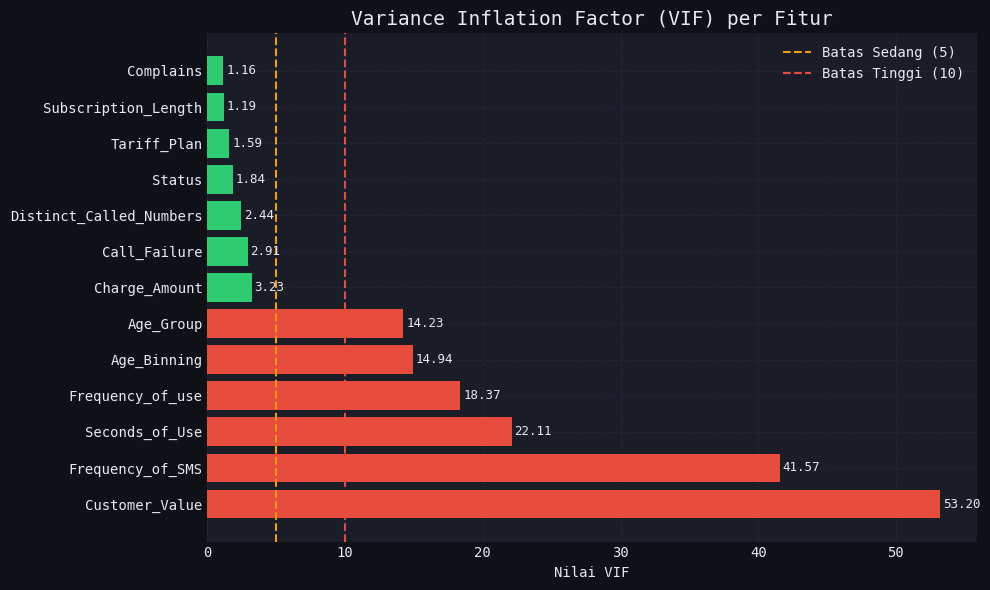

In [47]:
colors = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71'
          for v in vif_data['VIF']]

plt.figure(figsize=(10, 6))
bars = plt.barh(vif_data['Fitur'], vif_data['VIF'], color=colors)

# Garis batas
plt.axvline(x=5,  color='#f39c12', linestyle='--', linewidth=1.5, label='Batas Sedang (5)')
plt.axvline(x=10, color='#e74c3c', linestyle='--', linewidth=1.5, label='Batas Tinggi (10)')

# Tambahkan nilai di ujung bar
for bar, val in zip(bars, vif_data['VIF']):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=9)

plt.xlabel('Nilai VIF')
plt.title('Variance Inflation Factor (VIF) per Fitur', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

## Pemeriksaan Pendukung Hubungan Fitur

Menghitung angka yang dipakai di kesimpulan: jenis korelasi, asosiasi `Age_Group`, hubungan `Customer_Value` dengan fitur lain, VIF setelah kolom redundan dikeluarkan, dan gabungan `Complains` serta `Status`.

In [48]:
pair_rows = []
for col_a, col_b in [('Customer_Value', 'Frequency_of_SMS'), ('Seconds_of_Use', 'Frequency_of_use'), ('Age_Group', 'Age_Binning'),
                     ('Distinct_Called_Numbers', 'Seconds_of_Use'), ('Distinct_Called_Numbers', 'Frequency_of_use'),
                     ('Call_Failure', 'Frequency_of_use'), ('Frequency_of_SMS', 'Seconds_of_Use'), ('Frequency_of_SMS', 'Frequency_of_use')]:
    pair_rows.append({'Fitur A': col_a, 'Fitur B': col_b,
                      'Spearman': round(df[col_a].corr(df[col_b], method='spearman'), 3),
                      'Pearson': round(df[col_a].corr(df[col_b]), 3)})
print(pd.DataFrame(pair_rows).to_string(index=False))

age_table = pd.crosstab(df['Age_Group'], df[TARGET])
print(f"\nAge_Group vs Churn: chi-square p = {chi2_contingency(age_table)[1]:.2e}")
print('Churn rate per Age_Group:', df.groupby('Age_Group')[TARGET].mean().round(3).to_dict())

print('\nR-kuadrat regresi linier untuk Customer_Value:')
for columns in (['Frequency_of_SMS'], ['Seconds_of_Use', 'Frequency_of_use'], ['Seconds_of_Use', 'Frequency_of_SMS']):
    r_squared = LinearRegression().fit(df[columns], df['Customer_Value']).score(df[columns], df['Customer_Value'])
    print(f'  {columns}: {r_squared:.3f}')


def calculate_vif(features):
    with_constant = add_constant(features)
    return {col: round(variance_inflation_factor(with_constant.values, i), 2)
            for i, col in enumerate(with_constant.columns) if col != 'const'}


print('\nVIF tanpa Age_Binning:', calculate_vif(X.drop(columns=['Age_Binning'])))
print('VIF tanpa Age_Binning dan Customer_Value:', calculate_vif(X.drop(columns=['Age_Binning', 'Customer_Value'])))

print('\nComplains x Status x Churn:')
print(pd.crosstab([df['Complains'], df['Status']], df[TARGET], margins=True).to_string())

                Fitur A          Fitur B  Spearman  Pearson
         Customer_Value Frequency_of_SMS     0.776    0.923
         Seconds_of_Use Frequency_of_use     0.934    0.945
              Age_Group      Age_Binning     1.000    0.961
Distinct_Called_Numbers   Seconds_of_Use     0.752    0.672
Distinct_Called_Numbers Frequency_of_use     0.816    0.731
           Call_Failure Frequency_of_use     0.538    0.567
       Frequency_of_SMS   Seconds_of_Use     0.288    0.093
       Frequency_of_SMS Frequency_of_use     0.286    0.091

Age_Group vs Churn: chi-square p = 1.12e-10
Churn rate per Age_Group: {1: 0.0, 2: 0.17, 3: 0.164, 4: 0.202, 5: 0.013}

R-kuadrat regresi linier untuk Customer_Value:
  ['Frequency_of_SMS']: 0.852
  ['Seconds_of_Use', 'Frequency_of_use']: 0.168
  ['Seconds_of_Use', 'Frequency_of_SMS']: 0.957

VIF tanpa Age_Binning: {'Call_Failure': np.float64(2.91), 'Complains': np.float64(1.16), 'Subscription_Length': np.float64(1.19), 'Charge_Amount': np.float64(3.22), '

## Kesimpulan Uji Multikolinearitas (Korelasi & VIF)

Multikolinearitas diperiksa dengan korelasi antarpasangan dan *Variance Inflation Factor* (VIF). Angka korelasi menyebut jenisnya, karena Spearman dan Pearson bisa cukup berbeda pada data ini.

### 1. Pasangan dengan redundansi tinggi

*   **`Age_Group` dan `Age_Binning`:** Spearman 1,000 dan Pearson 0,961, karena jarak nilai `Age_Binning` tidak sama. Keduanya berpasangan satu-satu, jadi `Age_Binning` tidak masuk fitur model.
*   **`Seconds_of_Use` dan `Frequency_of_use`:** Spearman 0,934 dan Pearson 0,945, dengan VIF sekitar 22,1 dan 18,4.
*   **`Customer_Value` dan `Frequency_of_SMS`:** Spearman 0,776 dan Pearson 0,923, dengan VIF sekitar 53,2 dan 41,6.

### 2. `Customer_Value` sangat bisa dijelaskan oleh fitur lain

Regresi linier dari `Seconds_of_Use` dan `Frequency_of_SMS` menghasilkan R-kuadrat 0,957. Ini mendukung bahwa kolom ini sangat mungkin hasil hitungan dari fitur lain, tetapi rumusnya tidak dijelaskan dokumentasi UCI. Setelah `Age_Binning` dan `Customer_Value` dikeluarkan, VIF `Frequency_of_SMS` turun dari 39,68 menjadi 1,17.

### 3. Fitur dengan VIF di bawah 5

`Distinct_Called_Numbers` (2,44) dan `Call_Failure` (2,91) punya VIF rendah. VIF hanya mengukur redundansi linier, jadi `Distinct_Called_Numbers` tetap berkorelasi cukup tinggi dengan fitur penggunaan (Spearman 0,752 dan 0,816).

### Tindak lanjut

Keputusan fitur diambil saat modeling, berdasarkan pengujian dengan dan tanpa fitur terkait.

# **Kesimpulan Akhir Analisis Hubungan Fitur**

Analisis ini memakai Spearman dan Pearson (heatmap korelasi), Point-Biserial, Kruskal-Wallis, Cramér's V, VIF, dan *Mutual Information* (MI). Semua hubungan bersifat asosiatif, dan uji statistik mengasumsikan tiap baris independen, mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan.

### 1. Fitur dengan asosiasi terkuat terhadap Churn

| Fitur | Point-Biserial | Cramér's V | MI, rata-rata 10 seed (rentang) |
|---|---|---|---|
| `Complains` | +0,546 | 0,5441 | 0,102 (0,102–0,102) |
| `Status` | +0,493 | 0,4915 | 0,104 (0,104–0,104) |
| `Seconds_of_Use` | -0,296 | - | 0,116 (0,110–0,119) |
| `Frequency_of_use` | -0,299 | - | 0,089 (0,082–0,095) |
| `Customer_Value` | -0,287 | - | 0,087 (0,083–0,089) |

Rentang MI `Frequency_of_use` dan `Customer_Value` tumpang tindih, jadi urutan keduanya tidak dibaca.

### 2. Cara membaca `Status` dan `Complains`

Kedua fitur ini paling kuat berasosiasi dengan *churn*. Menurut dokumentasi UCI, semua fitur berasal dari 9 bulan pertama, jadi secara waktu mendahului label. Namun, cara `Status` ditentukan dan definisi churn tidak dijelaskan, jadi hubungan keduanya perlu dibaca hati-hati. Pada baris dengan komplain dan berstatus non-aktif, *churn rate* mencapai 89,3% (133 dari 149 baris). Saat modeling, hasil dibandingkan dengan dan tanpa kedua fitur untuk melihat seberapa besar skor bergantung padanya.

### 3. Redundansi fitur

*   `Age_Group` dan `Age_Binning` berpasangan satu-satu.
*   `Seconds_of_Use` dan `Frequency_of_use` sangat berkorelasi (Spearman 0,934).
*   `Customer_Value` sangat bisa dijelaskan oleh `Seconds_of_Use` dan `Frequency_of_SMS` (R-kuadrat 0,957).
*   `Status` x `Charge_Amount` punya Cramér's V 0,5022, tetapi ada sel tabel dengan *expected count* kurang dari 5, jadi ini hanya indikasi.

### 4. Fitur dengan asosiasi lemah atau pola khusus

*   **`Call_Failure`:** tidak terdeteksi oleh Point-Biserial dan Kruskal-Wallis, dengan MI 0,0015 (0,0000–0,0084). Ini asosiasi yang sangat lemah pada uji dua variabel, bukan bukti bahwa fitur ini tidak berguna saat digabung dengan fitur lain.
*   **`Age_Group`:** Point-Biserial dan Kruskal-Wallis tidak mendeteksi, tetapi chi-square signifikan (Cramér's V 0,1304). Pola *churn*-nya tidak searah: kelompok 1 dan 5 hampir tanpa *churn*, sedangkan kelompok 2 sampai 4 sekitar 16% sampai 20%.
*   **`Tariff_Plan`:** Point-Biserial -0,106 dan Cramér's V 0,1025, dengan jumlah baris antarkategori yang timpang (2.621 berbanding 229).
*   **`Charge_Amount`:** Cramér's V 0,2444, tetapi ditandai kurang reliabel karena level atasnya bersampel kecil.
*   **`Subscription_Length`:** Point-Biserial -0,038 (p = 0,0426), Kruskal-Wallis tidak signifikan (p = 0,0777), jadi asosiasinya sangat lemah dan tidak konsisten.

### 5. Kandidat fitur untuk diuji saat modeling

Tabel ini belum memutuskan fitur yang dibuang, kecuali `Age_Binning`.

| Fitur | Status | Yang diuji atau dicatat |
|---|---|---|
| `Age_Binning` | Tidak masuk fitur model | Berpasangan satu-satu dengan `Age_Group` |
| `Age_Group` | Dipakai | Dibaca sebagai kategori bertingkat karena polanya tidak searah |
| `Status`, `Complains` | Diuji | Bandingkan hasil dengan dan tanpa kedua fitur untuk melihat ketergantungan skor |
| `Seconds_of_Use`, `Frequency_of_use` | Diuji | Redundan, dan perlu dibandingkan dengan memakai salah satu |
| `Customer_Value`, `Frequency_of_SMS` | Diuji | `Customer_Value` sangat bisa dijelaskan oleh fitur lain |
| `Distinct_Called_Numbers` | Diuji | VIF rendah, tetapi berkorelasi dengan fitur penggunaan |
| `Call_Failure`, `Subscription_Length` | Diuji | Asosiasi dua variabel sangat lemah |
| `Charge_Amount`, `Tariff_Plan` | Diuji | Level atau kategorinya timpang |

# **Bagian 4: Segmentasi dan Pertanyaan Bisnis**

# A. Segmentasi Satu Fitur

In [49]:
# Analisis: Segmentasi Semua Fitur vs Churn


overall_churn = df[TARGET].mean()

COLOR_0 = "#4fc3f7"
COLOR_1 = "#ef9a9a"



# ══════════════════════════════════════════════════════
# LANGKAH 1: Bin semua fitur numerik kontinu
# ══════════════════════════════════════════════════════

df_seg = add_quartile_bins(df)

# ══════════════════════════════════════════════════════
# LANGKAH 2: Definisi semua segmen (kategorik + hasil bin)
# ══════════════════════════════════════════════════════

ALL_SEGMENTS = {
    # ── Kategorik asli
    'Complains':               CATEGORY_LABELS['Complains'],
    'Status':                  CATEGORY_LABELS['Status'],
    'Tariff_Plan':             CATEGORY_LABELS['Tariff_Plan'],
    'Age_Group':               CATEGORY_LABELS['Age_Group'],
    'Charge_Amount': {i: f'Level {i}' for i in range(11)},
    # ── Hasil binning numerik (pakai nama kolom _bin)
    'Seconds_of_Use_bin':          None,
    'Frequency_of_use_bin':        None,
    'Frequency_of_SMS_bin':        None,
    'Distinct_Called_Numbers_bin': None,
    'Customer_Value_bin':          None,
    'Call_Failure_bin':           None,
    'Subscription_Length_bin':    None,
}

# Filter hanya kolom yang ada
ALL_SEGMENTS = {k: v for k, v in ALL_SEGMENTS.items()
                if k in df_seg.columns}

# Kode kategori diganti label, dengan urutan tingkat tetap terjaga
for col, mapping in ALL_SEGMENTS.items():
    if mapping is not None:
        df_seg[col] = pd.Categorical(df_seg[col].map(mapping), categories=list(mapping.values()), ordered=True)

In [50]:
# ══════════════════════════════════════════════════════
# LANGKAH 3: Tabel Churn Rate semua segmen
# ══════════════════════════════════════════════════════

print('=' * 68)
print('  CHURN RATE PER SEGMEN — SEMUA FITUR')
print(f'  Rata-rata keseluruhan: {overall_churn*100:.1f}%')
print('=' * 68)

for col in ALL_SEGMENTS:
    grp = (df_seg.groupby(col, observed=True)[TARGET]
           .agg(['sum', 'count', 'mean'])
           .reset_index())
    grp.columns = ['Segmen', 'Churn', 'Total', 'Rate']
    grp['Rate%']     = (grp['Rate'] * 100).round(1)
    grp['vs Avg']    = ((grp['Rate'] - overall_churn) * 100).round(1)

    print(f'\n── {col.replace("_bin","").replace("_"," ")}')
    print(f'  {"Segmen":<22} {"Total":>7} {"Churn":>7} {"Rate":>7} {"vs Avg":>9}')
    print('  ' + '-' * 54)
    for _, row in grp.iterrows():
        arrow = '↑' if row['vs Avg'] > 0 else '↓'
        flag  = ' ⚠' if row['Rate%'] > overall_churn * 100 * 1.5 else ''
        print(f'  {str(row["Segmen"]):<22} {int(row["Total"]):>7} '
              f'{int(row["Churn"]):>7} {row["Rate%"]:>6.1f}% '
              f'{arrow}{abs(row["vs Avg"]):>5.1f}%{flag}')

  CHURN RATE PER SEGMEN — SEMUA FITUR
  Rata-rata keseluruhan: 15.6%

── Complains
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  Tanpa Komplain            2620     256    9.8% ↓  5.9%
  Komplain                   230     190   82.6% ↑ 67.0% ⚠

── Status
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  Aktif                     2166     121    5.6% ↓ 10.1%
  Non-aktif                  684     325   47.5% ↑ 31.9% ⚠

── Tariff Plan
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  Pay as you go             2621     440   16.8% ↑  1.1%
  Kontrak                    229       6    2.6% ↓ 13.0%

── Age Group
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  Usia 15                    112       0    0.0% ↓ 15.6%
  Usia 25

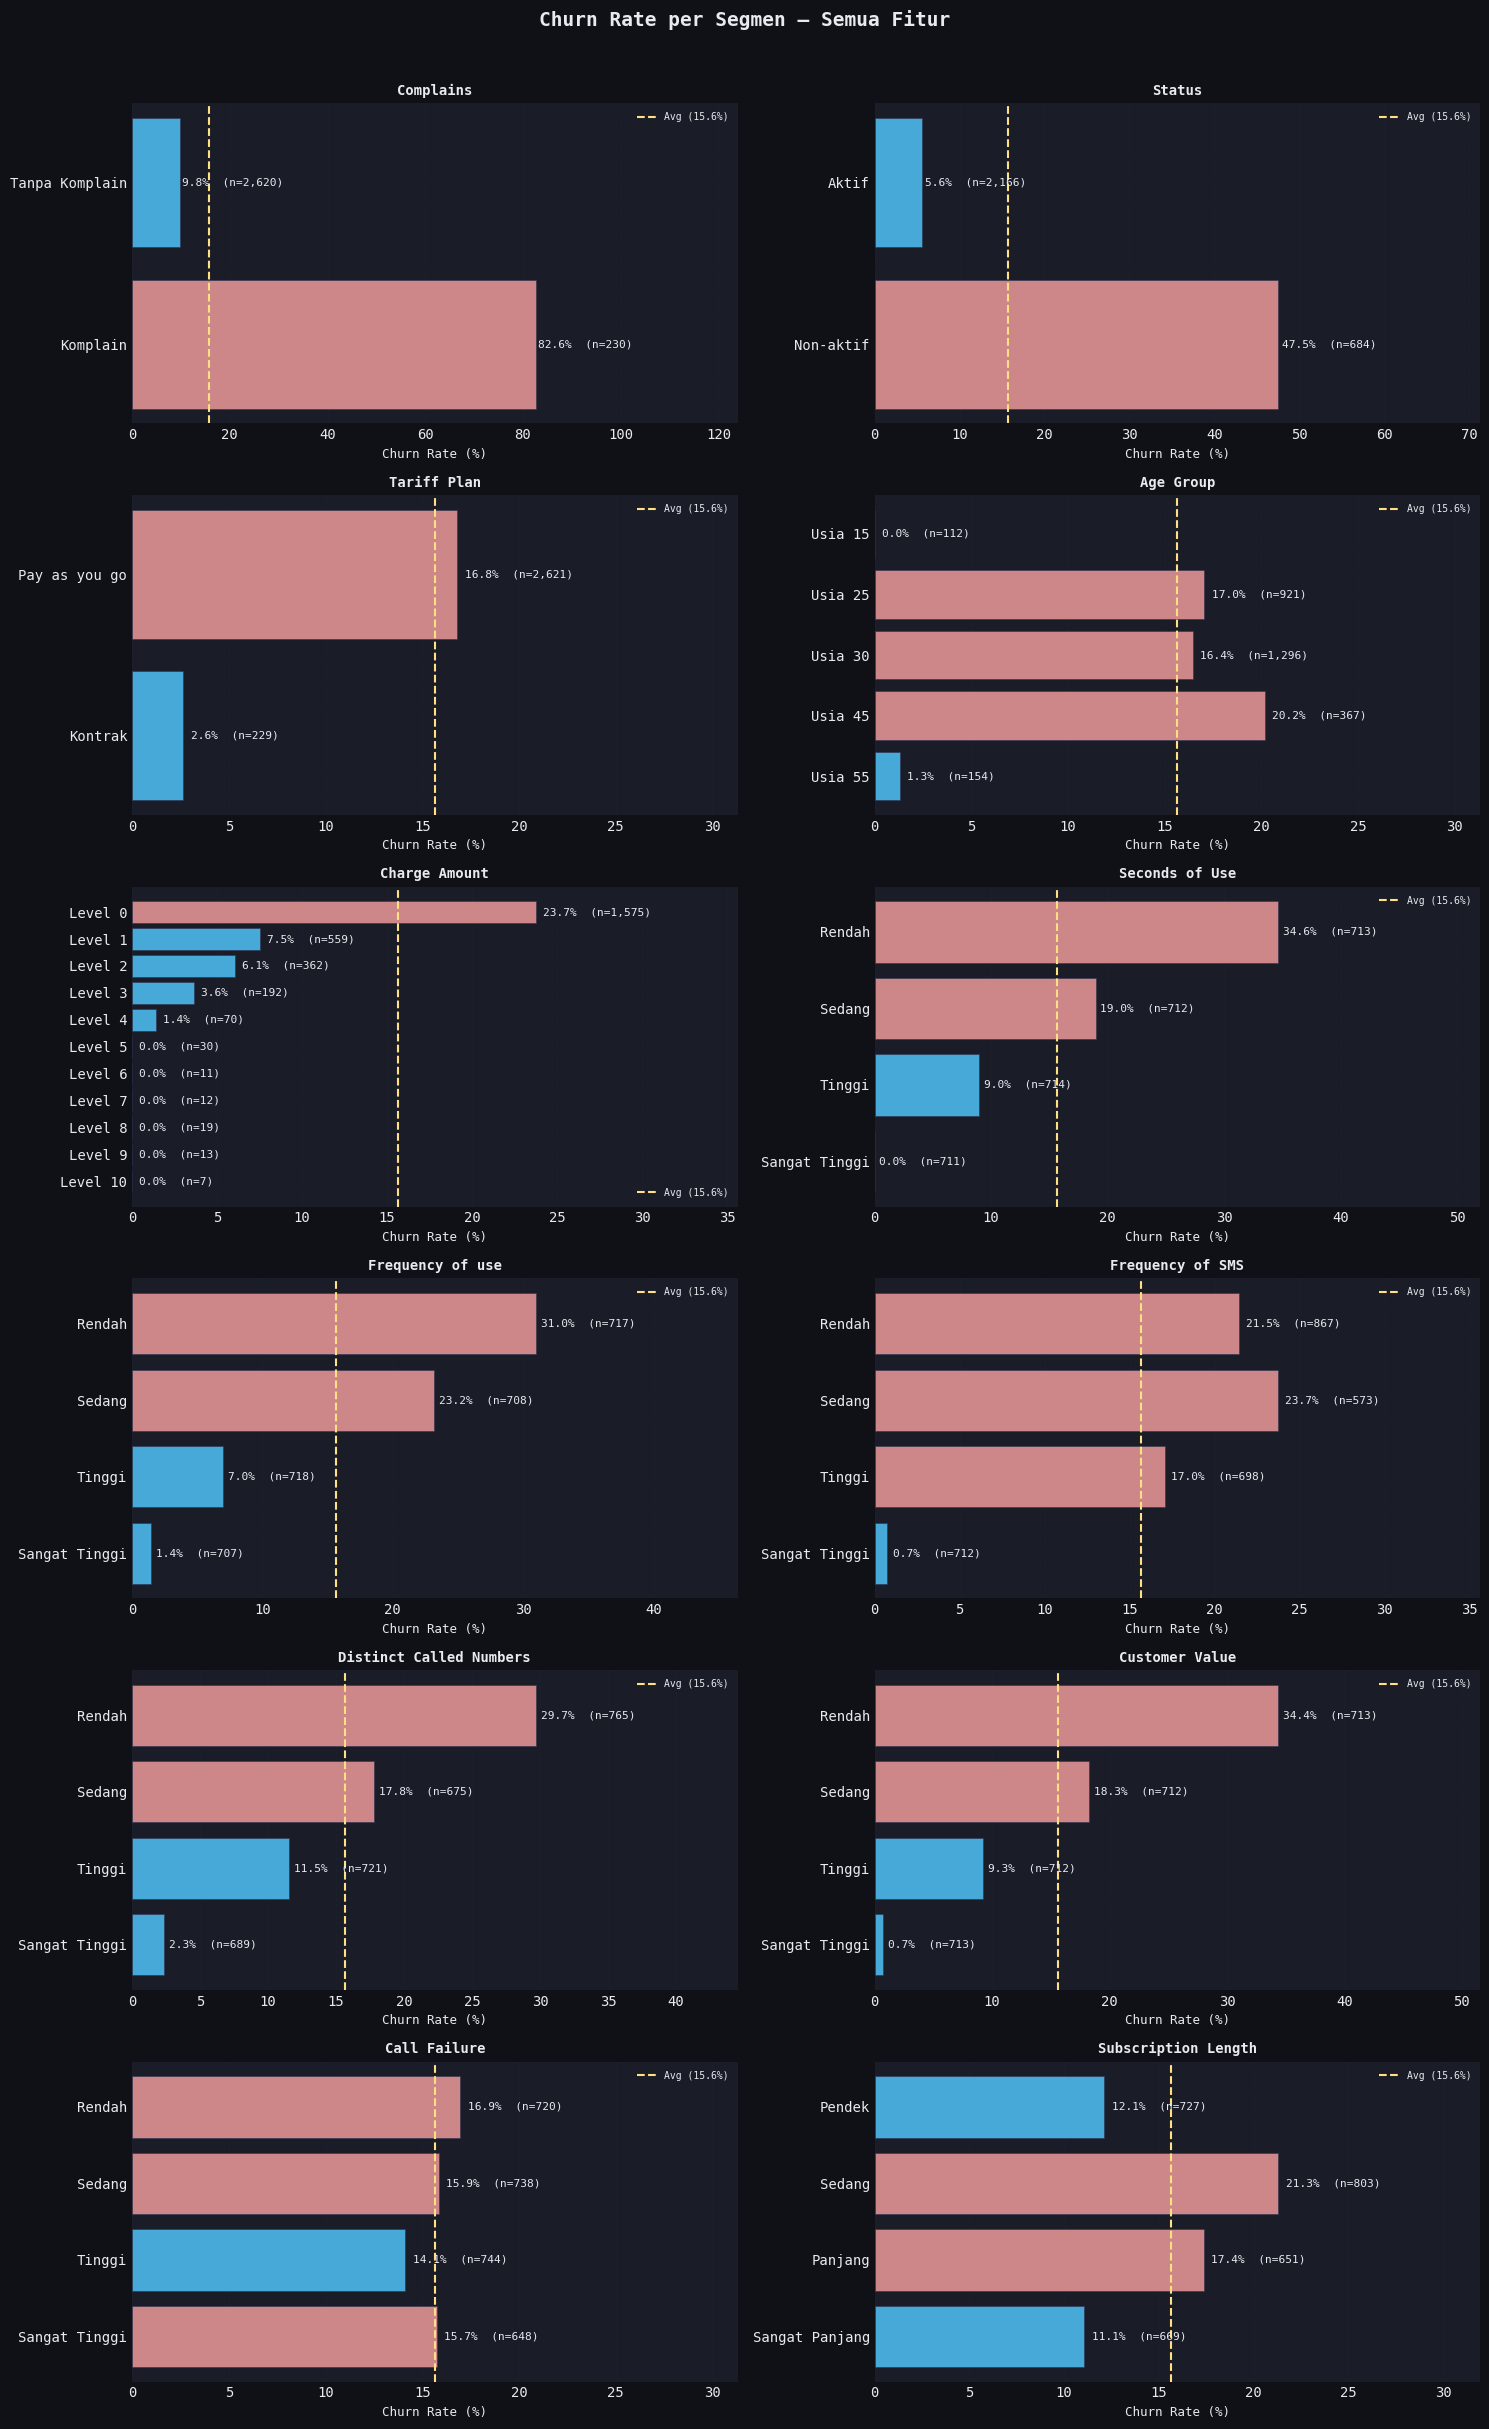

In [51]:
# ══════════════════════════════════════════════════════
# LANGKAH 4: Visualisasi Bar Chart semua segmen
# ══════════════════════════════════════════════════════

seg_list = list(ALL_SEGMENTS.keys())
n_cols   = 2
n_rows   = ceil(len(seg_list) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(15, n_rows * 4),
                          facecolor=BG_COLOR)
axes = axes.flatten()
fig.suptitle('Churn Rate per Segmen — Semua Fitur',
             fontsize=14, fontweight='bold', y=1.01)

for idx, col in enumerate(seg_list):
    ax = axes[idx]

    grp = (df_seg.groupby(col, observed=True)[TARGET]
           .agg(['sum', 'count', 'mean'])
           .reset_index())
    grp.columns = ['Segmen', 'Churn', 'Total', 'Rate']
    grp['Rate%'] = grp['Rate'] * 100

    bar_colors = [COLOR_1 if r > overall_churn * 100 else COLOR_0
                  for r in grp['Rate%']]

    bars = ax.barh(grp['Segmen'].astype(str), grp['Rate%'],
                   color=bar_colors, edgecolor='#2e3250',
                   linewidth=0.5, alpha=0.85)

    for bar, rate, total in zip(bars, grp['Rate%'], grp['Total']):
        ax.text(bar.get_width() + 0.4,
                bar.get_y() + bar.get_height() / 2,
                f'{rate:.1f}%  (n={int(total):,})',
                va='center', ha='left', fontsize=8, color=TEXT_COLOR)

    ax.axvline(overall_churn * 100, color='#ffe082',
               linestyle='--', linewidth=1.5,
               label=f'Avg ({overall_churn*100:.1f}%)')

    title = col.replace('_bin', '').replace('_', ' ')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('Churn Rate (%)', fontsize=9)
    ax.set_xlim(0, max(grp['Rate%'].max() * 1.5, overall_churn * 100 * 2))
    ax.grid(True, axis='x', linestyle='--', alpha=0.15, color=GRID_COLOR)
    ax.grid(False, axis='y')
    ax.invert_yaxis()   # tingkat terendah di atas
    ax.legend(fontsize=7, framealpha=0.15)

for idx in range(len(seg_list), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

In [52]:
# ══════════════════════════════════════════════════════
# LANGKAH 5: Ringkasan Segmen Berisiko Tinggi
# ══════════════════════════════════════════════════════

print('\n' + '=' * 68)
print('  SEGMEN BERISIKO TINGGI (Churn Rate > 1.5x rata-rata)')
print(f'  Threshold: {overall_churn*100:.1f}% x 1.5 = {overall_churn*100*1.5:.1f}%')
print('=' * 68)

high_risk_all = []

for col in ALL_SEGMENTS:
    grp = (df_seg.groupby(col, observed=True)[TARGET]
           .agg(['mean', 'count'])
           .reset_index())
    grp.columns = ['Segmen', 'Rate', 'Total']
    high = grp[grp['Rate'] >= overall_churn * 1.5]

    for _, row in high.iterrows():
        high_risk_all.append({
            'Fitur':    col.replace('_bin','').replace('_',' '),
            'Segmen':   str(row['Segmen']),
            'Rate':     round(row['Rate'] * 100, 1),
            'Total':    int(row['Total']),
            'Multiplier': round(row['Rate'] / overall_churn, 1),
        })

hr_df = pd.DataFrame(high_risk_all).sort_values('Rate', ascending=False)

print(f'\n{"Fitur":<28} {"Segmen":<22} {"Rate":>7} {"n":>6} {"vs Avg":>8}')
print('-' * 76)
for _, r in hr_df.iterrows():
    print(f'  {r["Fitur"]:<26} {r["Segmen"]:<22} '
          f'{r["Rate"]:>6.1f}%  {r["Total"]:>5,}  '
          f'{r["Multiplier"]:>5.1f}x')


  SEGMEN BERISIKO TINGGI (Churn Rate > 1.5x rata-rata)
  Threshold: 15.6% x 1.5 = 23.5%

Fitur                        Segmen                    Rate      n   vs Avg
----------------------------------------------------------------------------
  Complains                  Komplain                 82.6%    230    5.3x
  Status                     Non-aktif                47.5%    684    3.0x
  Seconds of Use             Rendah                   34.6%    713    2.2x
  Customer Value             Rendah                   34.4%    713    2.2x
  Frequency of use           Rendah                   31.0%    717    2.0x
  Distinct Called Numbers    Rendah                   29.7%    765    1.9x
  Charge Amount              Level 0                  23.7%  1,575    1.5x
  Frequency of SMS           Sedang                   23.7%    573    1.5x


## **Analisis Segmentasi**

Analisis segmentasi dilakukan terhadap seluruh fitur untuk mengidentifikasi
kelompok pelanggan mana yang memiliki risiko churn tertinggi. Fitur numerik
kontinu dibagi menjadi empat kuartil (Rendah, Sedang, Tinggi, Sangat Tinggi)
menggunakan quantile-based binning agar setiap kelompok memiliki jumlah
pelanggan yang proporsional. Rata-rata churn rate keseluruhan adalah 15,6%
dan digunakan sebagai garis pembanding di seluruh analisis.

---

### **Fitur Kategorik**

**`Complains`**

Ini adalah asosiasi terkuat pada segmentasi satu fitur. Baris yang
pernah melakukan komplain memiliki churn rate 82,6%, atau 5,3x lebih
tinggi dari rata-rata. Dari 230 pelanggan yang pernah komplain, 190 di
antaranya akhirnya churn. Sebaliknya, pelanggan yang tidak pernah komplain
hanya memiliki churn rate 9,8%. Selisihnya 72,8 poin persentase.

**`Status`**

Baris dengan Non-aktif memiliki churn rate 47,5%, atau 3,0x rata-rata, dengan total 684 baris. Aktif memiliki churn rate 5,6%. Dokumentasi UCI tidak menjelaskan cara `Status` ditentukan, jadi penyebab perbedaannya belum bisa disimpulkan.

**`Tariff_Plan`**

Pay as you go memiliki churn rate 16,8%, sedikit di atas rata-rata, sementara
Kontrak hanya 2,6%. Namun perlu diperhatikan bahwa Kontrak hanya memiliki
229 pelanggan (8% dari total) sehingga interpretasi harus dilakukan dengan
hati-hati karena ukuran sampelnya sangat kecil.

**`Age_Group`**

Polanya tidak searah. Kelompok 2 sampai 4 memiliki churn rate 16,4% sampai 20,2%, sedangkan kelompok 1 (0%, n=112) dan kelompok 5 (1,3%, n=154) hampir tanpa churn. Karena itu, korelasi linear atau peringkat yang kecil tidak berarti `Age_Group` tidak berasosiasi dengan churn. Jumlah baris kelompok 1 dan 5 lebih sedikit, jadi perlu dibaca hati-hati.

**`Charge_Amount`**

Semakin tinggi level, semakin rendah churn rate. Level 0 memiliki churn rate tertinggi, yaitu 23,7% dengan 1.575 baris, sedangkan Level 5 ke atas memiliki churn rate 0% dengan jumlah baris yang kecil. Arti Level 0 secara bisnis tidak dijelaskan dokumentasi UCI.

---

### **Fitur Numerik (Hasil Binning Kuartil)**

**`Seconds_of_Use` dan `Frequency_of_use`**

Keduanya menunjukkan pola yang sangat konsisten: semakin rendah penggunaan,
semakin tinggi risiko churn. Pelanggan dengan `Seconds_of_Use` Rendah memiliki
churn rate 34,6% dan `Frequency_of_use` Rendah 31,0%, sedangkan pelanggan
dengan penggunaan Sangat Tinggi masing-masing 0% dan 1,4%. Pola ini
menunjukkan asosiasi antara penggunaan yang rendah dan churn rate yang lebih tinggi.

**`Customer_Value`**

Pola yang identik dengan fitur usage. Segmen Rendah memiliki churn rate
34,4% sedangkan Sangat Tinggi hanya 0,7%. Pola ini searah dengan
fitur penggunaan lainnya.

**`Distinct_Called_Numbers`**

Pola serupa dengan fitur usage lainnya. Segmen Rendah memiliki churn rate
29,7% sedangkan Sangat Tinggi hanya 2,3%.

**`Frequency_of_SMS`**

Pola sedikit berbeda dibanding fitur usage lainnya. Segmen Sedang justru
memiliki churn rate tertinggi (23,7%), lebih tinggi dari segmen Rendah
(21,5%). Ini mengindikasikan hubungan yang tidak sepenuhnya linear antara
frekuensi SMS dan churn. Namun segmen Sangat Tinggi tetap memiliki churn
rate sangat rendah (0,7%), konsisten dengan pola fitur usage lainnya.

**`Subscription_Length`**

Polanya tidak searah. Segmen Sedang memiliki churn rate tertinggi (21,3%), sedangkan segmen Pendek 12,1% dan Sangat Panjang 11,1%. Menurut dokumentasi UCI satuannya bulan, dan pola ini tidak dipakai sebagai klaim tentang pelanggan baru.

**`Call_Failure`**

Churn rate hampir identik di semua segmen, berkisar antara 14,1% hingga
16,9%, tanpa pola yang bermakna. Pada perbandingan dua variabel ini, `Call_Failure` tidak menunjukkan
perbedaan yang berarti, dan keputusan fiturnya diambil saat modeling.

---

### **Ringkasan Segmen Berisiko Tinggi**

Delapan segmen teridentifikasi memiliki churn rate di atas 1,5x rata-rata:

| Segmen | Churn Rate | Multiplier |
|---|---|---|
| Complains = Komplain | 82,6% | 5,3x |
| Status = Non-aktif | 47,5% | 3,0x |
| `Seconds_of_Use` = Rendah | 34,6% | 2,2x |
| `Customer_Value` = Rendah | 34,4% | 2,2x |
| `Frequency_of_use` = Rendah | 31,0% | 2,0x |
| `Distinct_Called_Numbers` = Rendah | 29,7% | 1,9x |
| `Frequency_of_SMS` = Sedang | 23,7% | 1,5x |
| `Charge_Amount` = Level 0 | 23,7% | 1,5x |


# B. Segmentasi Dua Fitur

## Analisis Kombinasi Dua Fitur: Heatmap Churn Rate dan Ranking Segmen Ekstrem

Heatmap berikut menampilkan churn rate untuk seluruh kombinasi dua fitur (kategorik x kategorik, kategorik x numerik, dan numerik x numerik) tanpa filter statistik lanjutan. Sel dengan kurang dari 20 baris dikosongkan. Tujuannya sebagai eksplorasi visual awal untuk melihat pola secara menyeluruh. Kombinasi yang lolos saringan ukuran sampel dan stabilitas dibahas pada section berikutnya.

In [53]:
# Analisis: Multivariate Kombinasi Semua Fitur vs Churn

overall_churn = df[TARGET].mean()

COLOR_0      = "#4fc3f7"
COLOR_1      = "#ef9a9a"
CMAP_HEATMAP = "RdYlGn_r"



df_mv = add_segment_columns(df)

# Semua kolom yang akan dikombinasikan
ALL_COLS = [f'{c}_lbl' for c in CATEGORY_LABELS] + [f'{c}_bin' for c in BIN_COLUMNS]

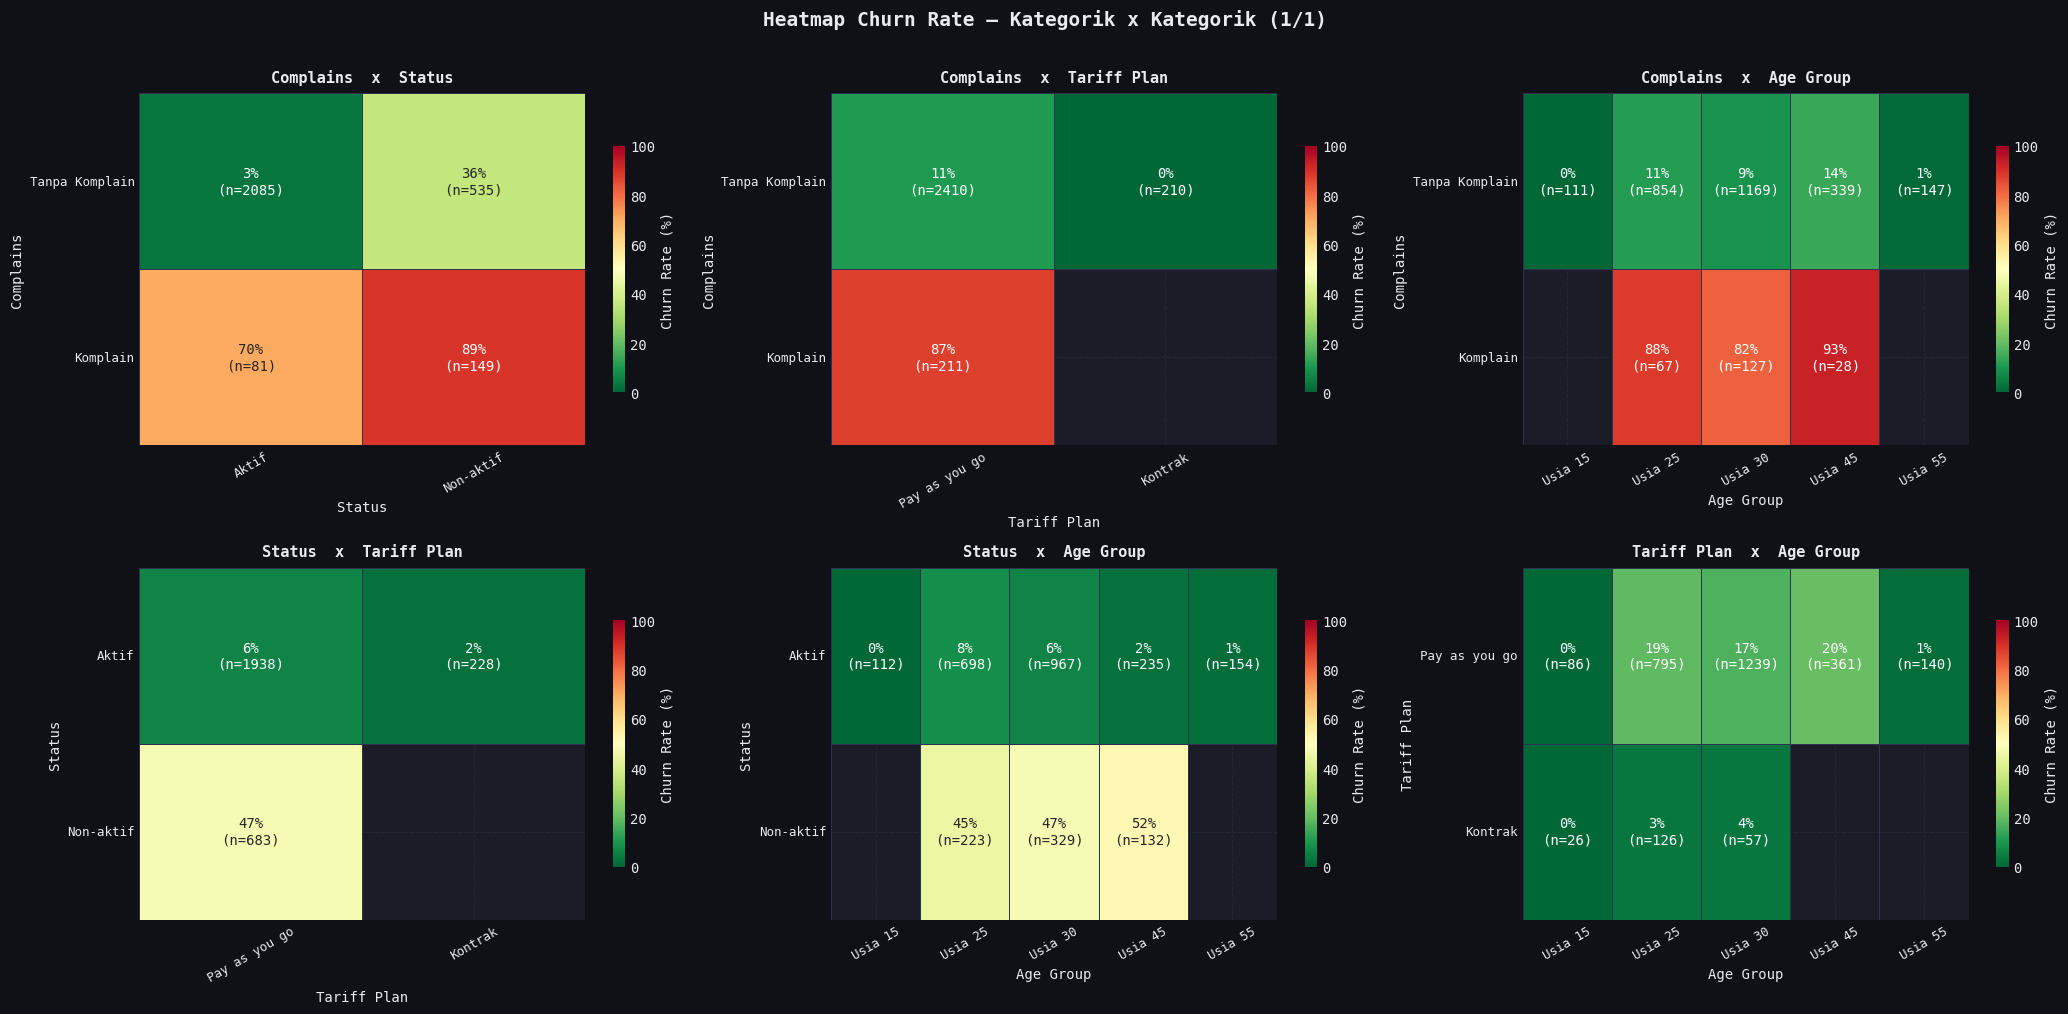

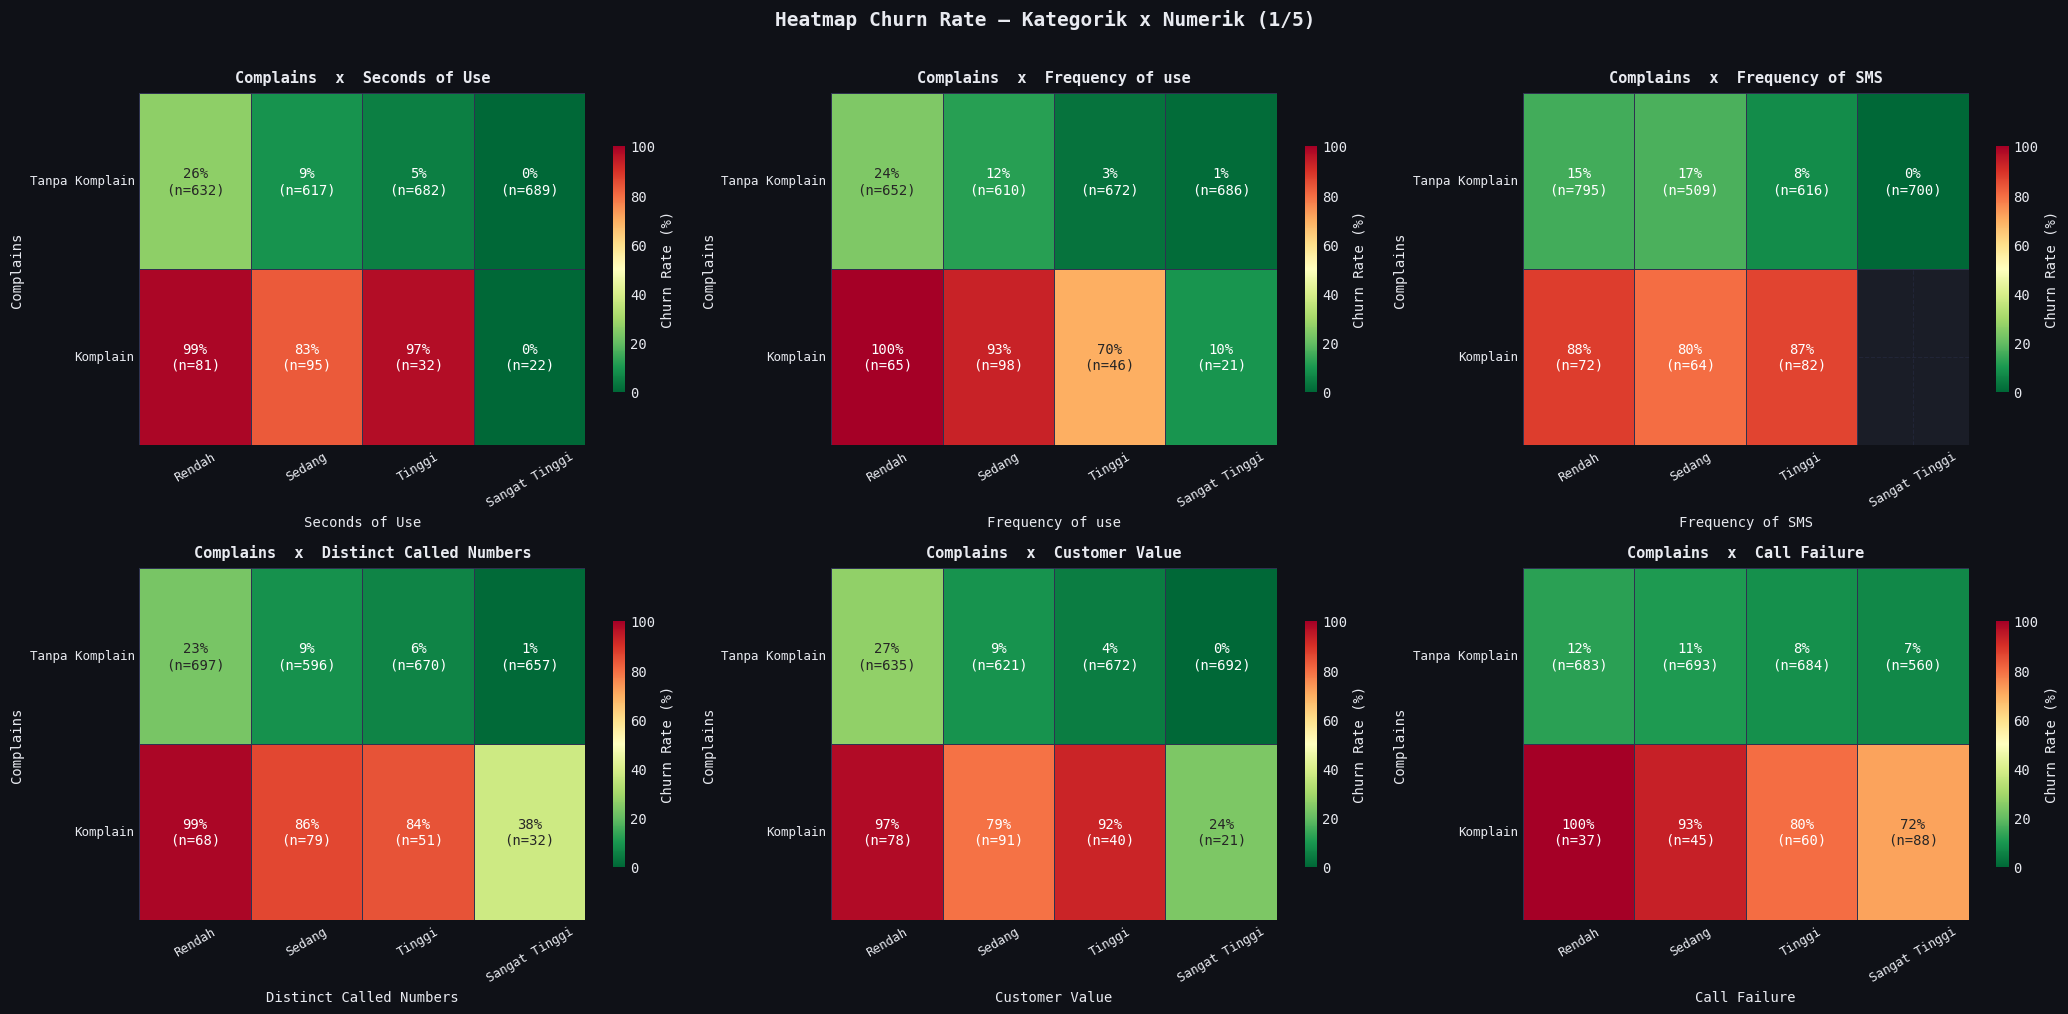

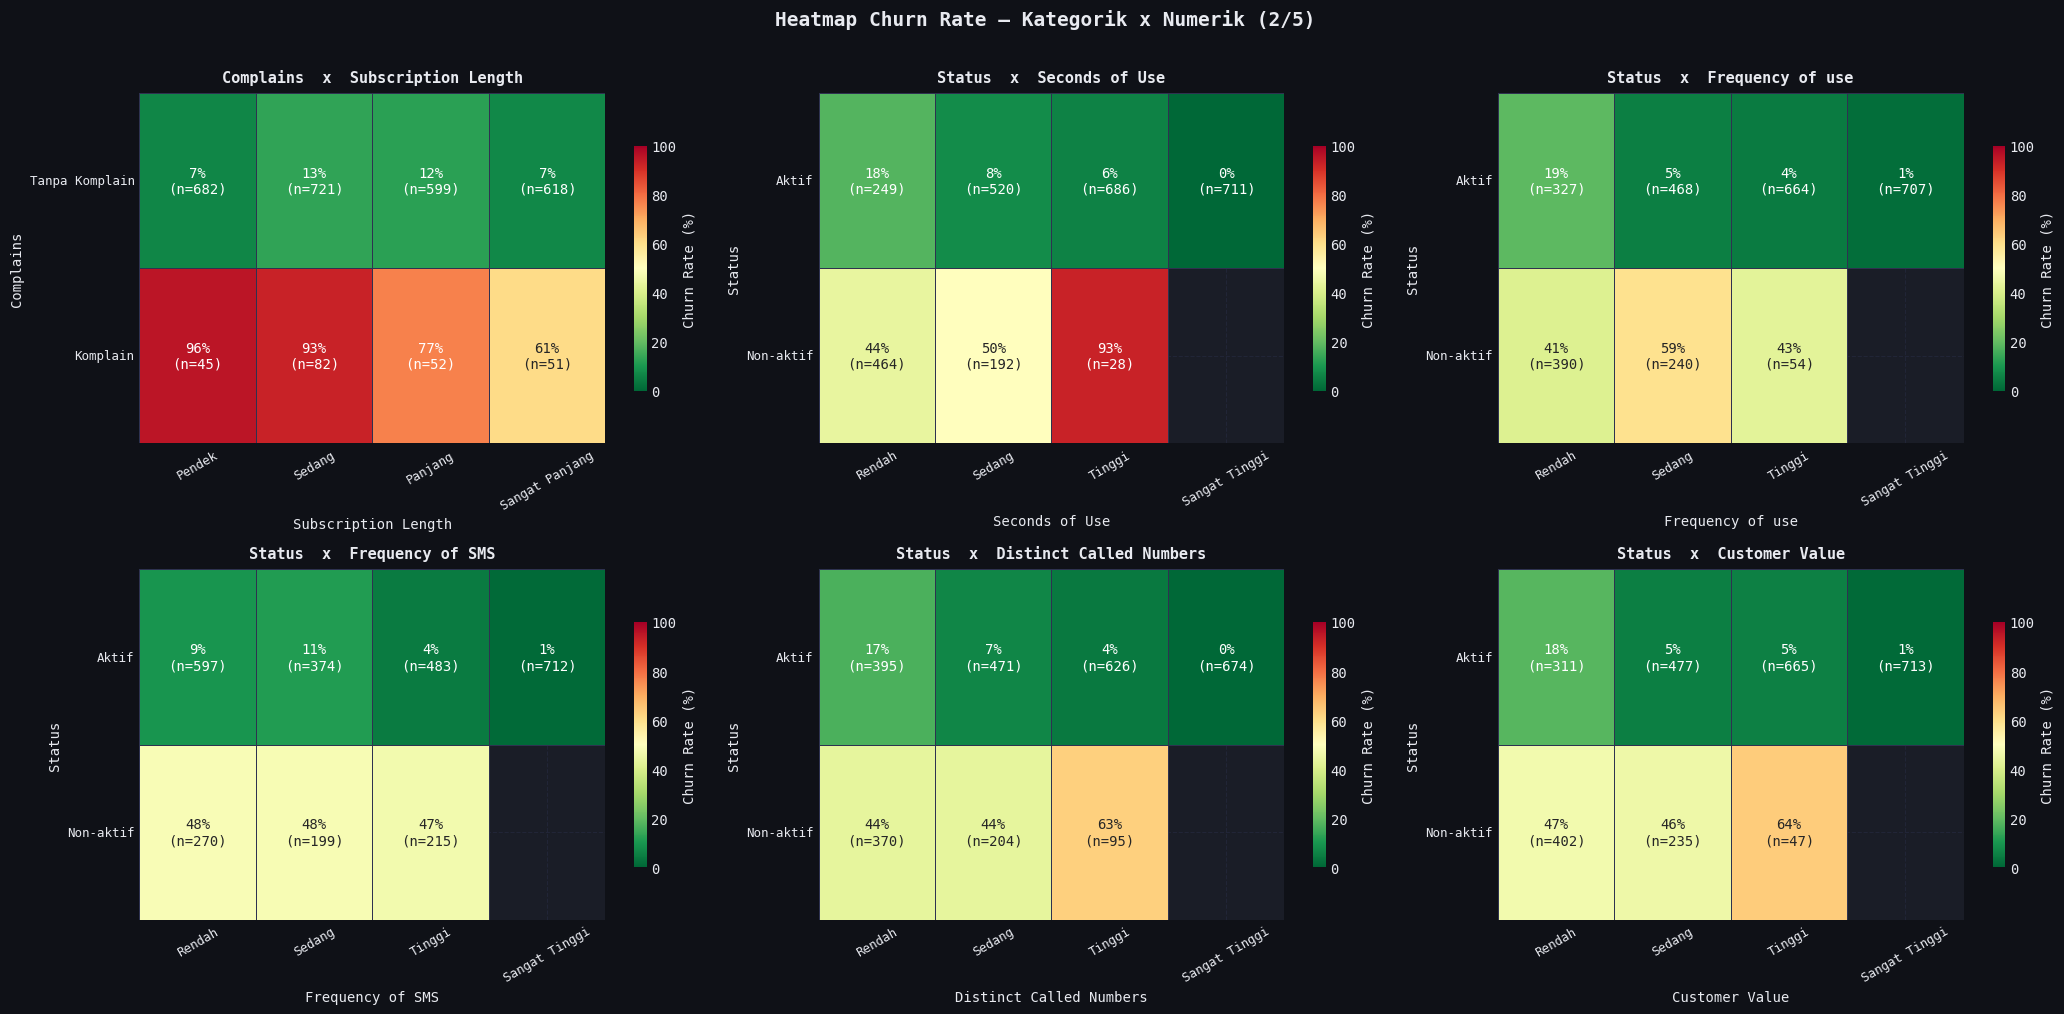

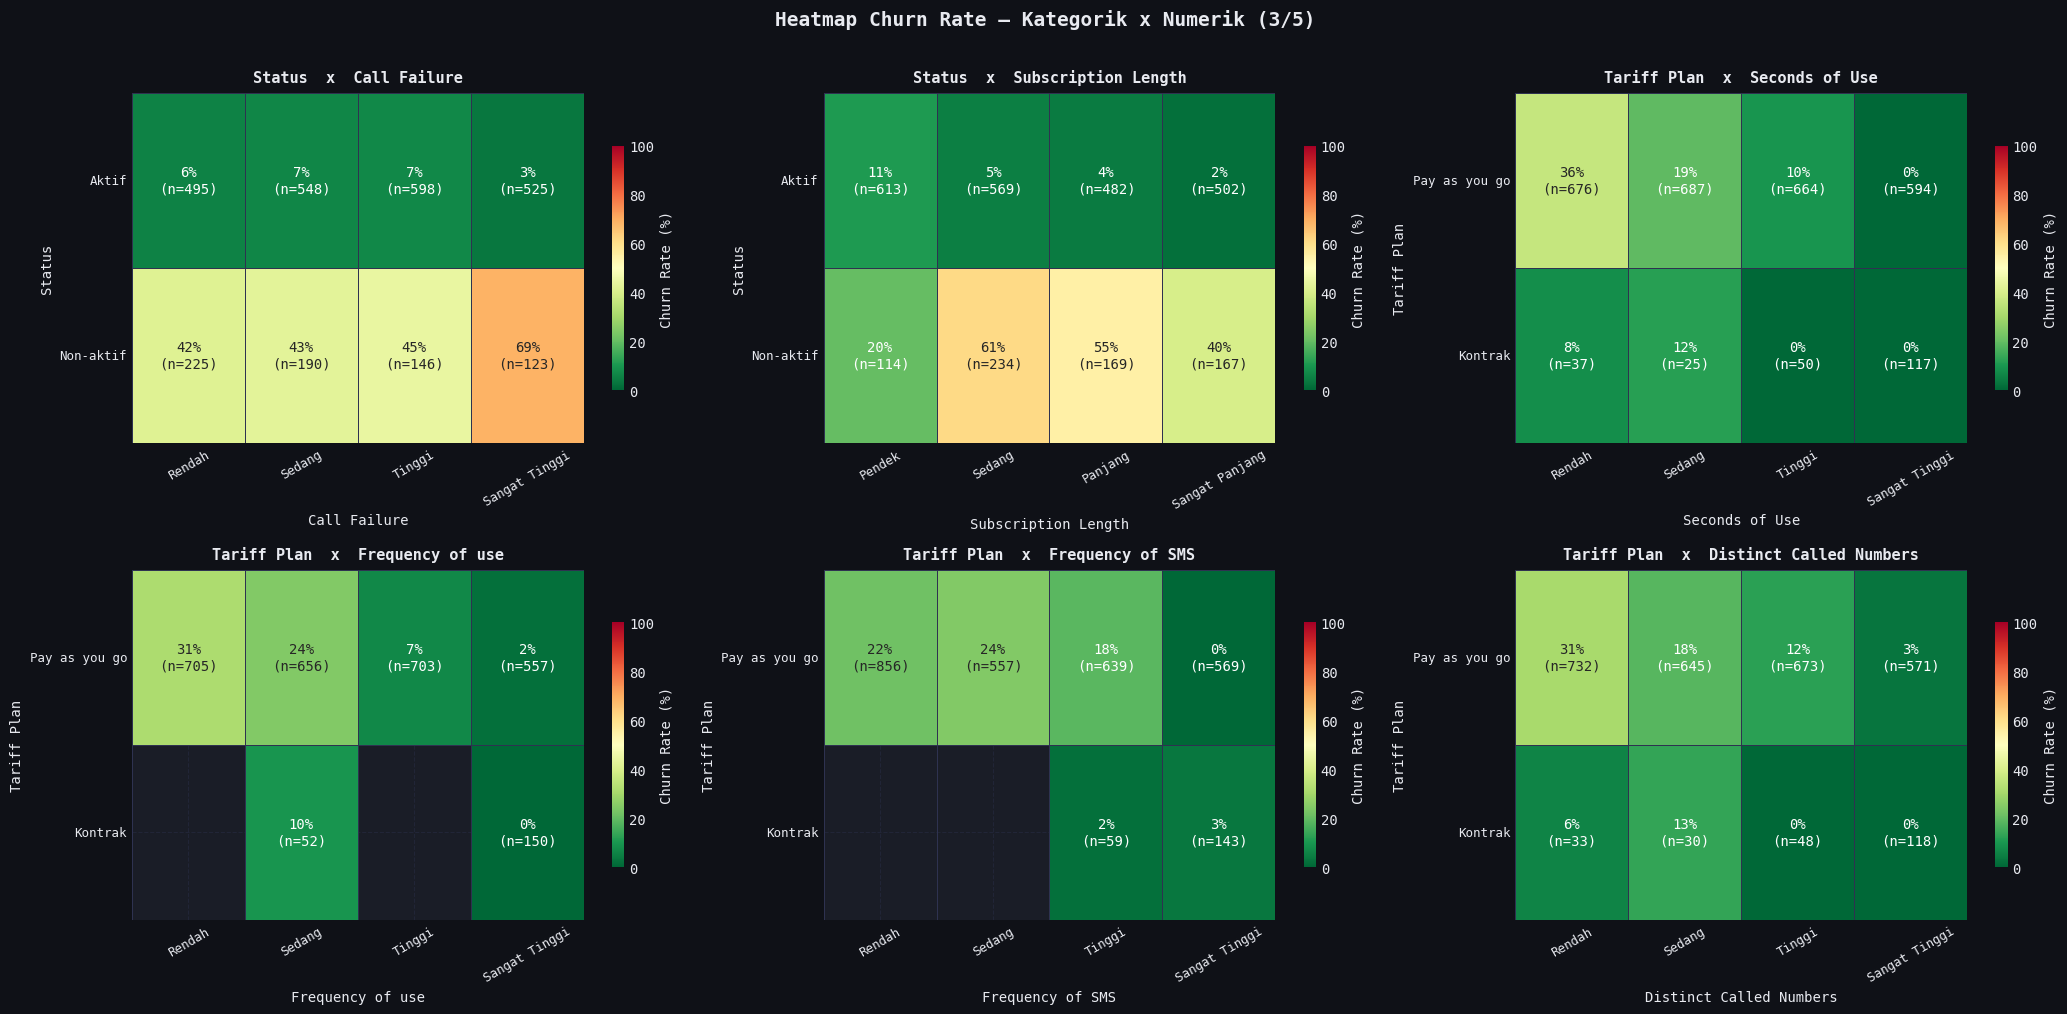

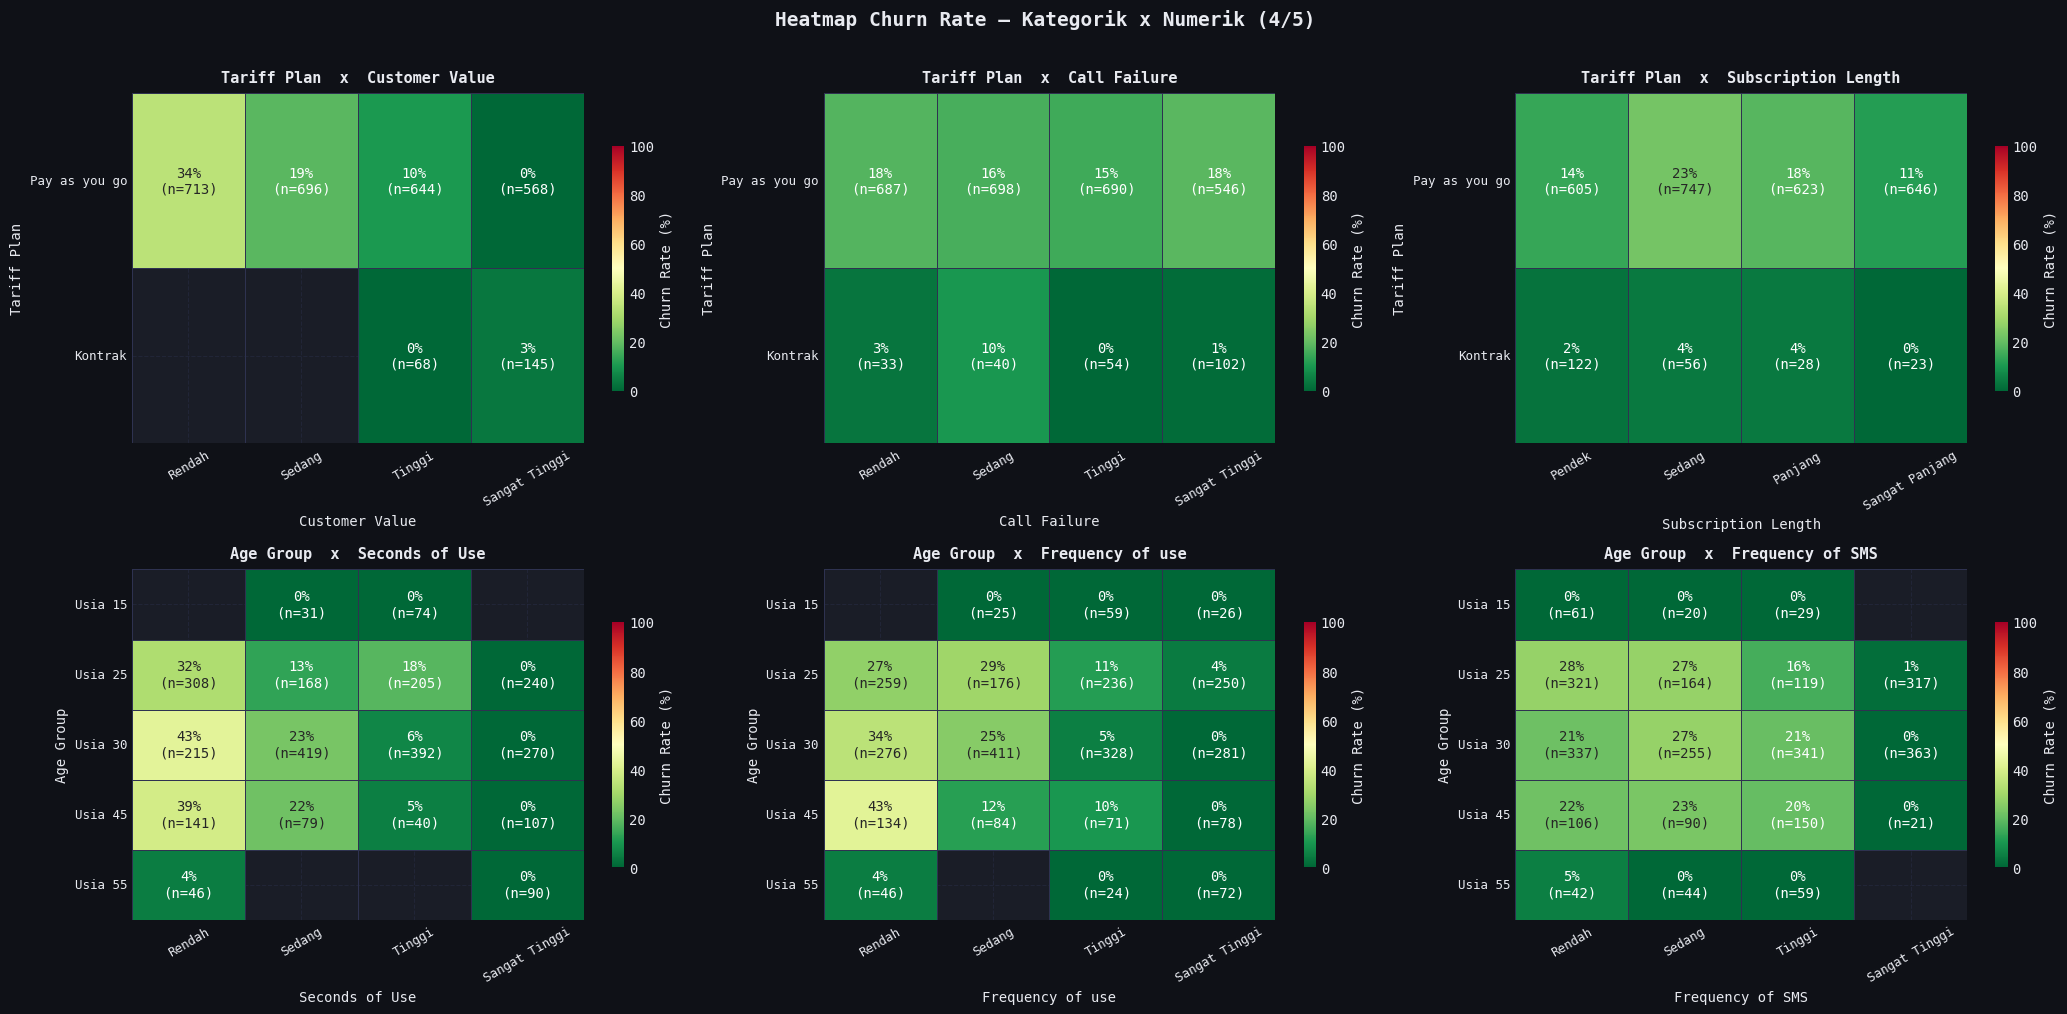

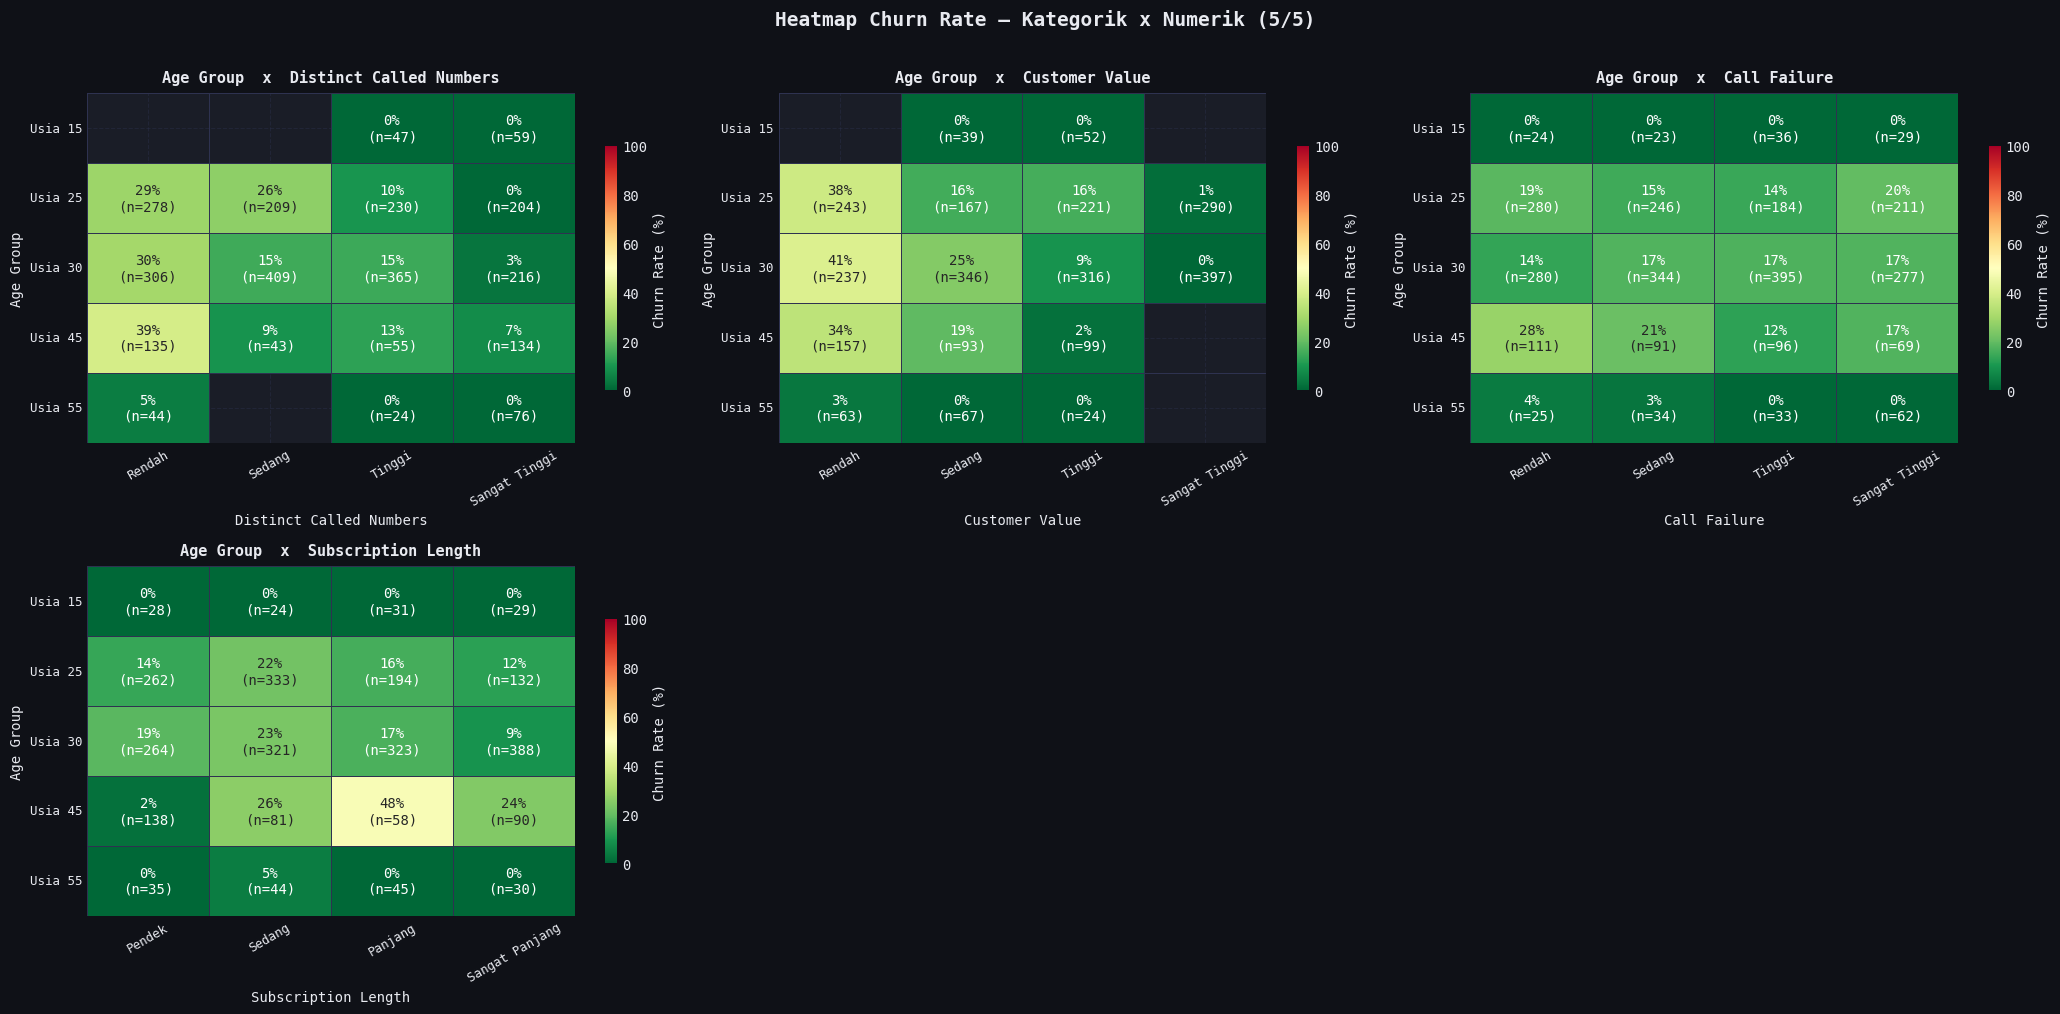

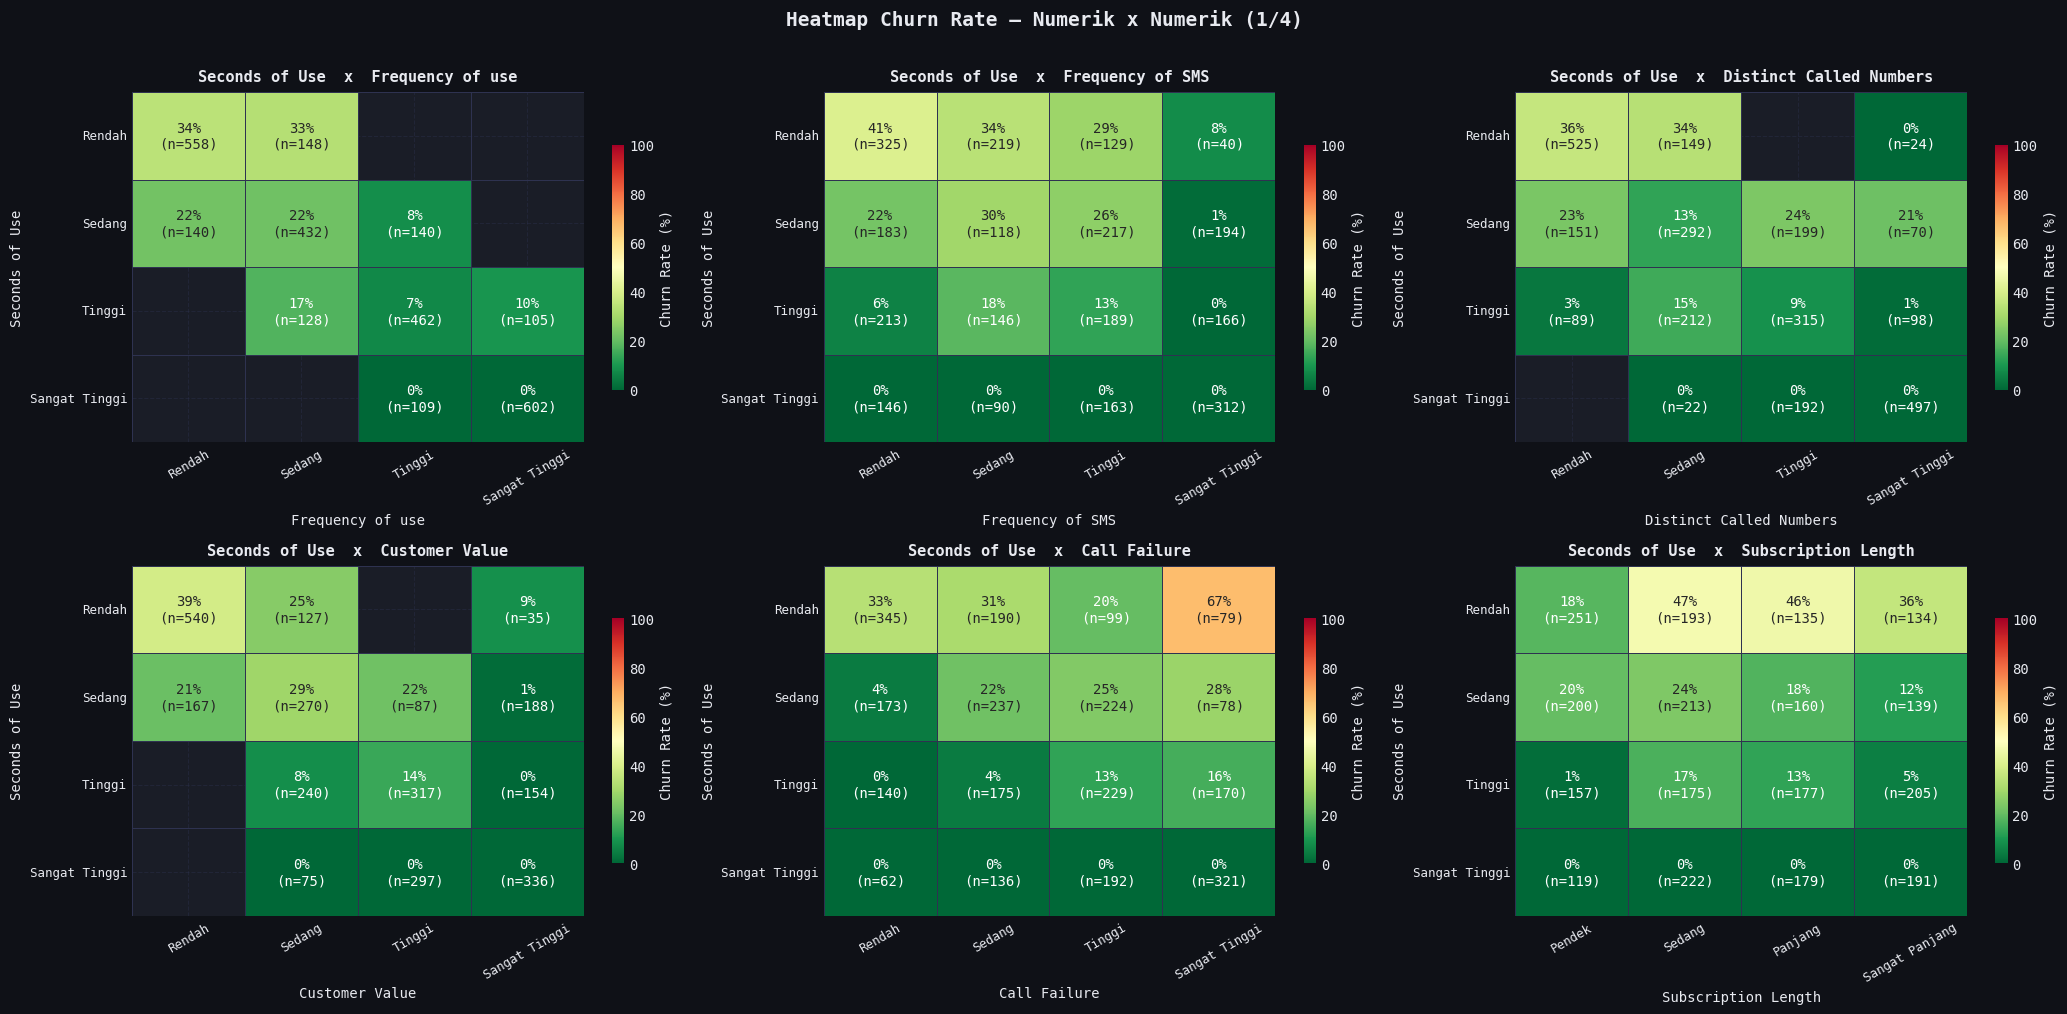

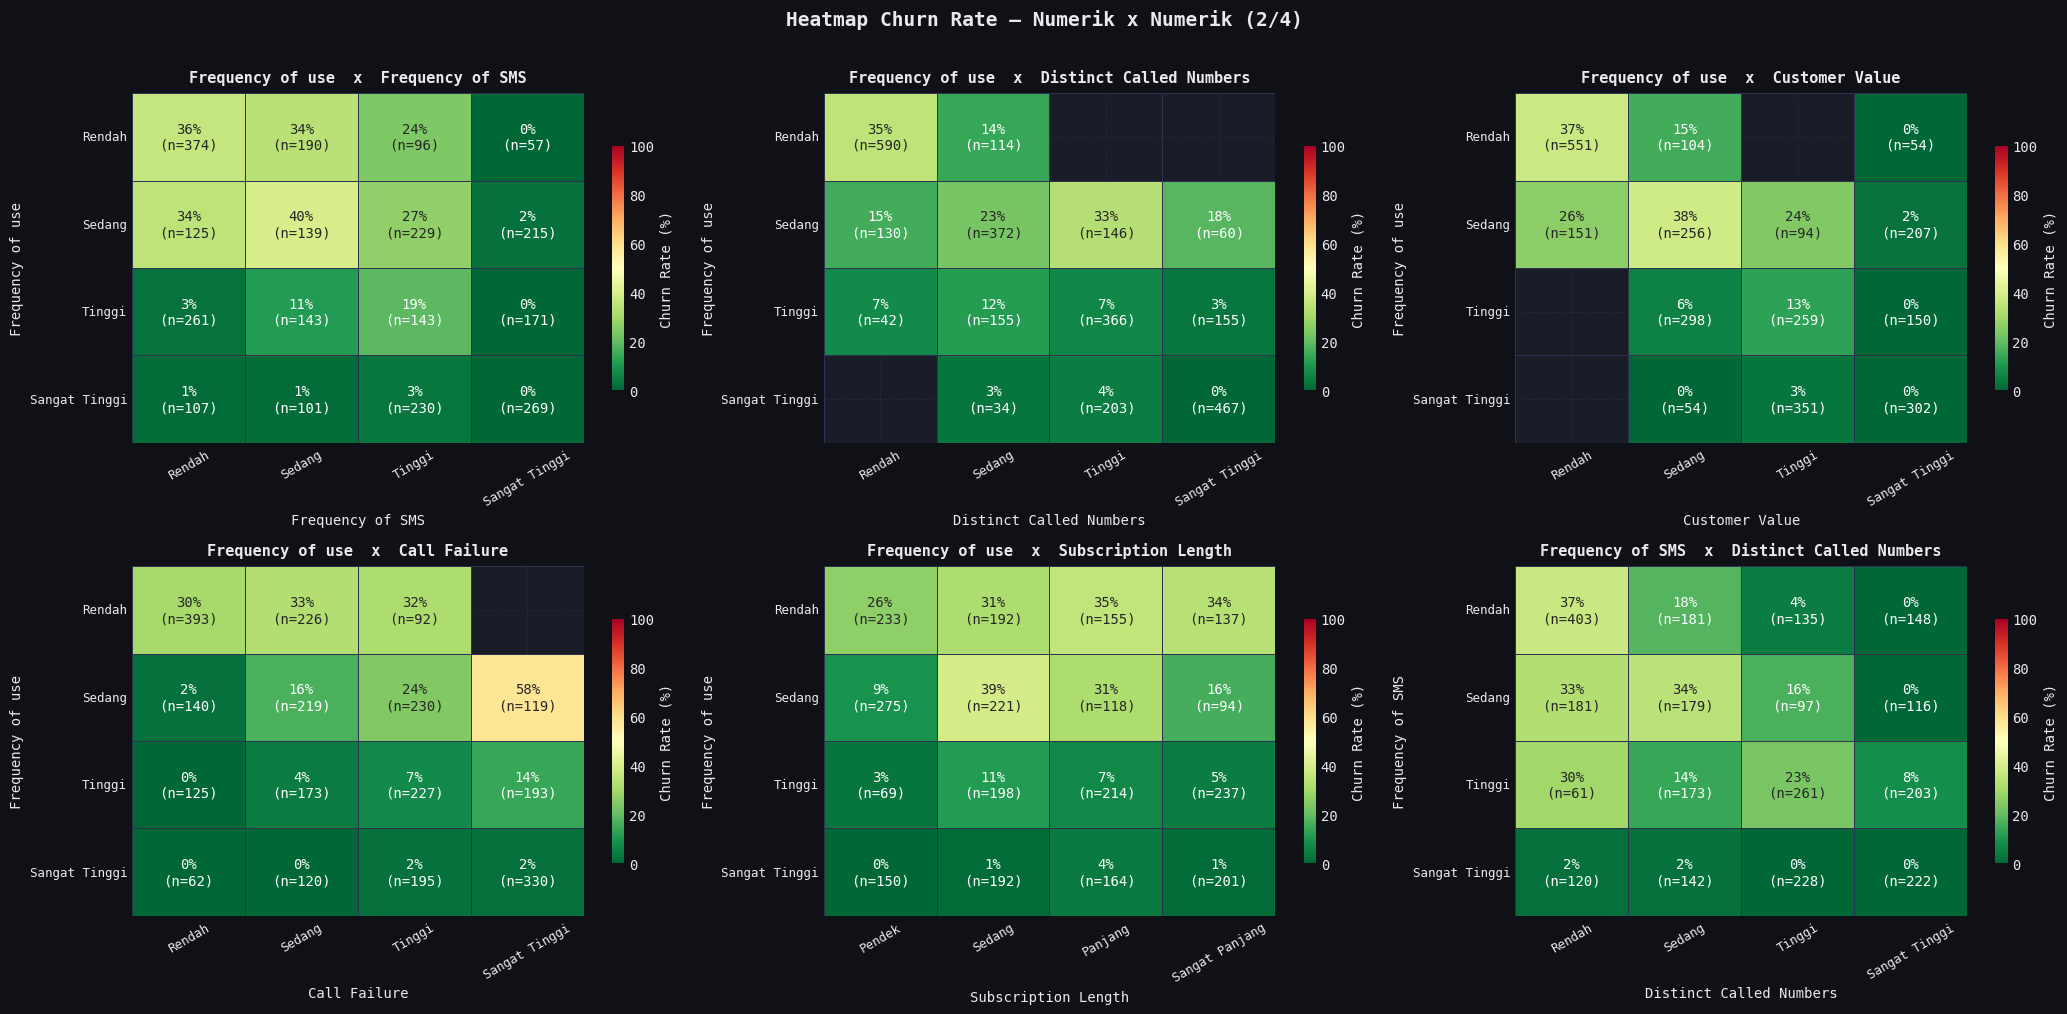

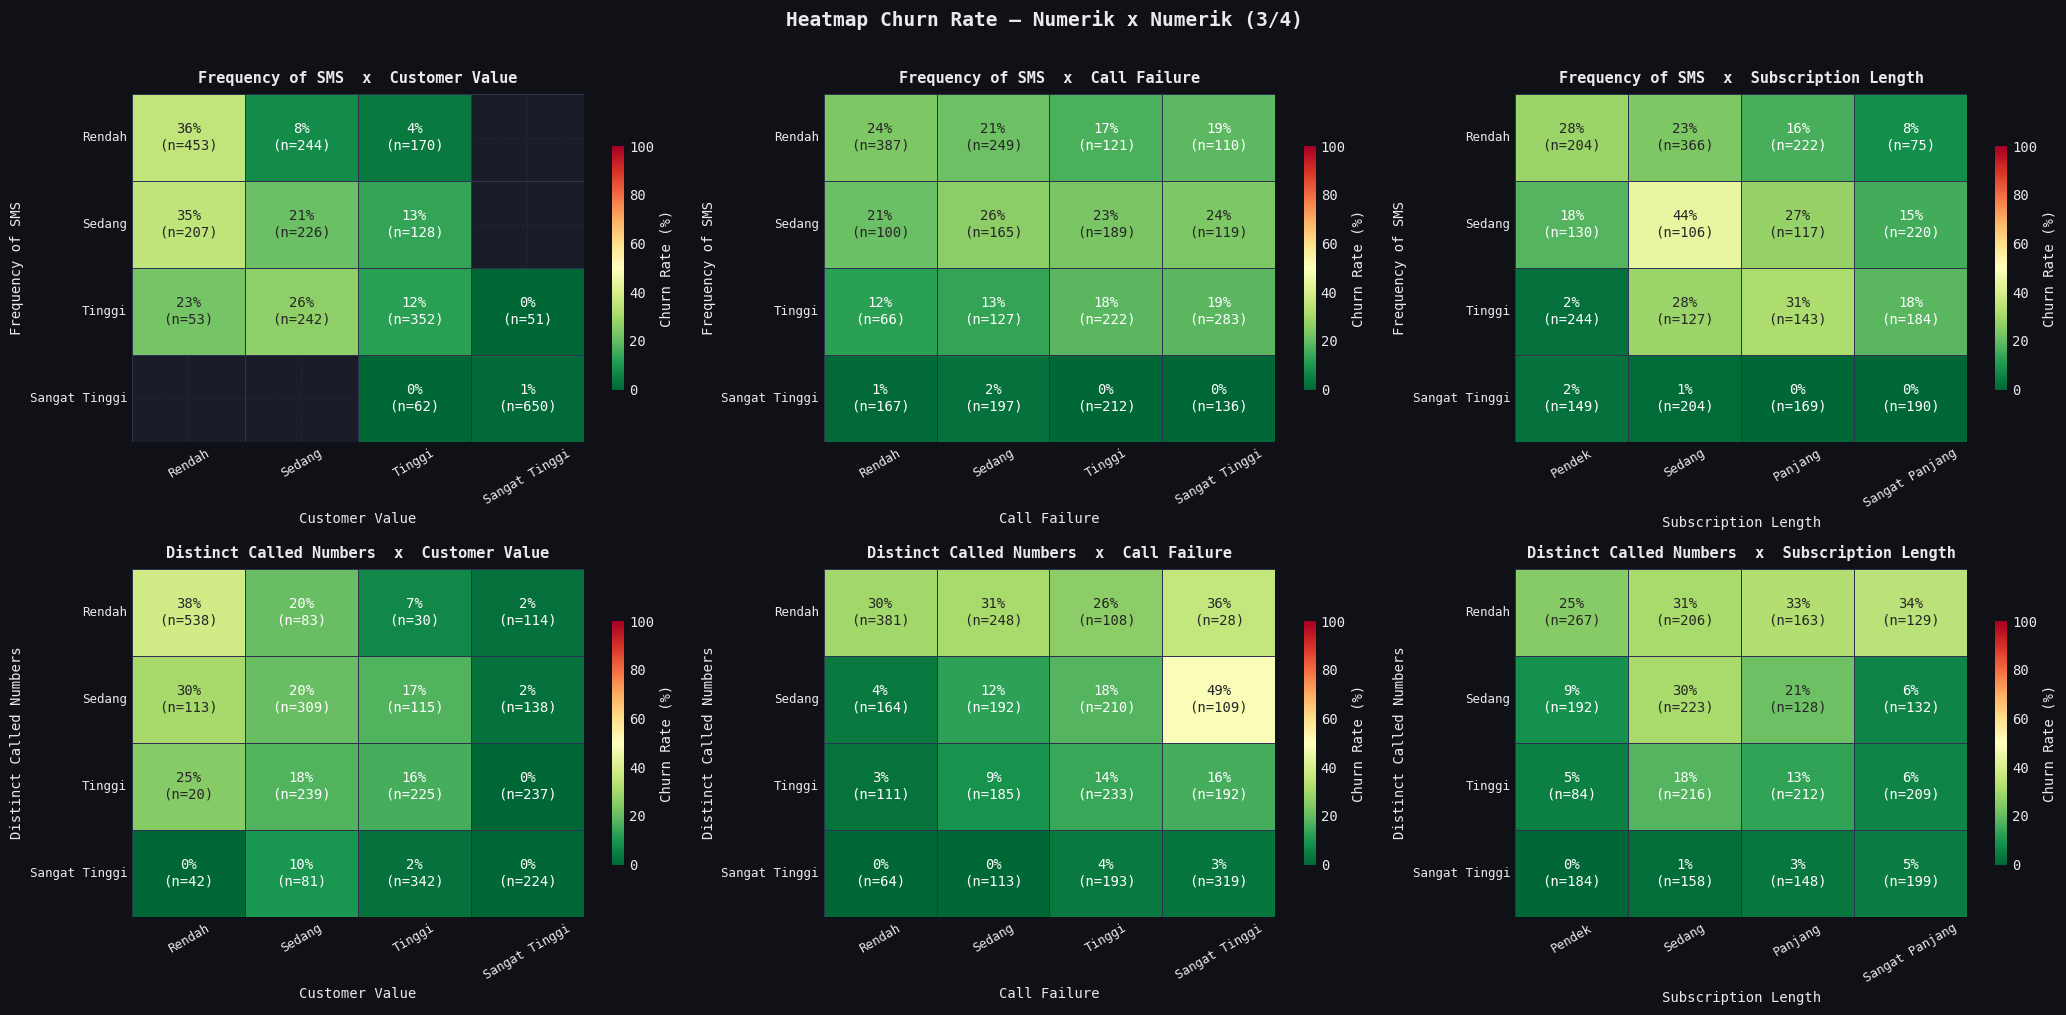

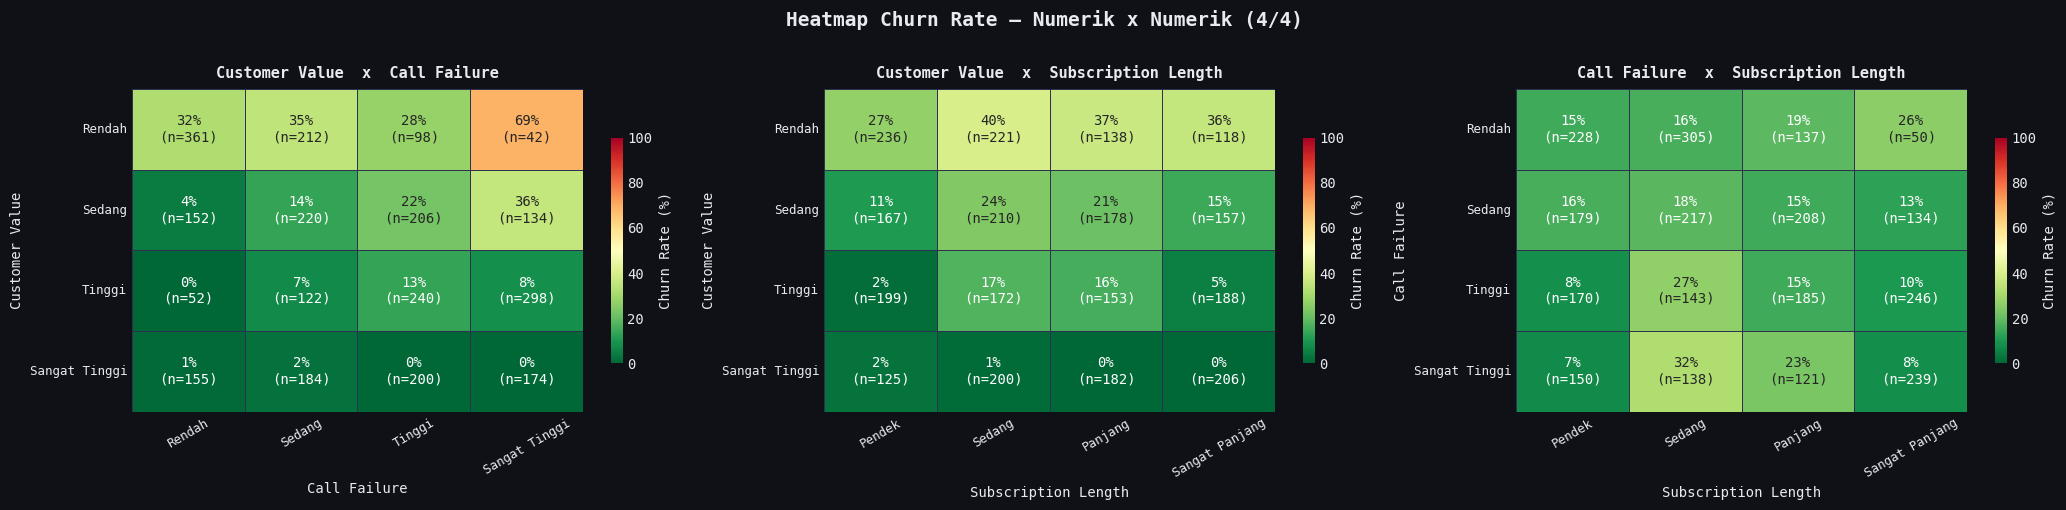

In [54]:
# ══════════════════════════════════════════════════════
# BAGIAN A: Heatmap semua kombinasi dua fitur
# (dikelompokkan: kat x kat, kat x num, num x num)
# ══════════════════════════════════════════════════════

cat_cols = [c for c in ALL_COLS if '_lbl' in c]
num_cols = [c for c in ALL_COLS if '_bin' in c]

GROUPS = {
    'Kategorik x Kategorik': list(combinations(cat_cols, 2)),
    'Kategorik x Numerik':   [(a, b) for a in cat_cols for b in num_cols],
    'Numerik x Numerik':     list(combinations(num_cols, 2)),
}

MIN_SAMPEL_HEATMAP = 20   # sel dengan sampel lebih kecil dikosongkan


def category_order(col, present):
    # Kategori mengikuti urutan tingkat, bukan urutan abjad
    if not col.endswith('_lbl'):
        return list(present)
    return [label for label in CATEGORY_LABELS[col[:-4]].values() if label in present]


PANEL_PER_GAMBAR   = 6    # panel dibagi agar teksnya terbaca

for group_name, pairs in GROUPS.items():
    for start_index in range(0, len(pairs), PANEL_PER_GAMBAR):
        page_pairs = pairs[start_index:start_index + PANEL_PER_GAMBAR]
        n_cols_plot = 3
        n_rows_plot = ceil(len(page_pairs) / n_cols_plot)
        fig, axes = plt.subplots(
            n_rows_plot, n_cols_plot,
            figsize=(7 * n_cols_plot, 5 * n_rows_plot),
            facecolor=BG_COLOR
        )
        axes = np.array(axes).flatten()
        page = start_index // PANEL_PER_GAMBAR + 1
        total_pages = ceil(len(pairs) / PANEL_PER_GAMBAR)
        fig.suptitle(f'Heatmap Churn Rate — {group_name} ({page}/{total_pages})',
                     fontsize=14, fontweight='bold', y=1.01)

        for idx, (col_a, col_b) in enumerate(page_pairs):
            ax = axes[idx]
            pivot = df_mv.pivot_table(
                values=TARGET, index=col_a,
                columns=col_b, aggfunc='mean',
                observed=True
            ) * 100
            pivot_n = df_mv.pivot_table(
                values=TARGET, index=col_a,
                columns=col_b, aggfunc='count',
                observed=True
            )
            pivot = pivot.reindex(index=category_order(col_a, pivot.index), columns=category_order(col_b, pivot.columns))
            pivot_n = pivot_n.reindex(index=pivot.index, columns=pivot.columns)

            # Sel dengan sampel kecil tidak diberi warna dan angka
            pivot = pivot.where(pivot_n >= MIN_SAMPEL_HEATMAP)
            annot_labels = np.empty(pivot.shape, dtype=object)
            for i in range(pivot.shape[0]):
                for j in range(pivot.shape[1]):
                    val = pivot.iloc[i, j]
                    annot_labels[i, j] = '' if pd.isna(val) else f'{val:.0f}%\n(n={int(pivot_n.iloc[i, j])})'

            sns.heatmap(
                pivot, annot=annot_labels, fmt='',
                cmap=CMAP_HEATMAP, ax=ax,
                linewidths=0.4, linecolor='#2e3250',
                vmin=0, vmax=100,
                cbar_kws={'shrink': 0.7, 'label': 'Churn Rate (%)'},
                annot_kws={'size': 10}
            )
            ax.set_title(f'{clean_name(col_a)}  x  {clean_name(col_b)}',
                         fontsize=11, fontweight='bold', pad=8)
            ax.set_xlabel(clean_name(col_b), fontsize=10)
            ax.set_ylabel(clean_name(col_a), fontsize=10)
            ax.tick_params(axis='x', rotation=30, labelsize=9)
            ax.tick_params(axis='y', rotation=0, labelsize=9)

        for idx in range(len(page_pairs), len(axes)):
            axes[idx].set_visible(False)

        plt.tight_layout()
        plt.show()

In [55]:
# ══════════════════════════════════════════════════════
# BAGIAN B: Tabel kombinasi dengan churn rate tertinggi
# ══════════════════════════════════════════════════════

print('=' * 72)
print('  TOP 20 KOMBINASI DUA FITUR DENGAN CHURN RATE TERTINGGI')
print(f'  Minimum sampel per sel: 20 | Rata-rata: {overall_churn*100:.1f}%')
print('=' * 72)

all_pairs = list(combinations(ALL_COLS, 2))
combo_results = []

for col_a, col_b in all_pairs:
    grp = (df_mv.groupby([col_a, col_b], observed=True)[TARGET]
           .agg(['mean', 'count'])
           .reset_index())
    grp.columns = [col_a, col_b, 'Rate', 'n']
    grp = grp[grp['n'] >= 20]  # filter sel dengan sampel terlalu kecil

    for _, row in grp.iterrows():
        combo_results.append({
            'Fitur A':    clean_name(col_a),
            'Nilai A':    str(row[col_a]),
            'Fitur B':    clean_name(col_b),
            'Nilai B':    str(row[col_b]),
            'Churn Rate': round(row['Rate'] * 100, 1),
            'n':          int(row['n']),
            'Multiplier': round(row['Rate'] / overall_churn, 1),
        })

combo_df = pd.DataFrame(combo_results).sort_values('Churn Rate', ascending=False)
top20    = combo_df.head(20)

print(f'\n{"Fitur A":<22} {"Nilai A":<16} {"Fitur B":<22} {"Nilai B":<16} '
      f'{"Rate":>7} {"n":>6} {"vs Avg":>7}')
print('-' * 96)
for _, r in top20.iterrows():
    print(f'  {r["Fitur A"]:<20} {r["Nilai A"]:<16} '
          f'{r["Fitur B"]:<20} {r["Nilai B"]:<16} '
          f'{r["Churn Rate"]:>6.1f}%  {r["n"]:>5,}  '
          f'{r["Multiplier"]:>5.1f}x')

  TOP 20 KOMBINASI DUA FITUR DENGAN CHURN RATE TERTINGGI
  Minimum sampel per sel: 20 | Rata-rata: 15.6%



Fitur A                Nilai A          Fitur B                Nilai B             Rate      n  vs Avg
------------------------------------------------------------------------------------------------
  Complains            Komplain         Frequency of use     Rendah            100.0%     65    6.4x
  Complains            Komplain         Call Failure         Rendah            100.0%     37    6.4x
  Complains            Komplain         Seconds of Use       Rendah             98.8%     81    6.3x
  Complains            Komplain         Distinct Called Numbers Rendah             98.5%     68    6.3x
  Complains            Komplain         Customer Value       Rendah             97.4%     78    6.2x
  Complains            Komplain         Seconds of Use       Tinggi             96.9%     32    6.2x
  Complains            Komplain         Subscription Length  Pendek             95.6%     45    6.1x
  Complains            Komplain         Call Failure         Sedang             93.3%    

In [56]:
# ══════════════════════════════════════════════════════
# BAGIAN C: Kombinasi dengan churn rate TERENDAH
# (churn rate terendah)
# ══════════════════════════════════════════════════════

print('\n' + '=' * 72)
print('  TOP 10 KOMBINASI DENGAN CHURN RATE TERENDAH')
print('=' * 72)

bottom10 = combo_df[combo_df['n'] >= 50].tail(10).iloc[::-1]
print(f'\n{"Fitur A":<22} {"Nilai A":<16} {"Fitur B":<22} {"Nilai B":<16} '
      f'{"Rate":>7} {"n":>6}')
print('-' * 90)
for _, r in bottom10.iterrows():
    print(f'  {r["Fitur A"]:<20} {r["Nilai A"]:<16} '
          f'{r["Fitur B"]:<20} {r["Nilai B"]:<16} '
          f'{r["Churn Rate"]:>6.1f}%  {r["n"]:>5,}')


  TOP 10 KOMBINASI DENGAN CHURN RATE TERENDAH

Fitur A                Nilai A          Fitur B                Nilai B             Rate      n
------------------------------------------------------------------------------------------
  Seconds of Use       Sangat Tinggi    Frequency of SMS     Sedang              0.0%     90
  Seconds of Use       Sangat Tinggi    Frequency of SMS     Rendah              0.0%    146
  Age Group            Usia 15          Frequency of SMS     Rendah              0.0%     61
  Age Group            Usia 55          Frequency of use     Sangat Tinggi       0.0%     72
  Seconds of Use       Tinggi           Frequency of SMS     Sangat Tinggi       0.0%    166
  Seconds of Use       Sangat Tinggi    Frequency of use     Sangat Tinggi       0.0%    602
  Seconds of Use       Sangat Tinggi    Frequency of use     Tinggi              0.0%    109
  Complains            Tanpa Komplain   Age Group            Usia 15             0.0%    111
  Complains           

## Saringan Kombinasi Dua Fitur: Ukuran Sampel dan Stabilitas

Saringan ini bersifat eksploratif. Kombinasi lolos jika punya minimal 50 baris, minimal 1% data, dan selisih *churn rate* train dan test paling besar 10 poin persen di setiap dari 20 split. Split dengan sampel terlalu kecil dihitung tidak lolos. Kandidat dipilih dari seluruh data, jadi lolos saringan bukan bukti pola berlaku di data baru, dan tidak lolos juga tidak berarti polanya tidak ada.

In [57]:
# ── Saringan Kombinasi Ekstrem


overall_churn = df[TARGET].mean()
N_TOTAL       = len(df)

# ── Parameter validasi (bisa diubah)
MIN_SAMPEL        = 50        # minimum sampel per sel
MIN_PCT_DATA      = 1.0       # minimum % dari total data
EKSTREM_THRESHOLD = 0.80      # churn rate >= 80% dianggap ekstrem tinggi
RENDAH_THRESHOLD  = 0.05      # churn rate <= 5% dianggap ekstrem rendah
DELTA_STABIL      = 0.10      # maksimum selisih train vs test
SPLIT_SEEDS       = [SEED + i for i in range(20)]  # seed untuk uji stabilitas

print('=' * 72)
print('  SARINGAN KOMBINASI EKSTREM')
print(f'  Total data    : {N_TOTAL:,} baris')
print(f'  Churn rate    : {overall_churn*100:.1f}%')
print(f'  Threshold     : ekstrem >= {EKSTREM_THRESHOLD*100:.0f}% '
      f'| rendah <= {RENDAH_THRESHOLD*100:.0f}%')
print(f'  Min sampel    : {MIN_SAMPEL} baris ({MIN_PCT_DATA}% data)')
print('=' * 72)


# ══════════════════════════════════════════════════════
# LANGKAH 1: Siapkan semua kolom (kategorik + bin)
# ══════════════════════════════════════════════════════

df_val = add_segment_columns(df)
ALL_FEAT = [f'{c}_lbl' for c in CATEGORY_LABELS] + [f'{c}_bin' for c in BIN_COLUMNS]

  SARINGAN KOMBINASI EKSTREM
  Total data    : 2,850 baris
  Churn rate    : 15.6%
  Threshold     : ekstrem >= 80% | rendah <= 5%
  Min sampel    : 50 baris (1.0% data)


In [58]:
# ══════════════════════════════════════════════════════
# LANGKAH 2: Scan semua kombinasi, deteksi yang ekstrem
# ══════════════════════════════════════════════════════

print('\n[1/3] Scanning semua kombinasi dua fitur...')

kandidat = []
all_pairs = list(combinations(ALL_FEAT, 2))

for col_a, col_b in all_pairs:
    grp = (df_val.groupby([col_a, col_b], observed=True)[TARGET]
           .agg(['mean','count'])
           .reset_index())
    grp.columns = [col_a, col_b, 'rate', 'n']
    grp = grp[grp['n'] >= MIN_SAMPEL]

    for _, row in grp.iterrows():
        rate = row['rate']
        n    = int(row['n'])
        pct  = n / N_TOTAL * 100
        if pct < MIN_PCT_DATA:
            continue
        if rate >= EKSTREM_THRESHOLD or rate <= RENDAH_THRESHOLD:
            kandidat.append({
                'col_a':  col_a,
                'val_a':  row[col_a],
                'col_b':  col_b,
                'val_b':  row[col_b],
                'rate':   rate,
                'n':      n,
                'pct':    round(pct, 2),
                'tipe':   'TINGGI' if rate >= EKSTREM_THRESHOLD else 'RENDAH',
            })

kandidat_df = pd.DataFrame(kandidat).sort_values('rate', ascending=False)
print(f'   Ditemukan {len(kandidat_df)} kombinasi ekstrem '
      f'(>{EKSTREM_THRESHOLD*100:.0f}% atau <{RENDAH_THRESHOLD*100:.0f}%) '
      f'dengan sampel >= {MIN_SAMPEL}')


[1/3] Scanning semua kombinasi dua fitur...


   Ditemukan 202 kombinasi ekstrem (>80% atau <5%) dengan sampel >= 50


In [59]:
# ══════════════════════════════════════════════════════
# LANGKAH 3: Cek stabilitas tiap kandidat di beberapa split
# ══════════════════════════════════════════════════════

print(f'\n[2/3] Mengecek stabilitas di {len(SPLIT_SEEDS)} split...\n')

hasil_saringan = []
for _, row in kandidat_df.iterrows():
    col_a, val_a = row['col_a'], row['val_a']
    col_b, val_b = row['col_b'], row['val_b']
    is_kandidat = (df_val[col_a].astype(str) == str(val_a)) & (df_val[col_b].astype(str) == str(val_b))

    selisih_terbesar = 0.0
    stabil = True
    for seed in SPLIT_SEEDS:
        train_index, test_index = train_test_split(
            df_val.index, test_size=0.2, random_state=seed, stratify=df_val[TARGET]
        )
        segmen_train = df_val.loc[train_index][is_kandidat.loc[train_index]]
        segmen_test = df_val.loc[test_index][is_kandidat.loc[test_index]]
        if len(segmen_train) < 10 or len(segmen_test) < 5:
            stabil = False
            continue
        selisih = abs(segmen_train[TARGET].mean() - segmen_test[TARGET].mean())
        selisih_terbesar = max(selisih_terbesar, selisih)
        if selisih > DELTA_STABIL:
            stabil = False

    hasil_saringan.append({
        'Fitur A': clean_name(col_a),
        'Nilai A': str(val_a),
        'Fitur B': clean_name(col_b),
        'Nilai B': str(val_b),
        'Tipe': row['tipe'],
        'Rate': round(row['rate'] * 100, 1),
        'n': row['n'],
        'Selisih terbesar': round(selisih_terbesar * 100, 1),
        'Lolos': stabil,
    })

hasil_df = pd.DataFrame(hasil_saringan)
lolos_df = hasil_df[hasil_df['Lolos']]
lolos_tinggi = lolos_df[lolos_df['Tipe'] == 'TINGGI'].sort_values(['Rate', 'n'], ascending=[False, False])
lolos_rendah = lolos_df[lolos_df['Tipe'] == 'RENDAH'].sort_values(['Rate', 'n'], ascending=[True, False])


[2/3] Mengecek stabilitas di 20 split...



In [60]:
# ══════════════════════════════════════════════════════
# LANGKAH 4: Ringkasan
# ══════════════════════════════════════════════════════

print('[3/3] Ringkasan:\n')
print(f'  Total kandidat ekstrem   : {len(hasil_df):>4}')
print(f'  Lolos saringan           : {len(lolos_df):>4}')
print(f'  Tidak lolos              : {(~hasil_df["Lolos"]).sum():>4}')
print(f'  Lolos, churn tinggi      : {len(lolos_tinggi):>4} dari {(hasil_df["Tipe"] == "TINGGI").sum()} kandidat')
print(f'  Lolos, churn rendah      : {len(lolos_rendah):>4} dari {(hasil_df["Tipe"] == "RENDAH").sum()} kandidat')

kolom_tampil = ['Fitur A', 'Nilai A', 'Fitur B', 'Nilai B', 'Rate', 'n', 'Selisih terbesar']
print('\n  Kombinasi churn tinggi yang lolos:')
print(lolos_tinggi[kolom_tampil].to_string(index=False))
print('\n  Kandidat churn tinggi yang tidak lolos:')
print(hasil_df[(hasil_df['Tipe'] == 'TINGGI') & (~hasil_df['Lolos'])].sort_values('Rate', ascending=False)[kolom_tampil].to_string(index=False))
print('\n  15 kombinasi churn terendah yang lolos:')
print(lolos_rendah.head(15)[kolom_tampil].to_string(index=False))

[3/3] Ringkasan:

  Total kandidat ekstrem   :  202
  Lolos saringan           :  171
  Tidak lolos              :   31
  Lolos, churn tinggi      :    5 dari 16 kandidat
  Lolos, churn rendah      :  166 dari 186 kandidat

  Kombinasi churn tinggi yang lolos:
  Fitur A  Nilai A                 Fitur B Nilai B  Rate  n  Selisih terbesar
Complains Komplain        Frequency of use  Rendah 100.0 65               0.0
Complains Komplain          Seconds of Use  Rendah  98.8 81               7.7
Complains Komplain Distinct Called Numbers  Rendah  98.5 68              10.0
Complains Komplain        Frequency of use  Sedang  92.9 98               9.5
Complains Komplain     Subscription Length  Sedang  92.7 82               9.7

  Kandidat churn tinggi yang tidak lolos:
  Fitur A  Nilai A                 Fitur B       Nilai B  Rate   n  Selisih terbesar
Complains Komplain          Customer Value        Rendah  97.4  78              13.3
Complains Komplain                  Status     Non-aktif  

## **Hasil Saringan Kombinasi Dua Fitur**

Kombinasi dua fitur dipakai untuk eksplorasi. Dari 202 kandidat ekstrem, 171 lolos saringan: 5 dari 16 kandidat churn tinggi, dan 166 kandidat churn rendah. Syarat saringan ada di judul section ini, dan tidak ada koreksi uji berganda.

---

### **Kombinasi Churn Tinggi**

Semua kombinasi churn tinggi yang lolos melibatkan komplain. `Complains` x `Frequency_of_use` Rendah mencatat 100,0% (n=65), `Complains` x `Seconds_of_Use` Rendah 98,8% (n=81), dan `Complains` x `Distinct_Called_Numbers` Rendah 98,5% (n=68).

Kombinasi lain yang tinggi tetapi tidak lolos antara lain `Complains` x `Non-aktif` (89,3%, n=149). Ini berarti selisih train dan test-nya melebihi batas di sebagian split, bukan berarti polanya tidak ada.

`Non-aktif` x `Seconds_of_Use` Tinggi mencatat 92,9%, tetapi hanya 28 baris, jadi tidak memenuhi syarat sampel minimal.

### **Asosiasi Komplain Tidak Berlaku Merata**

Komplain dengan `Seconds_of_Use` Sangat Tinggi punya churn rate 0% (0 dari 22 baris), dan komplain pada Kontrak punya 31,6% (6 dari 19 baris). Keduanya bersampel kecil, tetapi menunjukkan bahwa tingginya churn pada baris komplain tidak berlaku di semua kelompok.

### **Kombinasi Churn Rendah**

Dari 166 kombinasi churn rendah yang lolos, 117 melibatkan penggunaan Sangat Tinggi, dan 85 punya churn rate 0%, misalnya `Aktif` x `Seconds_of_Use` Sangat Tinggi (n=711). Banyak kombinasi ini mengulang pola yang sama, jadi tidak dibaca sebagai temuan terpisah.

### **Korelasi Antarfitur**

`Seconds_of_Use` dan `Frequency_of_use` berkorelasi tinggi (Spearman 0,934). `Distinct_Called_Numbers` berkorelasi dengan keduanya (Spearman 0,752 dan 0,816). `Customer_Value` berkorelasi dengan `Frequency_of_SMS` (Spearman 0,776, Pearson 0,923). Asosiasi lemah `Call_Failure` dibahas di kesimpulan hubungan fitur.

---

## **Hipotesis yang Perlu Diuji**

Temuan di atas bersifat asosiatif, jadi berikut ini adalah hipotesis, bukan rekomendasi yang siap dijalankan:

1. **Komplain:** menangani komplain lebih cepat bisa menurunkan churn. Ini perlu diuji dengan eksperimen retensi.
2. **Status non-aktif:** baris non-aktif bisa menjadi kelompok awal untuk program retensi. Cara `Status` ditentukan perlu dipastikan lebih dulu.
3. **Penggunaan rendah:** program yang mendorong penggunaan bisa menurunkan churn, tetapi penggunaan rendah bisa juga hanya gejala.

---

## **Keterbatasan**

*   Menurut dokumentasi UCI, fitur berasal dari 9 bulan pertama dan churn diukur di akhir bulan ke-12. Data ini tetap tidak bisa membuktikan sebab-akibat.
*   Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan.
*   Saringan tidak mengoreksi banyaknya kombinasi yang diperiksa.

# C. Pertanyaan Bisnis

Bagian ini merangkum temuan menjadi empat pertanyaan, dan menjawabnya dengan besar efek serta rentangnya, bukan p-value saja.

**Status: eksploratif.** Pertanyaan dibuat setelah melihat data yang sama, jadi jawabannya bukan bukti hipotesis dan bukan bukti sebab-akibat. Rentang mengasumsikan tiap baris independen, mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan.

In [61]:
def churn_gap(flag, label_group, label_other):
    # Selisih churn rate dua kelompok dengan interval kepercayaan 95% metode Newcombe
    group, other = df.loc[flag, TARGET], df.loc[~flag, TARGET]
    low, high = confint_proportions_2indep(group.sum(), len(group), other.sum(), len(other),
                                           method='newcomb', compare='diff')
    return {
        'Perbandingan': f'{label_group} vs {label_other}',
        'n kelompok': len(group),
        'n pembanding': len(other),
        'Churn kelompok (%)': round(group.mean() * 100, 1),
        'Churn pembanding (%)': round(other.mean() * 100, 1),
        'Selisih (poin persen)': round((group.mean() - other.mean()) * 100, 1),
        'IK 95% bawah': round(low * 100, 1),
        'IK 95% atas': round(high * 100, 1),
    }


seconds_quartile = pd.qcut(df['Seconds_of_Use'], q=4, labels=QUARTILE_LABELS, duplicates='drop')
is_low_usage = seconds_quartile == 'Rendah'
question_table = pd.DataFrame([
    churn_gap(df['Complains'] == 1, 'Komplain', 'Tanpa komplain'),
    churn_gap(df['Status'] == 2, 'Non-aktif', 'Aktif'),
    churn_gap(is_low_usage, 'Seconds_of_Use kuartil terendah', 'Kuartil lainnya'),
])
print(question_table.to_string(index=False))

                                      Perbandingan  n kelompok  n pembanding  Churn kelompok (%)  Churn pembanding (%)  Selisih (poin persen)  IK 95% bawah  IK 95% atas
                        Komplain vs Tanpa komplain         230          2620                82.6                   9.8                   72.8          67.3         77.3
                                Non-aktif vs Aktif         684          2166                47.5                   5.6                   41.9          38.1         45.8
Seconds_of_Use kuartil terendah vs Kuartil lainnya         713          2137                34.6                   9.3                   25.3          21.7         29.1


### Pertanyaan 1: Seberapa besar selisih churn antara baris dengan dan tanpa komplain?

*Churn rate* 82,6% berbanding 9,8%, selisih 72,8 poin persen (IK 95%: 67,3 sampai 77,3). Selisih ini paling besar di antara ketiga perbandingan. Data ini belum menunjukkan bahwa menangani komplain akan menurunkan *churn*.

### Pertanyaan 2: Seberapa besar selisih churn antara baris non-aktif dan aktif?

*Churn rate* 47,5% berbanding 5,6%, selisih 41,9 poin persen (IK 95%: 38,1 sampai 45,8). Cara `Status` ditentukan dan definisi *churn* tidak dijelaskan dokumentasi UCI, jadi hubungan keduanya perlu dibaca hati-hati.

### Pertanyaan 3: Seberapa besar selisih churn antara kuartil terendah `Seconds_of_Use` dan kuartil lainnya?

*Churn rate* 34,6% berbanding 9,3%, selisih 25,3 poin persen (IK 95%: 21,7 sampai 29,1). Penggunaan rendah bisa menjadi penyebab atau hanya gejala, dan data ini tidak bisa membedakannya.

In [62]:
N_BOOTSTRAP = 2000

# Gabungan tiga sinyal
is_signal = (df['Complains'] == 1) | (df['Status'] == 2) | is_low_usage
concentration = pd.Series({
    'Baris': int(is_signal.sum()),
    'Porsi baris (%)': round(is_signal.mean() * 100, 1),
    'Churn rate (%)': round(df.loc[is_signal, TARGET].mean() * 100, 1),
    'Porsi dari baris churn (%)': round(df.loc[is_signal, TARGET].sum() / df[TARGET].sum() * 100, 1),
    'Porsi dari total Customer_Value (%)': round(df.loc[is_signal, 'Customer_Value'].sum() / df['Customer_Value'].sum() * 100, 1),
})
print(concentration.to_string())

# Nilai pada baris churn, dengan rentang bootstrap persentil
values = df['Customer_Value'].to_numpy()
is_churn = df[TARGET].to_numpy() == 1
rng_bootstrap = np.random.default_rng(SEED)
share_samples, gap_samples = [], []
for _ in range(N_BOOTSTRAP):
    sample = rng_bootstrap.integers(0, len(df), len(df))
    sample_values, sample_churn = values[sample], is_churn[sample]
    share_samples.append(sample_values[sample_churn].sum() / sample_values.sum() * 100)
    gap_samples.append(np.median(sample_values[~sample_churn]) - np.median(sample_values[sample_churn]))

share_low, share_high = np.percentile(share_samples, [2.5, 97.5])
gap_low, gap_high = np.percentile(gap_samples, [2.5, 97.5])
print(f"\nPorsi Customer_Value pada baris churn: {values[is_churn].sum() / values.sum() * 100:.1f}% (rentang {share_low:.1f} sampai {share_high:.1f})")
print(f"Median Customer_Value: churn {np.median(values[is_churn]):.1f}, tidak churn {np.median(values[~is_churn]):.1f}, "
      f"selisih {np.median(values[~is_churn]) - np.median(values[is_churn]):.1f} (rentang {gap_low:.1f} sampai {gap_high:.1f})")

Baris                                  992.0
Porsi baris (%)                         34.8
Churn rate (%)                          40.8
Porsi dari baris churn (%)              90.8
Porsi dari total Customer_Value (%)     11.0



Porsi Customer_Value pada baris churn: 4.4% (rentang 3.8 sampai 5.0)
Median Customer_Value: churn 102.6, tidak churn 271.5, selisih 169.0 (rentang 148.6 sampai 188.3)


### Pertanyaan 4: Di mana churn dan nilai terkonsentrasi?

Gabungan `Complains=1`, `Status=2`, dan `Seconds_of_Use` kuartil terendah mencakup 992 baris (34,8%), dengan *churn rate* 40,8%. Gabungan ini memuat 90,8% baris *churn*, tetapi hanya 11,0% total `Customer_Value`. Sinyalnya dipilih setelah melihat *churn* pada data yang sama, jadi angka ini bukan kemampuan prediksi.

Baris *churn* memegang 4,4% total `Customer_Value` (rentang 3,8 sampai 5,0), dengan median 102,6 berbanding 271,5 pada baris tidak *churn*. Jadi, pada data ini *churn* terkonsentrasi pada baris dengan skor nilai rendah.

`Customer_Value` tidak punya rumus dan satuan yang dijelaskan dokumentasi UCI, jadi ini dibaca sebagai skor relatif, bukan uang. Gabungan peluang *churn* dan nilai lebih tepat dibahas setelah ada model.

# D. Ringkasan Eksekutif

**Konteks data:** Analisis memakai 2.850 baris setelah 300 duplikat persis dihapus dari 3.150 baris. Menurut dokumentasi UCI, fitur berasal dari **9 bulan pertama**, `Churn` diukur di **akhir bulan ke-12**, dan tiap baris mewakili satu pelanggan. Seluruh temuan bersifat **asosiatif, bukan kausal**.

---

## 1. `Complains` punya asosiasi terkuat
Baris dengan komplain punya *churn rate* **82,6%**, berbanding **9,8%** tanpa komplain (selisih 72,8 poin persen (IK 95%: 67,3 sampai 77,3), dan 5,3x rata-rata 15,6%). Sebanyak 19 dari 20 kombinasi tertinggi di tabel peringkat melibatkan komplain, jadi ini satu temuan yang berulang, bukan 19 temuan terpisah.

Asosiasi ini tidak berlaku merata: komplain dengan `Seconds_of_Use` Sangat Tinggi punya 0% (0 dari 22 baris).

## 2. `Status` non-aktif punya asosiasi kuat kedua
`Status=2` punya *churn rate* **47,5%**, berbanding 5,6% pada baris aktif (selisih 41,9 poin persen (IK 95%: 38,1 sampai 45,8)). Sebanyak 149 dari 230 baris komplain (65%) juga non-aktif (korelasi 0,28). Gabungan keduanya (n=765) punya *churn rate* 49,9%. Cara `Status` ditentukan tidak dijelaskan dokumentasi UCI, jadi hubungan ini perlu dibaca hati-hati.

## 3. Penggunaan rendah berasosiasi dengan churn
Kuartil terendah `Seconds_of_Use` punya *churn rate* 34,6%, berbanding 9,3% pada kuartil lainnya (selisih 25,3 poin persen (IK 95%: 21,7 sampai 29,1)). Kuartil terendah `Seconds_of_Use`, `Frequency_of_use`, dan `Distinct_Called_Numbers` punya *churn rate* 1,9x sampai 2,2x rata-rata, dan kuartil tertingginya 0% sampai 2,3%. Ketiganya saling berkorelasi (Spearman 0,752 sampai 0,934). `Frequency_of_SMS` berkorelasi lemah dengan fitur itu (Spearman sekitar 0,29), polanya tidak searah, dan lebih berkaitan dengan `Customer_Value` (Spearman 0,776).

## 4. Churn terkonsentrasi pada nilai rendah
Baris *churn* hanya memegang **4,4%** total `Customer_Value` (rentang 3,8 sampai 5,0), dengan median 102,6 berbanding 271,5 pada baris tidak *churn*. `Customer_Value` adalah skor hasil hitungan tanpa rumus yang dijelaskan dokumentasi UCI, jadi angka ini dibaca sebagai porsi relatif, bukan uang.

## 5. Gabungan sinyal
Gabungan `Complains=1 OR Status=2 OR Seconds_of_Use Rendah`:

| Metrik | Nilai |
|---|---|
| Baris pada segmen | 992 (34,8% dari data) |
| *Churn rate* segmen | 40,8% (2,6x rata-rata) |
| Porsi dari seluruh baris *churn* | 90,8% |
| Porsi dari total `Customer_Value` | 11,0% |

Angka ini deskriptif. Sinyalnya dipilih setelah melihat *churn* pada data yang sama, jadi bukan kemampuan prediksi dan bukan estimasi hasil intervensi.

## 6. Fitur dengan asosiasi lemah atau pola khusus
`Call_Failure` hampir sama di semua kuartil (14,1% sampai 16,9%). `Subscription_Length` dan `Age_Group` polanya tidak searah. `Charge_Amount` dan `Tariff_Plan` berasosiasi, tetapi level atau kategorinya timpang. Keputusan fitur diambil saat modeling.

---

## Hipotesis yang perlu diuji
- Menangani komplain lebih cepat bisa menurunkan *churn*.
- Baris non-aktif bisa menjadi kelompok awal program retensi, setelah cara `Status` ditentukan dipastikan.
- Mendorong penggunaan bisa menurunkan *churn*, tetapi penggunaan rendah bisa juga hanya gejala.

Ketiganya perlu diuji, misalnya dengan eksperimen retensi.

## Limitasi
- Data ini tidak bisa membuktikan sebab-akibat.
- Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan, dan uji statistik mengasumsikan tiap baris independen.
- Beberapa temuan bertumpu pada sampel kecil (n<50), dan kombinasi yang diperiksa banyak tanpa koreksi uji berganda.